In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 64
GENERATOR_HIDDEN_DIM = 1024
DISCRIMINATOR_HIDDEN_DIM = 2048

# GAN-specific hyperparameters
LR_G = 8e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator hidden dimension: {GENERATOR_HIDDEN_DIM}")
print(f"Discriminator hidden dimension: {DISCRIMINATOR_HIDDEN_DIM}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Generator hidden dimension: 1024
Discriminator hidden dimension: 2048
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """
    Generator network that creates fake data from random noise.
    
    The Generator takes random noise as input and transforms it into
    data that should look like our real moon-shaped data.
    """
    
    def __init__(self, noise_dim, output_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: noise -> hidden
            nn.Linear(noise_dim, hidden_dim),
            nn.ReLU(),
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            # Output layer: hidden -> data
            nn.Linear(hidden_dim, output_dim),
            # No activation on output - we want raw coordinates
        )
    
    def forward(self, noise):
        """
        Transform noise into fake data.
        
        Args:
            noise: Random noise tensor of shape (batch_size, noise_dim)
        
        Returns:
            fake_data: Generated data of shape (batch_size, output_dim)
        """
        return self.net(noise)


In [6]:
class Discriminator(nn.Module):
    """
    Discriminator network that distinguishes between real and fake data.
    
    The Discriminator takes data (real or fake) as input and outputs
    a probability that the data is real (closer to 1) or fake (closer to 0).
    """
    
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: data -> hidden
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),  # LeakyReLU helps with gradient flow
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),

            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            # Output layer: hidden -> probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()  # Output probability between 0 and 1
        )
    
    def forward(self, data):
        """
        Classify data as real or fake.
        
        Args:
            data: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            probability: Probability that data is real (0-1)
        """
        return self.net(data)


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, INPUT_DIM, GENERATOR_HIDDEN_DIM)
discriminator = Discriminator(INPUT_DIM, DISCRIMINATOR_HIDDEN_DIM)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 2,969,360
Discriminator parameters: 10,002,433
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Linear(in_features=64, out_features=1024, bias=True)
    (1): ReLU()
    (2): Linear(in_features=1024, out_features=1024, bias=True)
    (3): ReLU()
    (4): Linear(in_features=1024, out_features=1024, bias=True)
    (5): ReLU()
    (6): Linear(in_features=1024, out_features=784, bias=True)
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=2048, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=2048, out_features=1, bias=True)
    (7):

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Generated data as numpy array
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate random noise with correct device and dtype
        noise = torch.randn(num_samples, NOISE_DIM, device=device, dtype=torch.float32)
        
        # Generate fake data
        fake_samples = generator(noise)
        
        # Convert to numpy for visualization
        fake_samples = fake_samples.cpu().numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.377767	G_loss: 0.702727
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.332998	G_loss: 0.854891
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.378456	G_loss: 0.989591
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.341749	G_loss: 0.795819
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.174091	G_loss: 1.113682
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.869633	G_loss: 1.046695
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.093053	G_loss: 3.234693
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.283076	G_loss: 1.419153
Epoch: 1 [51200/60000 (85%)]	D_loss: 0.632658	G_loss: 2.681965
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.221249	G_loss: 2.007730
====> Epoch: 1 Train D_loss: 1.3330, Train G_loss: 1.3702
====> Epoch: 1 Val D_loss: 1.4627, Val G_loss: 0.5221
📈 Epoch 1 Summary:
   Train D Loss: 1.3330, Val D Loss: 1.4627
   Train G Loss: 1.3702, Val G Loss: 0.5221

📊 Epoch 2/100
------------------------

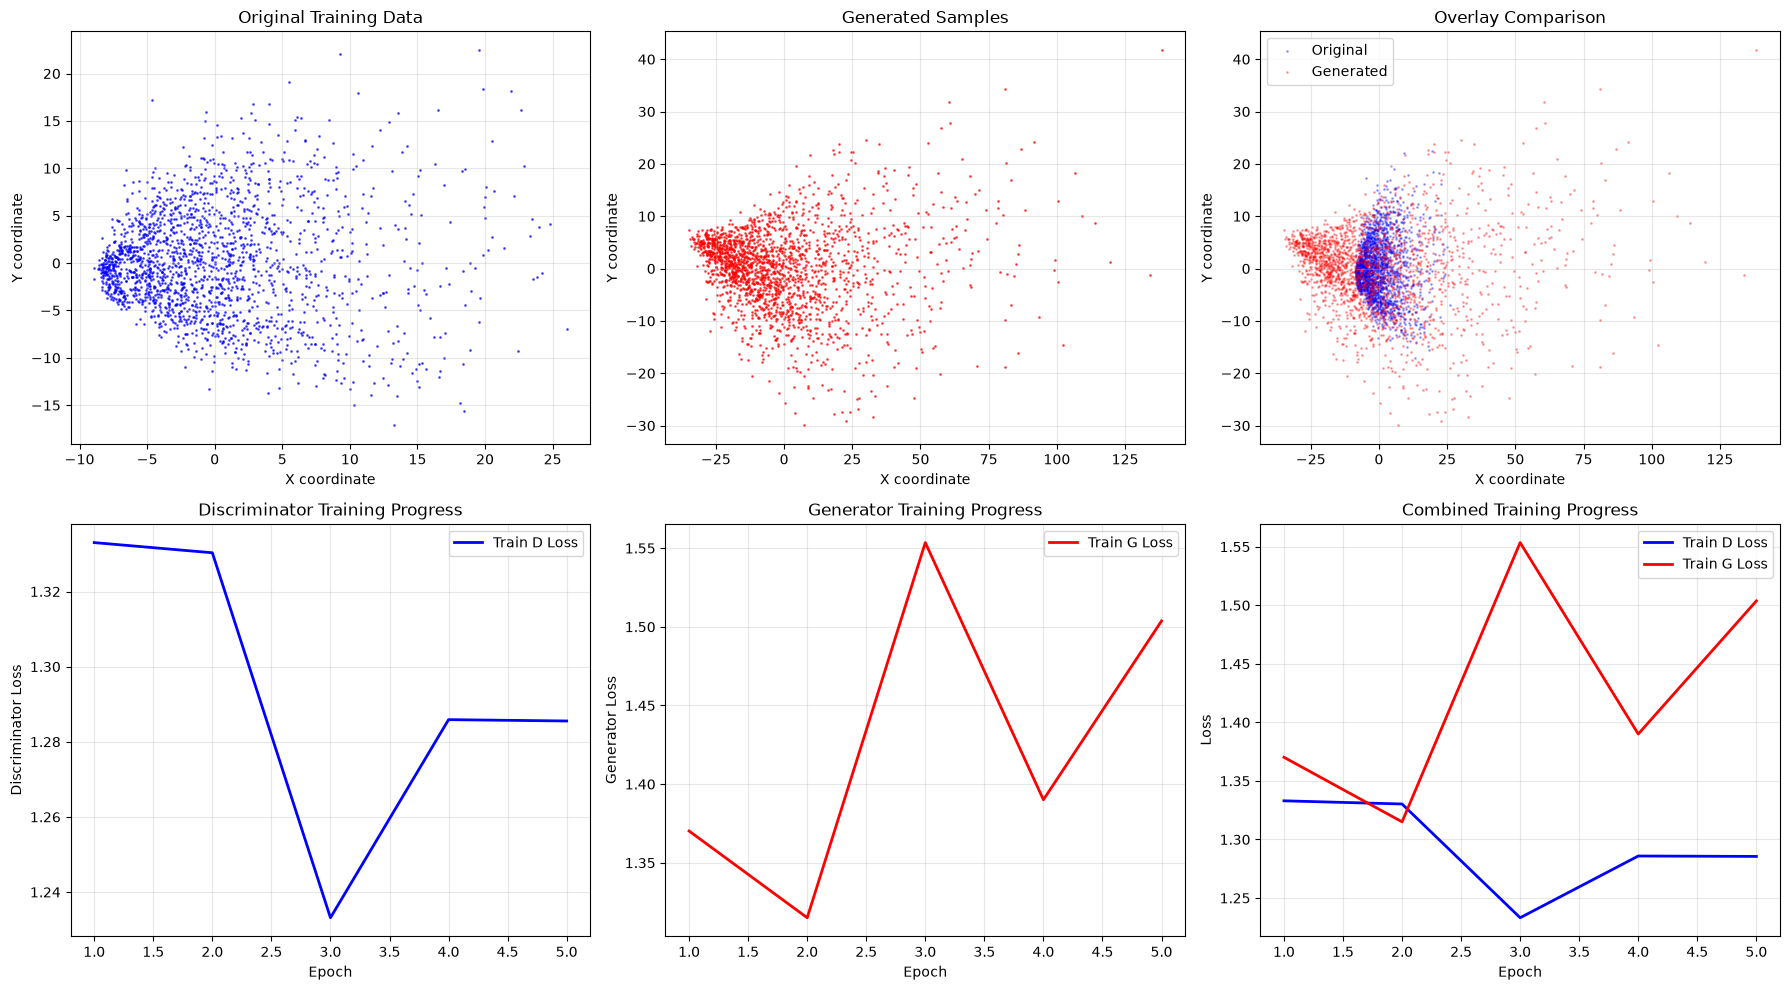

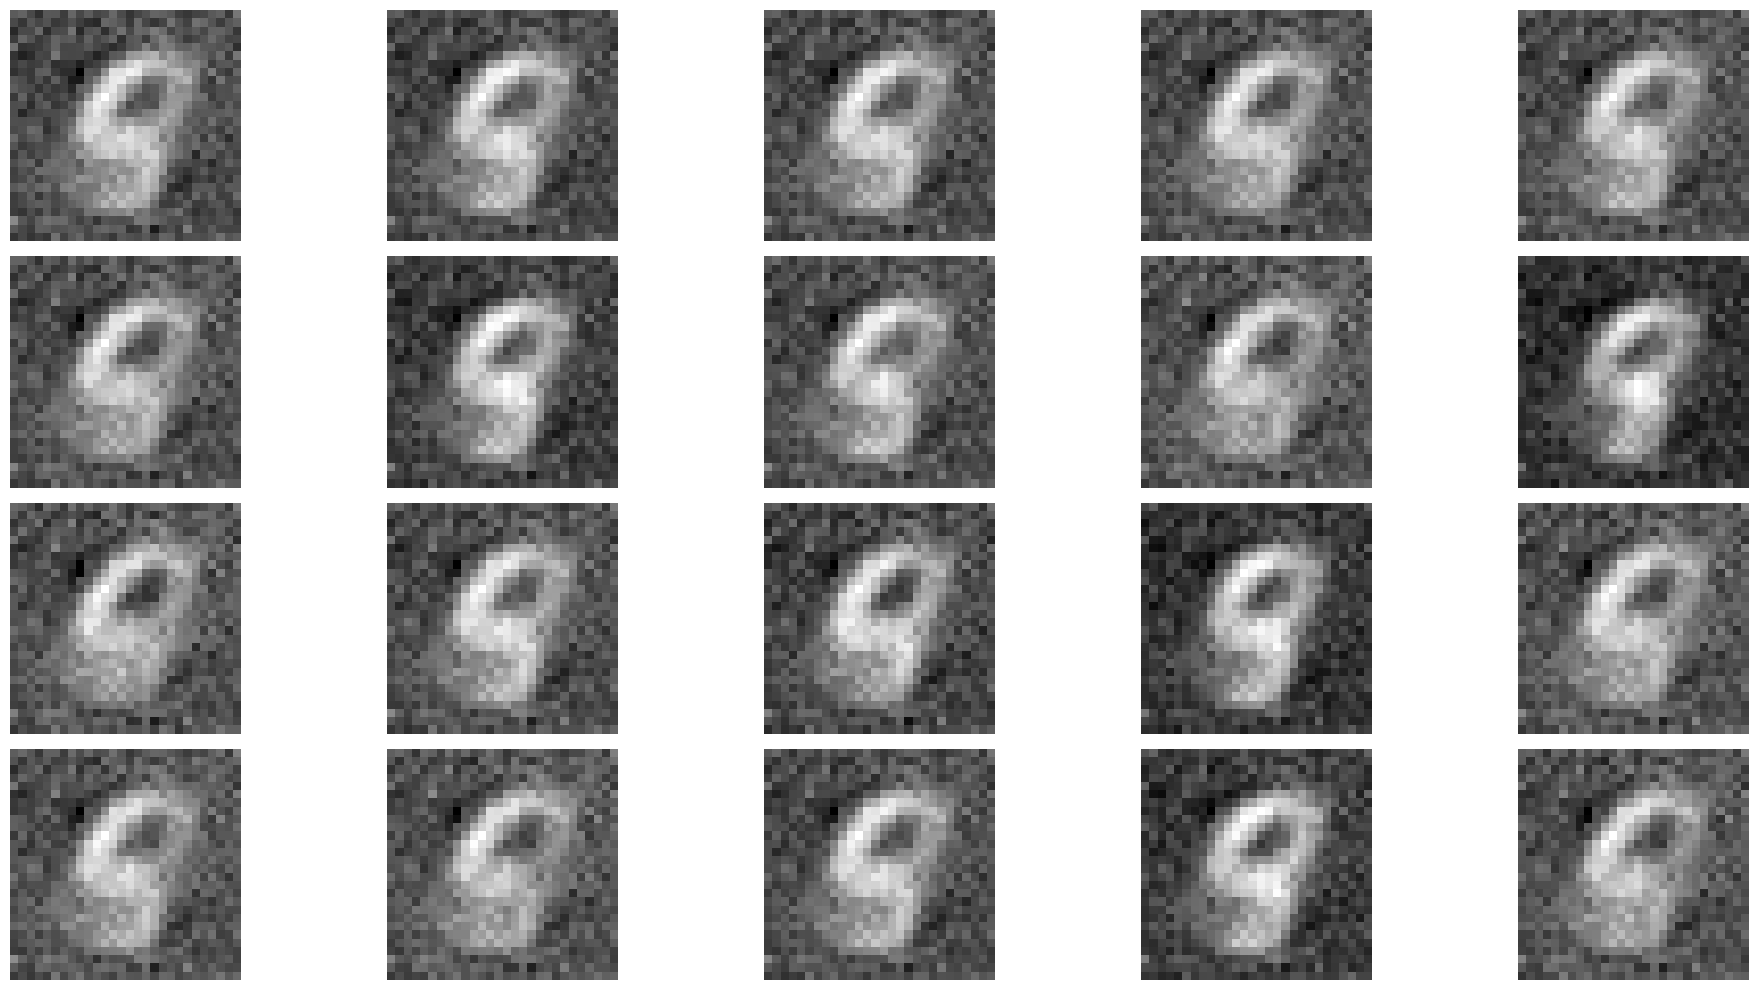

📈 Epoch 5 Summary:
   Train D Loss: 1.2855, Val D Loss: 1.3930
   Train G Loss: 1.5037, Val G Loss: 0.5868

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 1.373548	G_loss: 0.756287
Epoch: 6 [6400/60000 (11%)]	D_loss: 1.257930	G_loss: 1.075802
Epoch: 6 [12800/60000 (21%)]	D_loss: 1.358473	G_loss: 1.180424
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.240303	G_loss: 2.676517
Epoch: 6 [25600/60000 (43%)]	D_loss: 1.204420	G_loss: 1.092271
Epoch: 6 [32000/60000 (53%)]	D_loss: 1.408290	G_loss: 0.860967
Epoch: 6 [38400/60000 (64%)]	D_loss: 1.535132	G_loss: 1.176883
Epoch: 6 [44800/60000 (75%)]	D_loss: 1.568162	G_loss: 2.870615
Epoch: 6 [51200/60000 (85%)]	D_loss: 1.466950	G_loss: 1.243003
Epoch: 6 [57600/60000 (96%)]	D_loss: 1.410131	G_loss: 1.406829
====> Epoch: 6 Train D_loss: 1.2991, Train G_loss: 1.3994
====> Epoch: 6 Val D_loss: 1.6041, Val G_loss: 1.0613
📈 Epoch 6 Summary:
   Train D Loss: 1.2991, Val D Loss: 1.6041
   Train G Loss: 1.3994, Val G Loss: 1

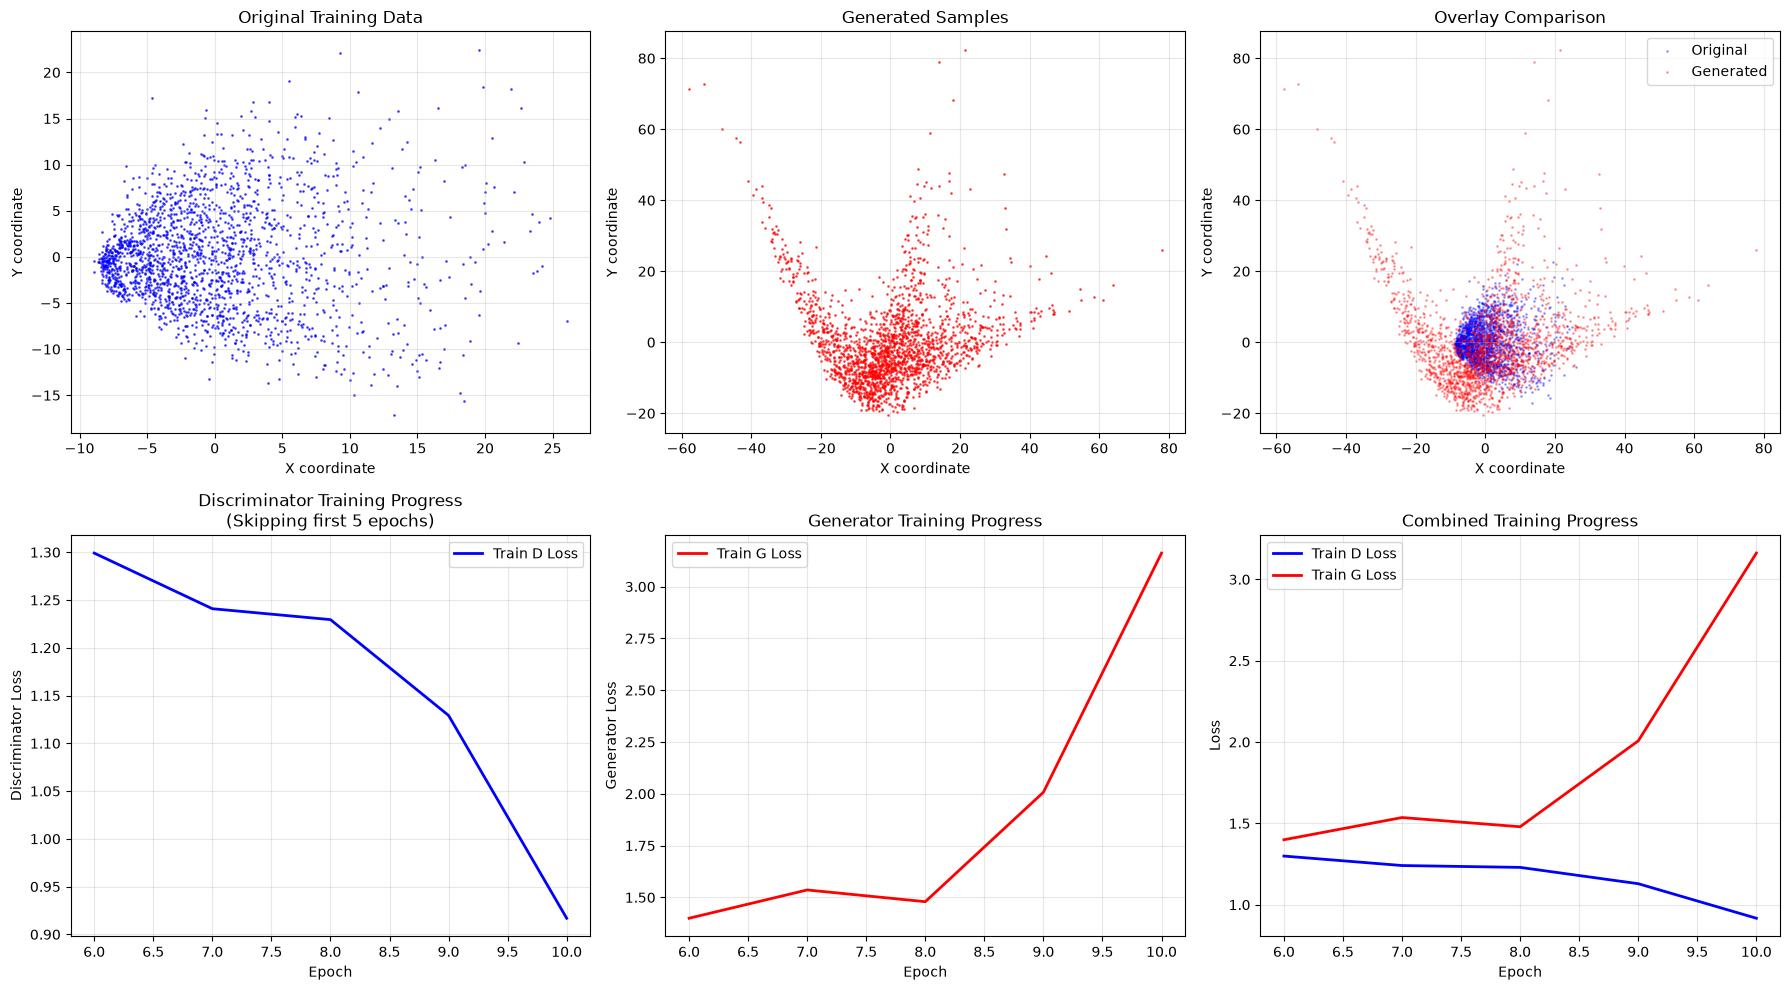

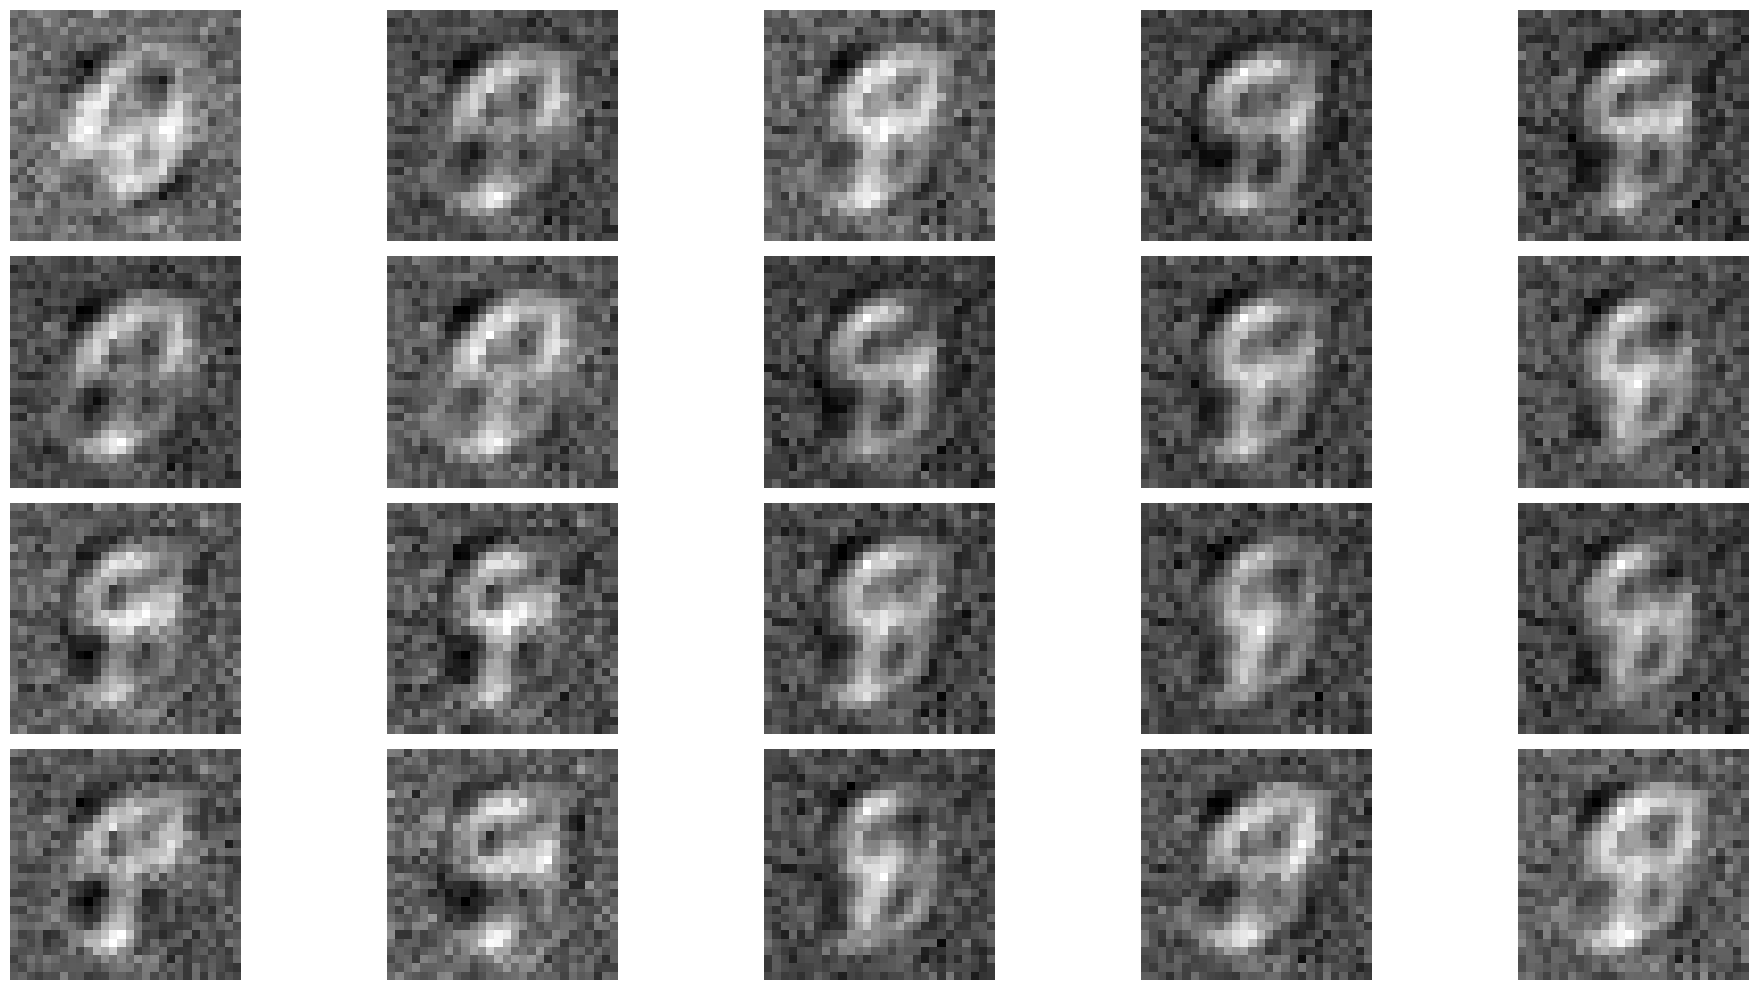

📈 Epoch 10 Summary:
   Train D Loss: 0.9169, Val D Loss: 1.0972
   Train G Loss: 3.1616, Val G Loss: 1.1164

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 1.081678	G_loss: 4.832221
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.569973	G_loss: 2.346730
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.685408	G_loss: 3.772467
Epoch: 11 [19200/60000 (32%)]	D_loss: 0.666424	G_loss: 3.271269
Epoch: 11 [25600/60000 (43%)]	D_loss: 0.727896	G_loss: 3.143942
Epoch: 11 [32000/60000 (53%)]	D_loss: 1.052431	G_loss: 2.005225
Epoch: 11 [38400/60000 (64%)]	D_loss: 1.590498	G_loss: 3.875848
Epoch: 11 [44800/60000 (75%)]	D_loss: 0.724777	G_loss: 2.822662
Epoch: 11 [51200/60000 (85%)]	D_loss: 0.796764	G_loss: 3.061523
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.726051	G_loss: 2.165559
====> Epoch: 11 Train D_loss: 0.8400, Train G_loss: 3.0881
====> Epoch: 11 Val D_loss: 0.8042, Val G_loss: 1.6440
📈 Epoch 11 Summary:
   Train D Loss: 0.8400, Val D Loss: 0.8042
   Train G Loss: 3.0881

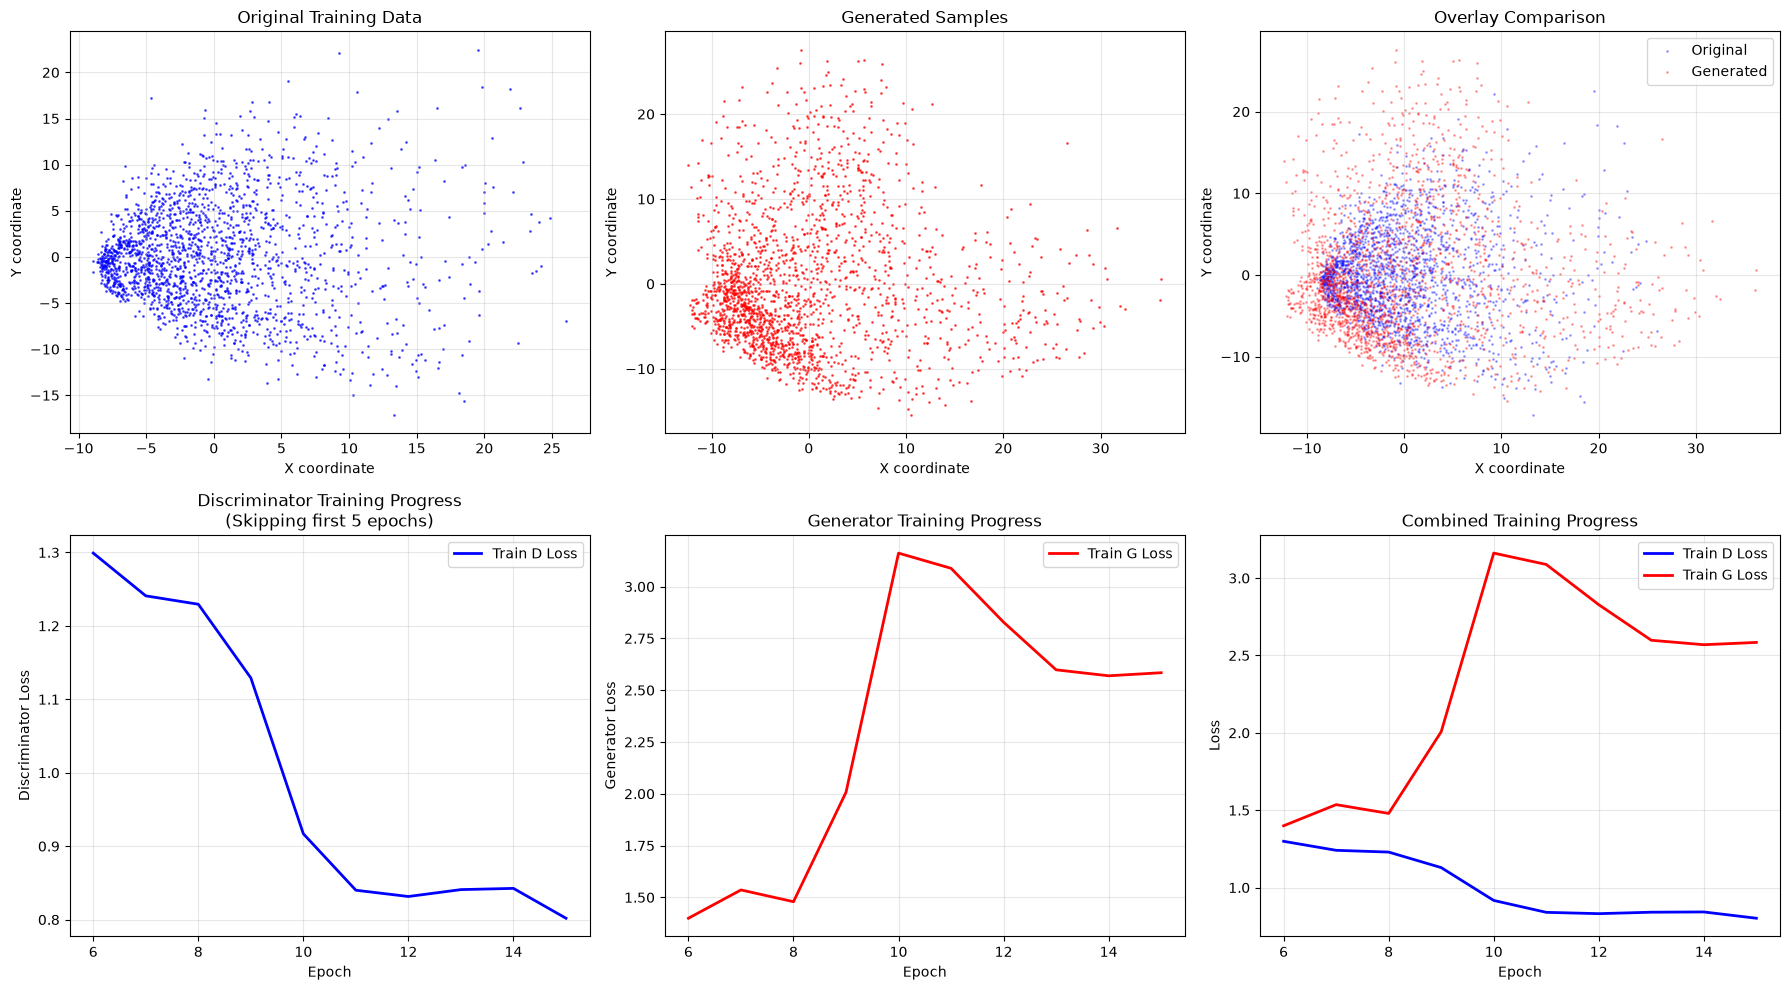

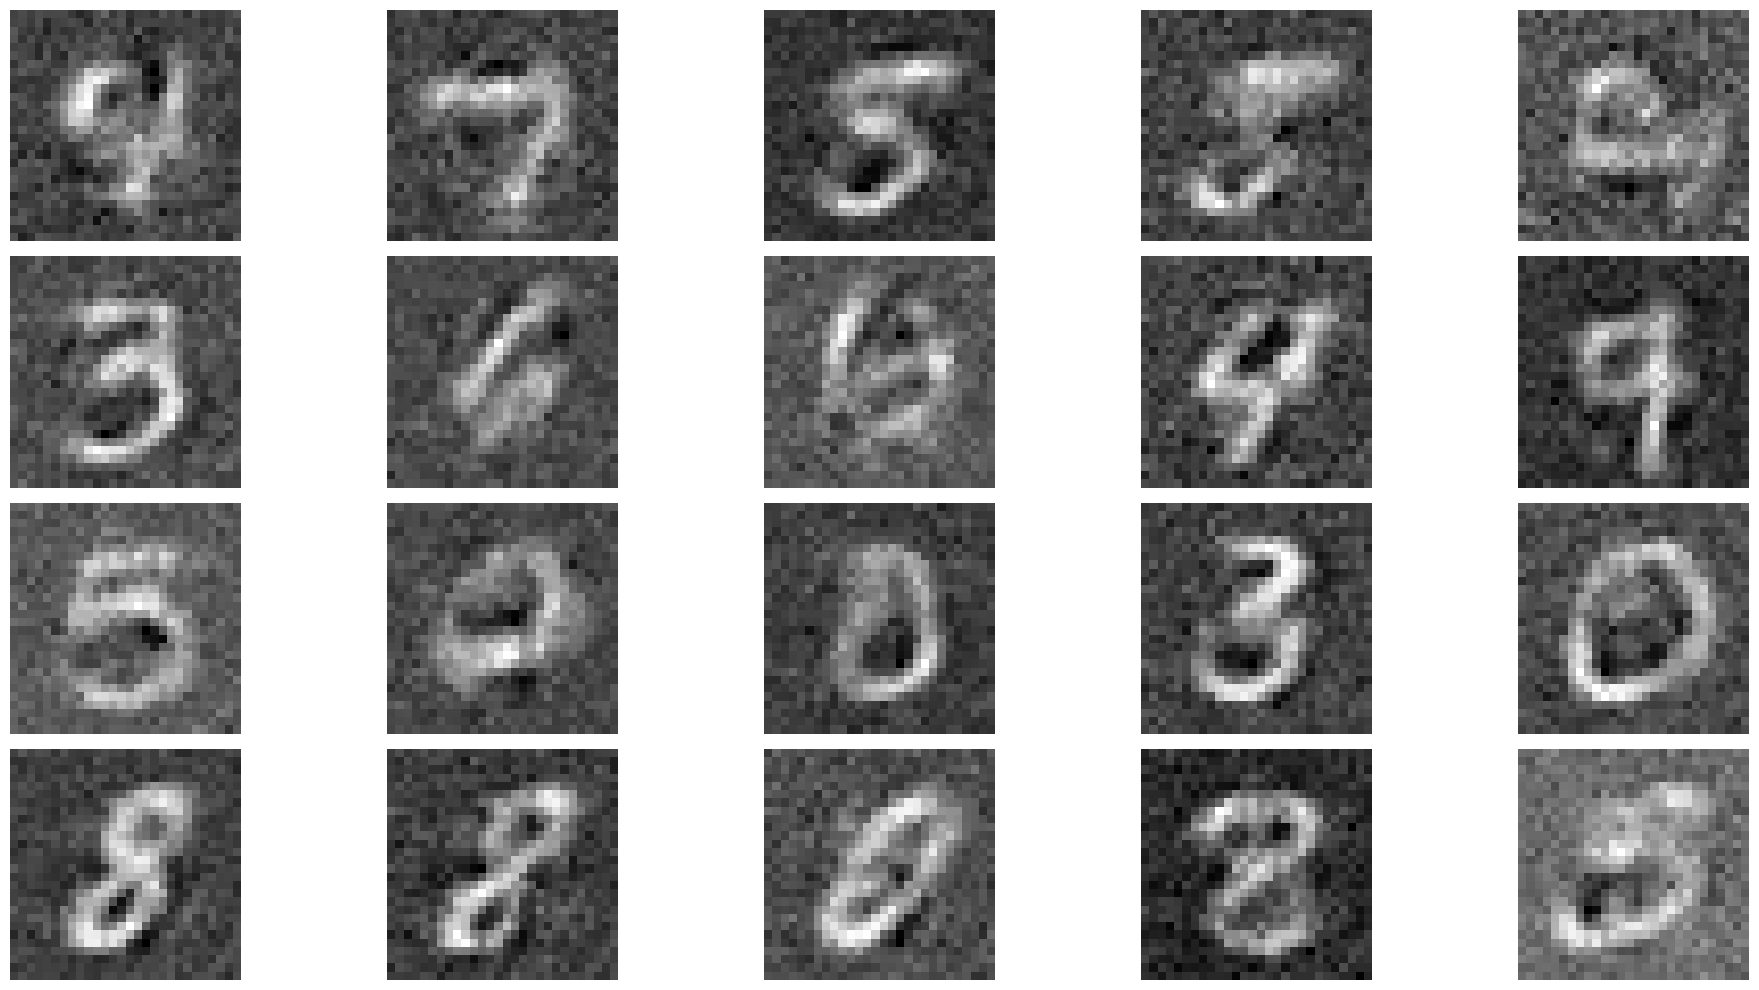

📈 Epoch 15 Summary:
   Train D Loss: 0.8019, Val D Loss: 0.9272
   Train G Loss: 2.5843, Val G Loss: 2.9867

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.967356	G_loss: 1.220933
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.765302	G_loss: 3.037776
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.838582	G_loss: 2.567270
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.911301	G_loss: 2.471879
Epoch: 16 [25600/60000 (43%)]	D_loss: 1.058130	G_loss: 2.152585
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.740414	G_loss: 2.017497
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.661688	G_loss: 2.507463
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.829882	G_loss: 3.116086
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.595267	G_loss: 2.341478
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.790191	G_loss: 3.326853
====> Epoch: 16 Train D_loss: 0.7951, Train G_loss: 2.5960
====> Epoch: 16 Val D_loss: 0.6951, Val G_loss: 1.5535
📈 Epoch 16 Summary:
   Train D Loss: 0.7951, Val D Loss: 0.6951
   Train G Loss: 2.5960

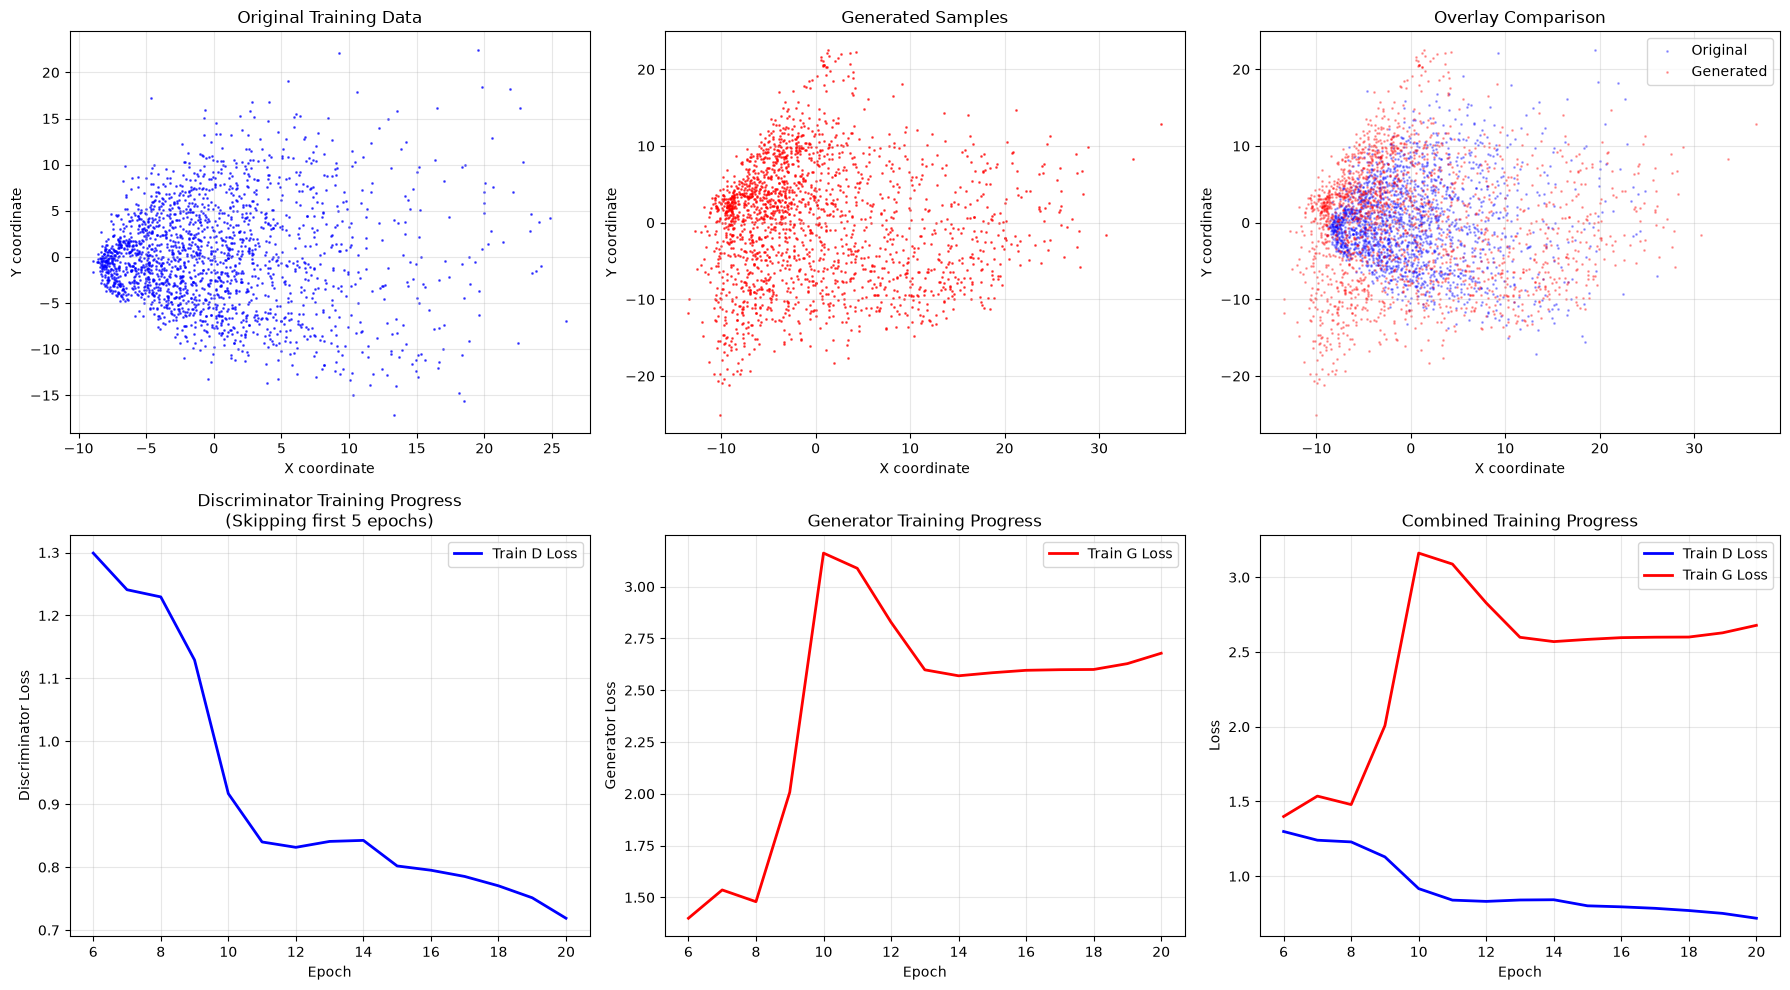

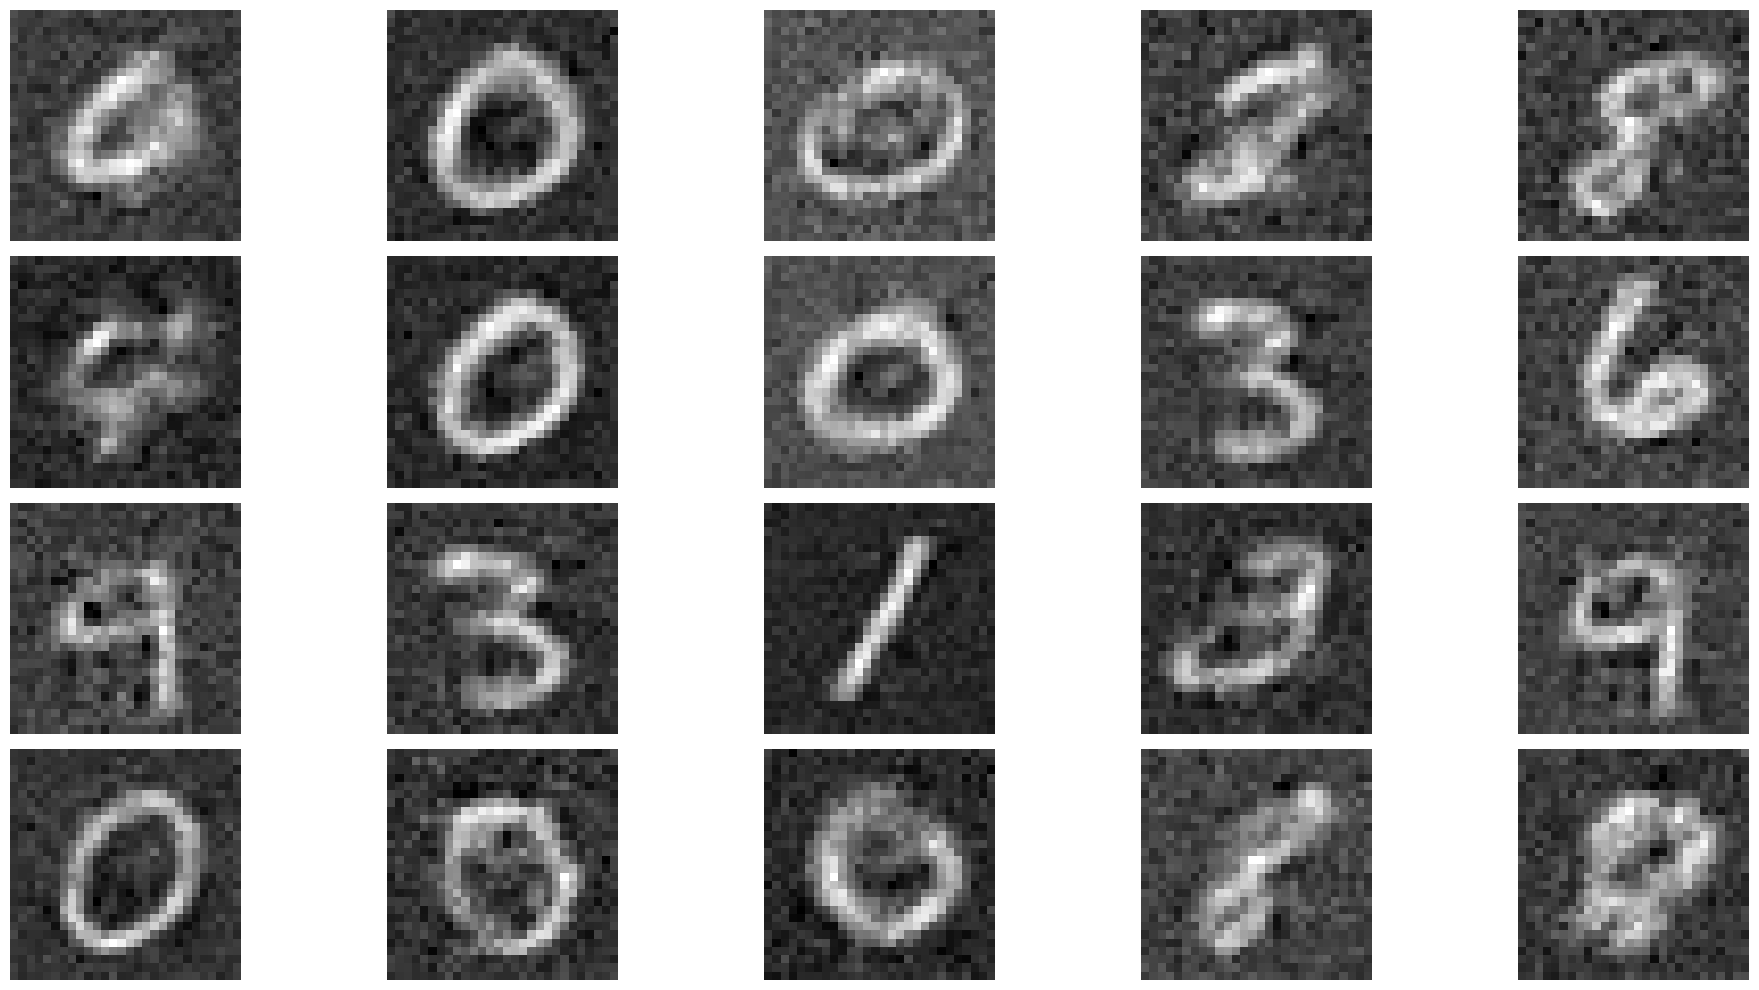

📈 Epoch 20 Summary:
   Train D Loss: 0.7188, Val D Loss: 0.7618
   Train G Loss: 2.6783, Val G Loss: 1.6150

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.760742	G_loss: 3.013227
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.791981	G_loss: 2.356618
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.617663	G_loss: 2.610331
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.847987	G_loss: 2.060080
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.591229	G_loss: 2.419217
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.537670	G_loss: 2.166240
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.535474	G_loss: 2.834577
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.639092	G_loss: 1.847426
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.515151	G_loss: 2.820005
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.672155	G_loss: 3.806540
====> Epoch: 21 Train D_loss: 0.7021, Train G_loss: 2.6786
====> Epoch: 21 Val D_loss: 0.6592, Val G_loss: 1.7494
📈 Epoch 21 Summary:
   Train D Loss: 0.7021, Val D Loss: 0.6592
   Train G Loss: 2.6786

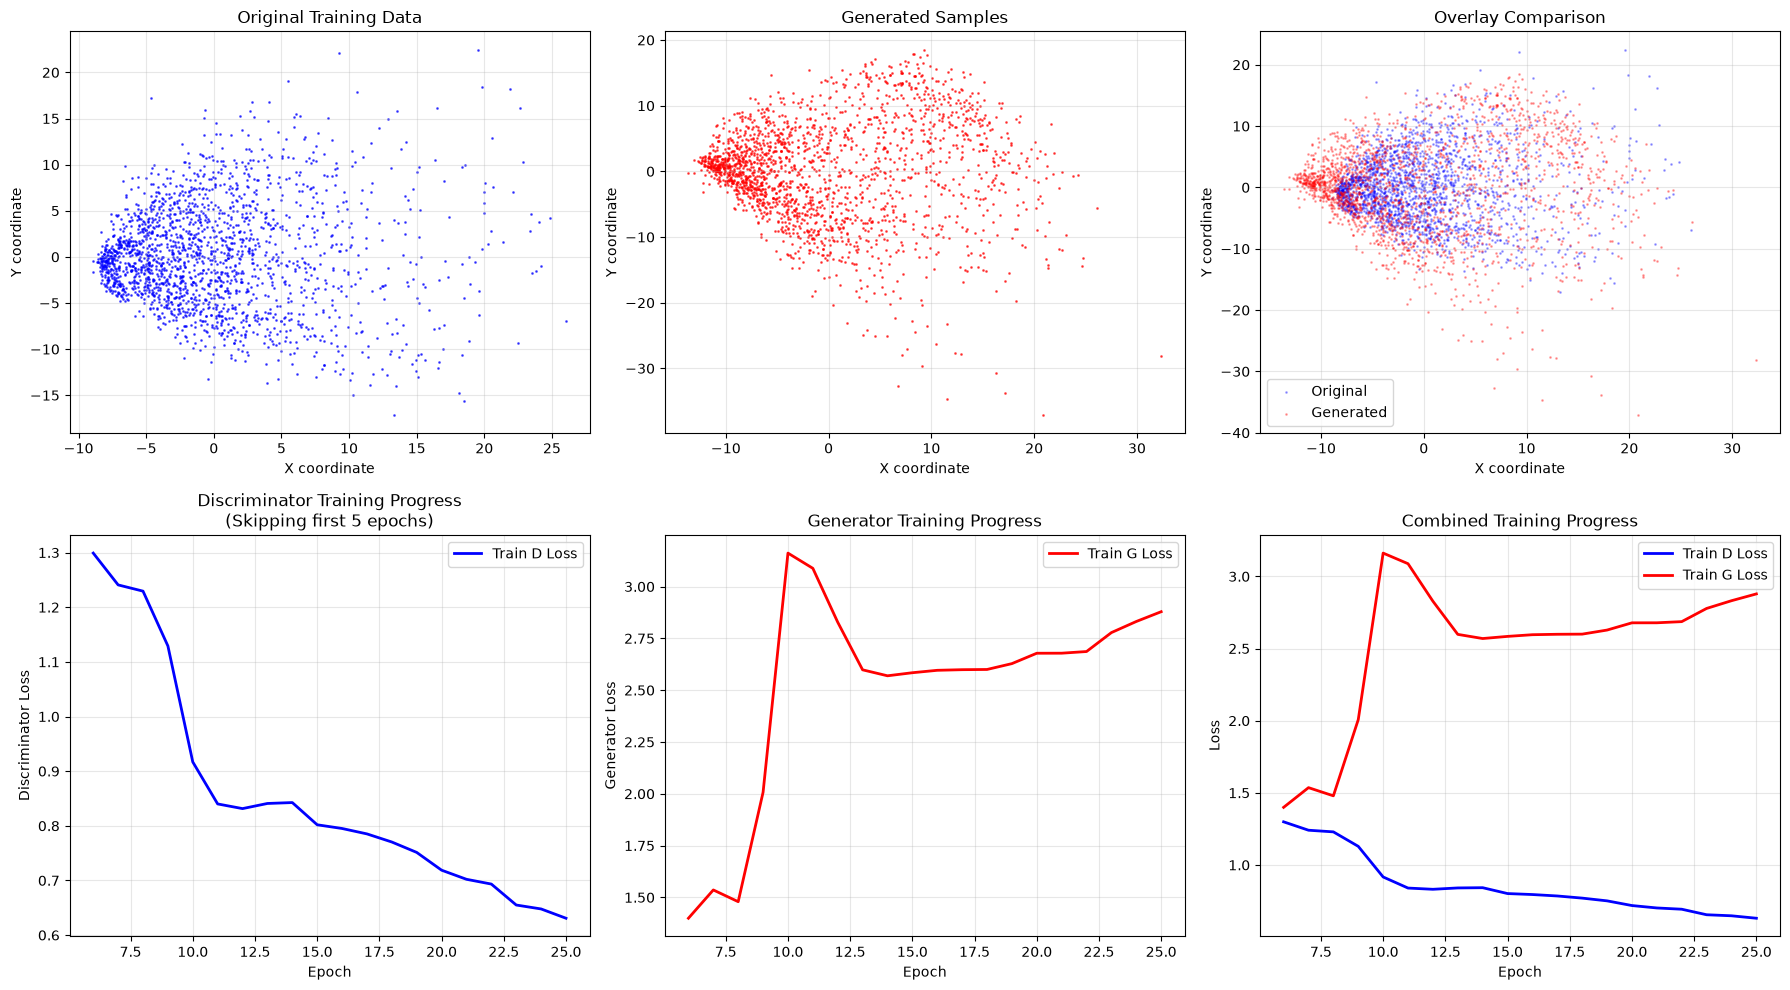

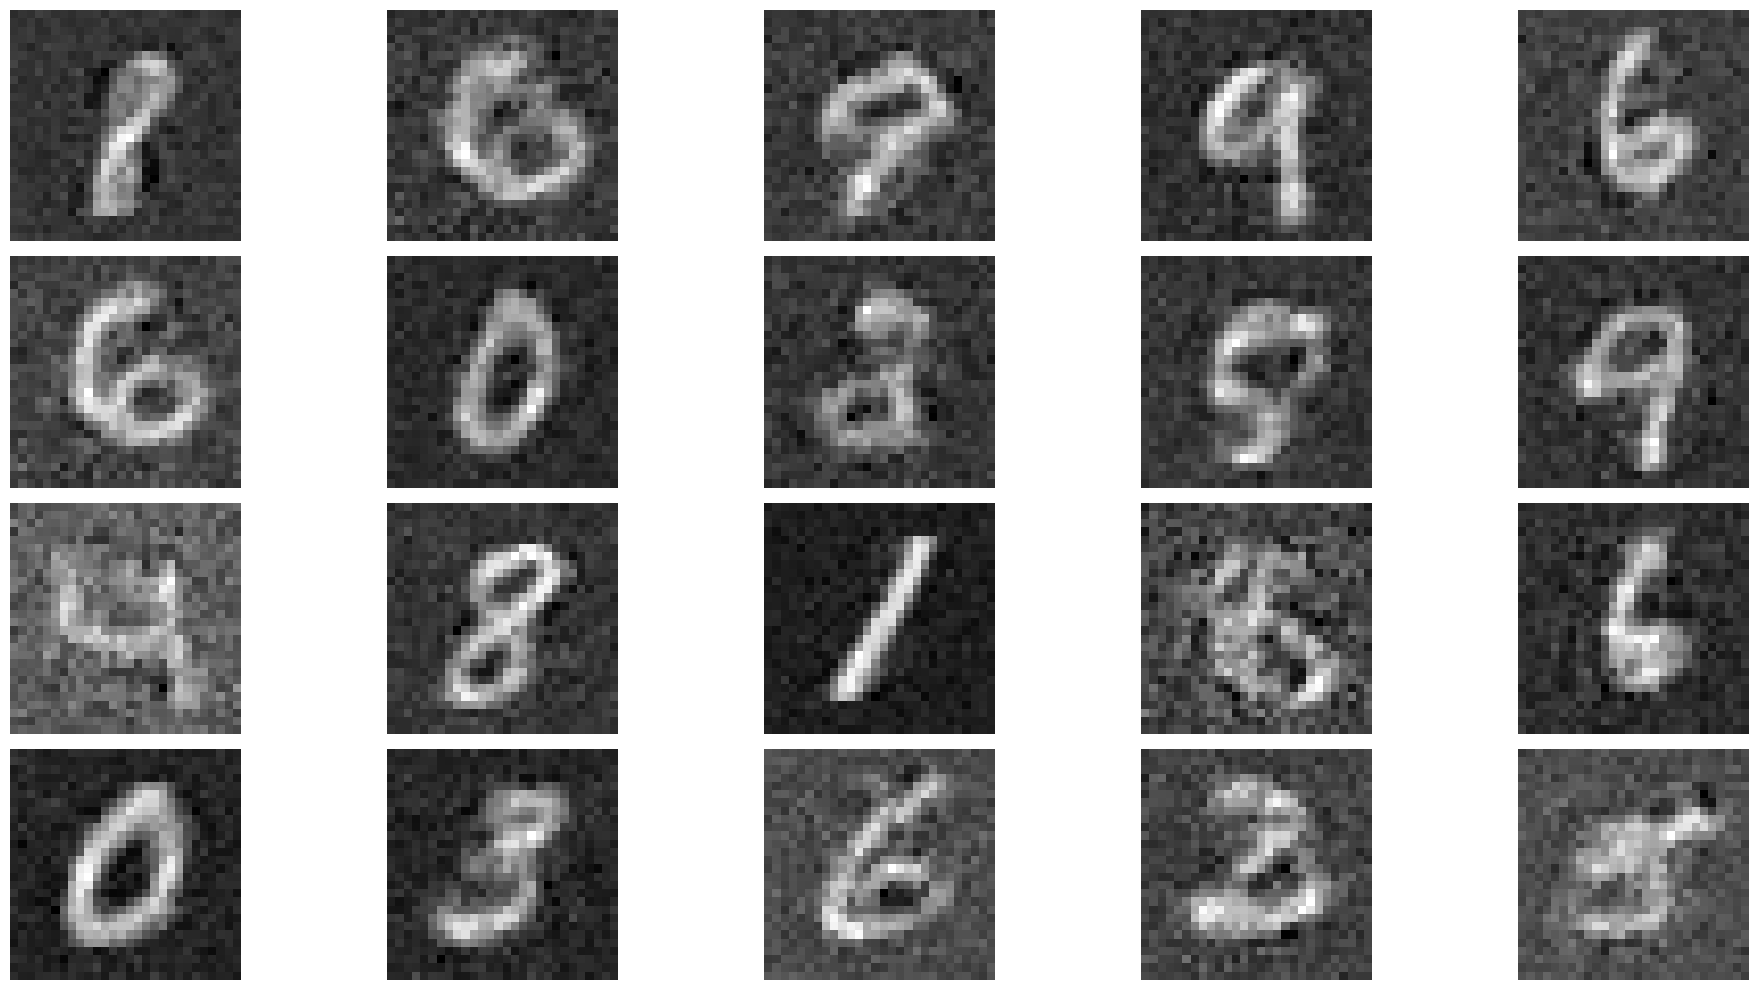

📈 Epoch 25 Summary:
   Train D Loss: 0.6309, Val D Loss: 0.5593
   Train G Loss: 2.8788, Val G Loss: 2.3716

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.452000	G_loss: 2.445616
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.568519	G_loss: 2.909701
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.768321	G_loss: 2.097158
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.444676	G_loss: 3.315189
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.490208	G_loss: 2.361191
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.766763	G_loss: 3.188457
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.552932	G_loss: 2.877281
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.730245	G_loss: 2.876149
Epoch: 26 [51200/60000 (85%)]	D_loss: 1.016862	G_loss: 2.198295
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.616085	G_loss: 4.499555
====> Epoch: 26 Train D_loss: 0.6142, Train G_loss: 2.9511
====> Epoch: 26 Val D_loss: 0.6956, Val G_loss: 2.3558
📈 Epoch 26 Summary:
   Train D Loss: 0.6142, Val D Loss: 0.6956
   Train G Loss: 2.9511

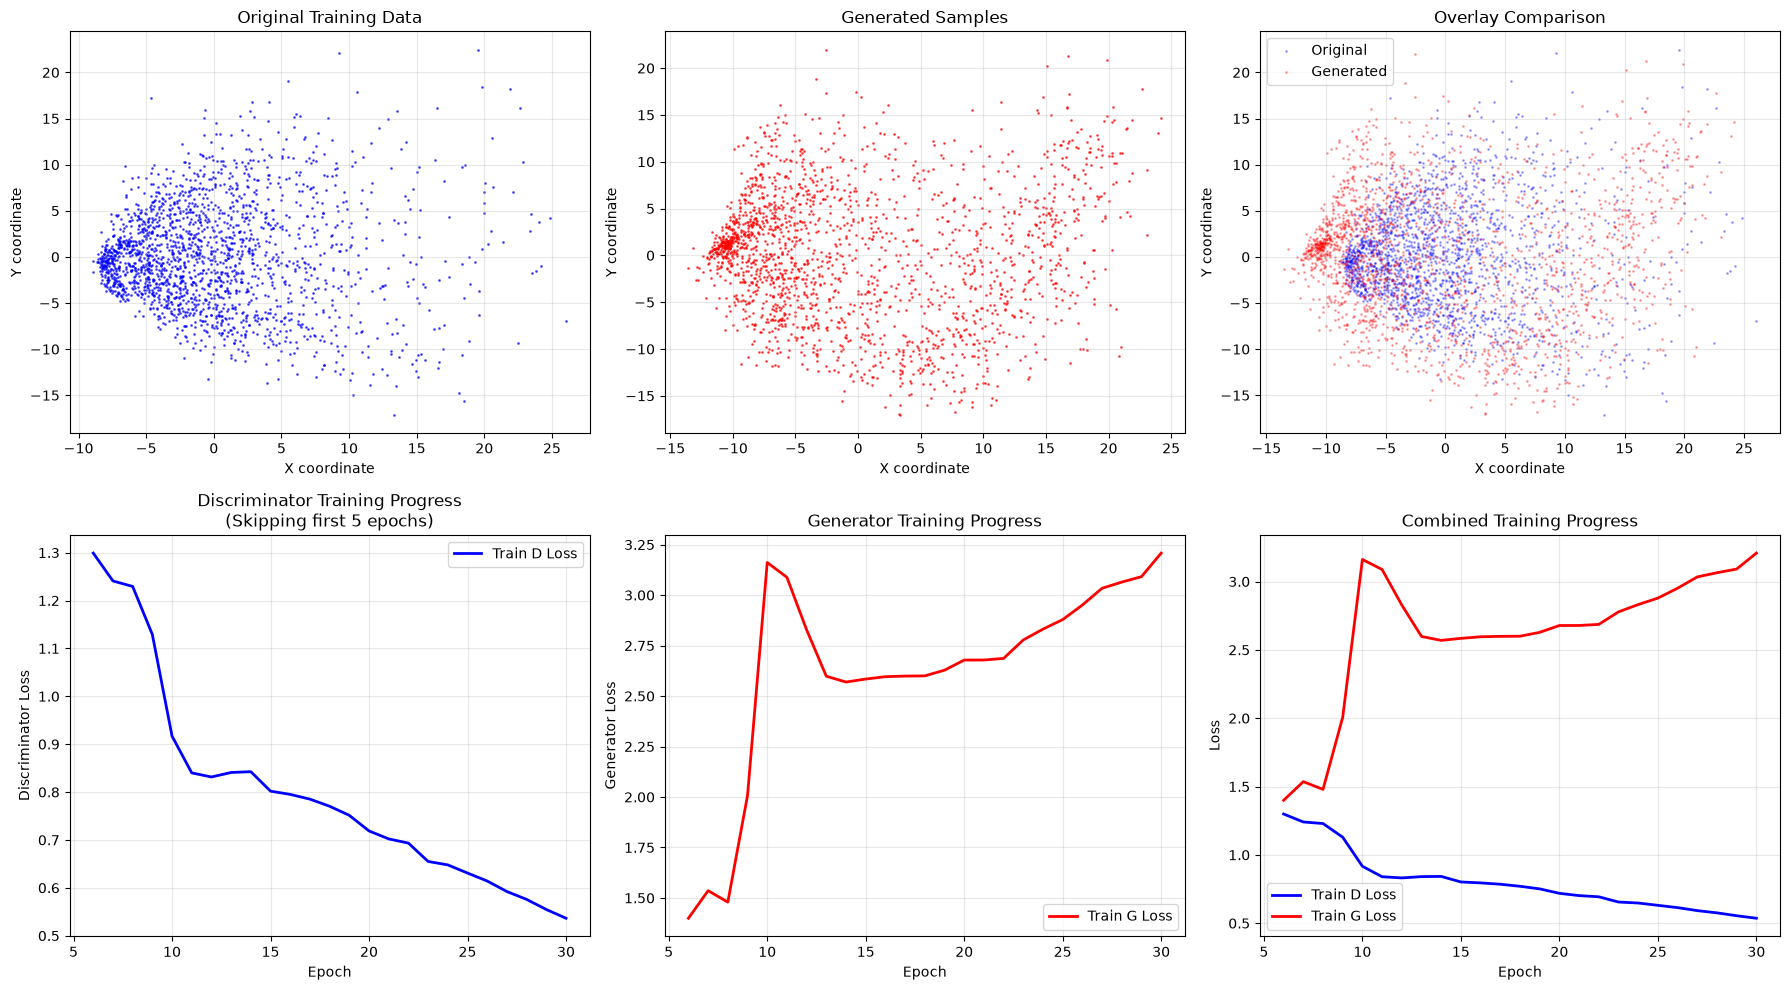

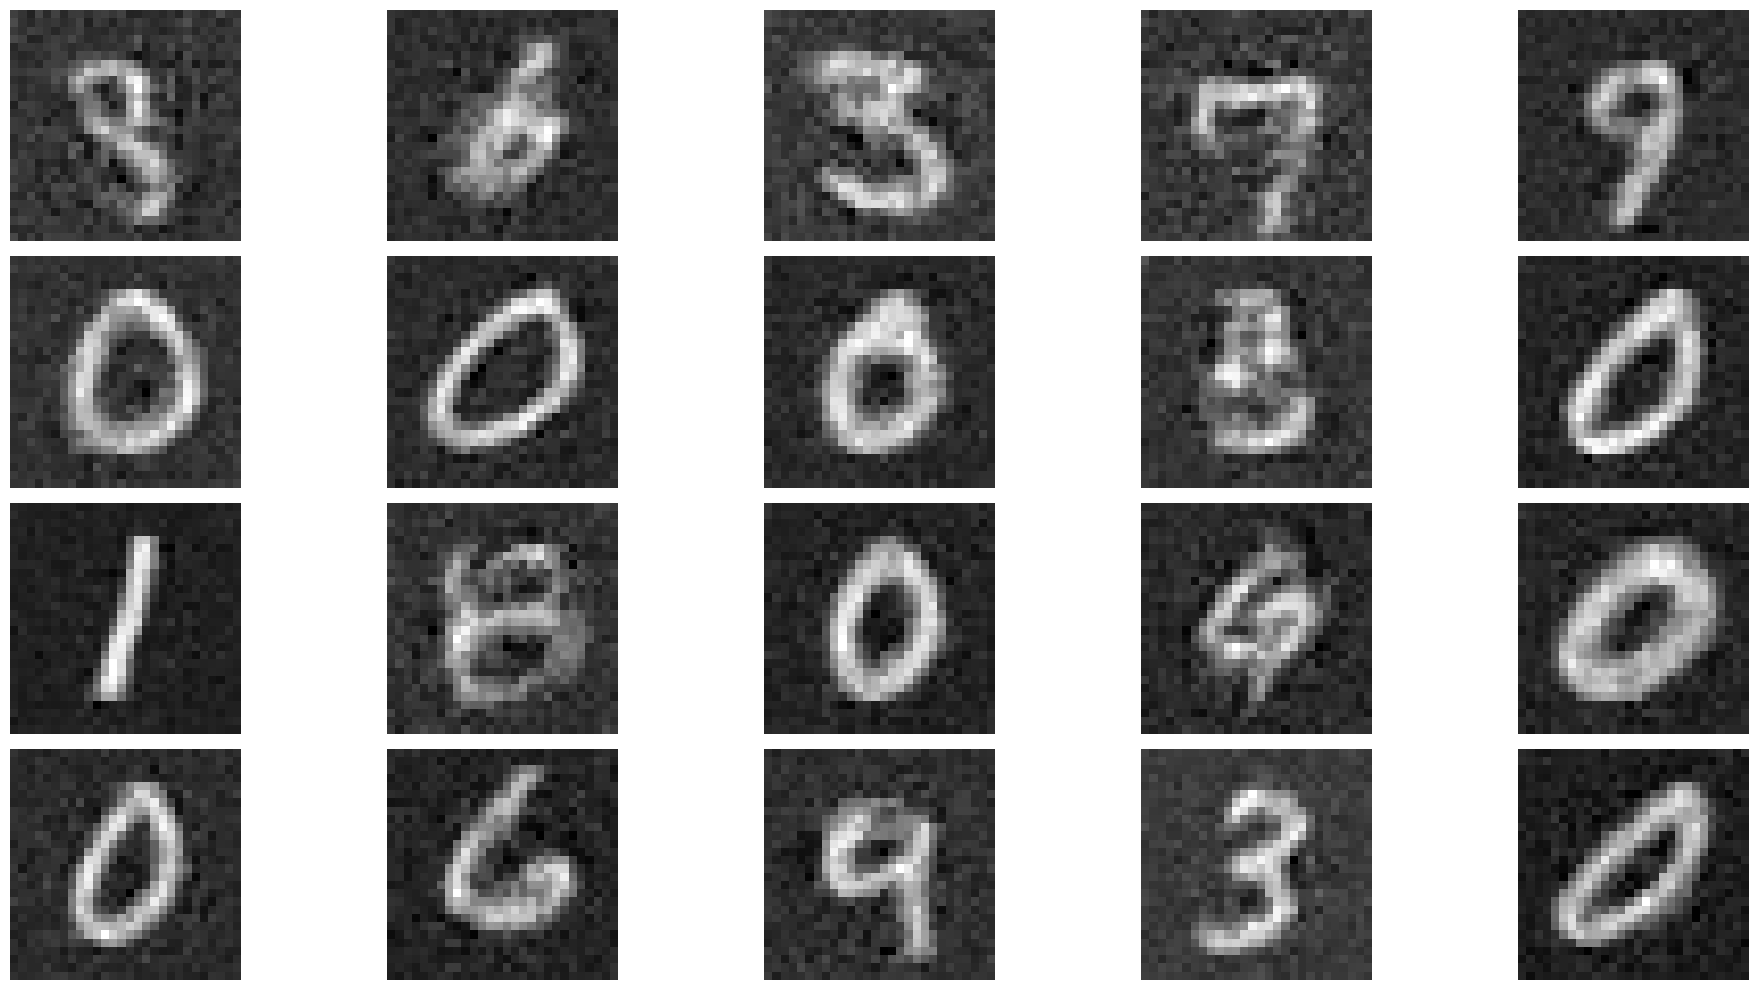

📈 Epoch 30 Summary:
   Train D Loss: 0.5365, Val D Loss: 0.5129
   Train G Loss: 3.2082, Val G Loss: 1.7817

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.472199	G_loss: 3.714429
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.441052	G_loss: 2.207979
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.593023	G_loss: 2.562727
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.447987	G_loss: 3.097250
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.482240	G_loss: 3.565676
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.565878	G_loss: 3.377782
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.462180	G_loss: 3.108883
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.435136	G_loss: 2.644368
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.606377	G_loss: 3.067129
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.436379	G_loss: 1.956881
====> Epoch: 31 Train D_loss: 0.5148, Train G_loss: 3.2401
====> Epoch: 31 Val D_loss: 0.5104, Val G_loss: 3.0900
📈 Epoch 31 Summary:
   Train D Loss: 0.5148, Val D Loss: 0.5104
   Train G Loss: 3.2401

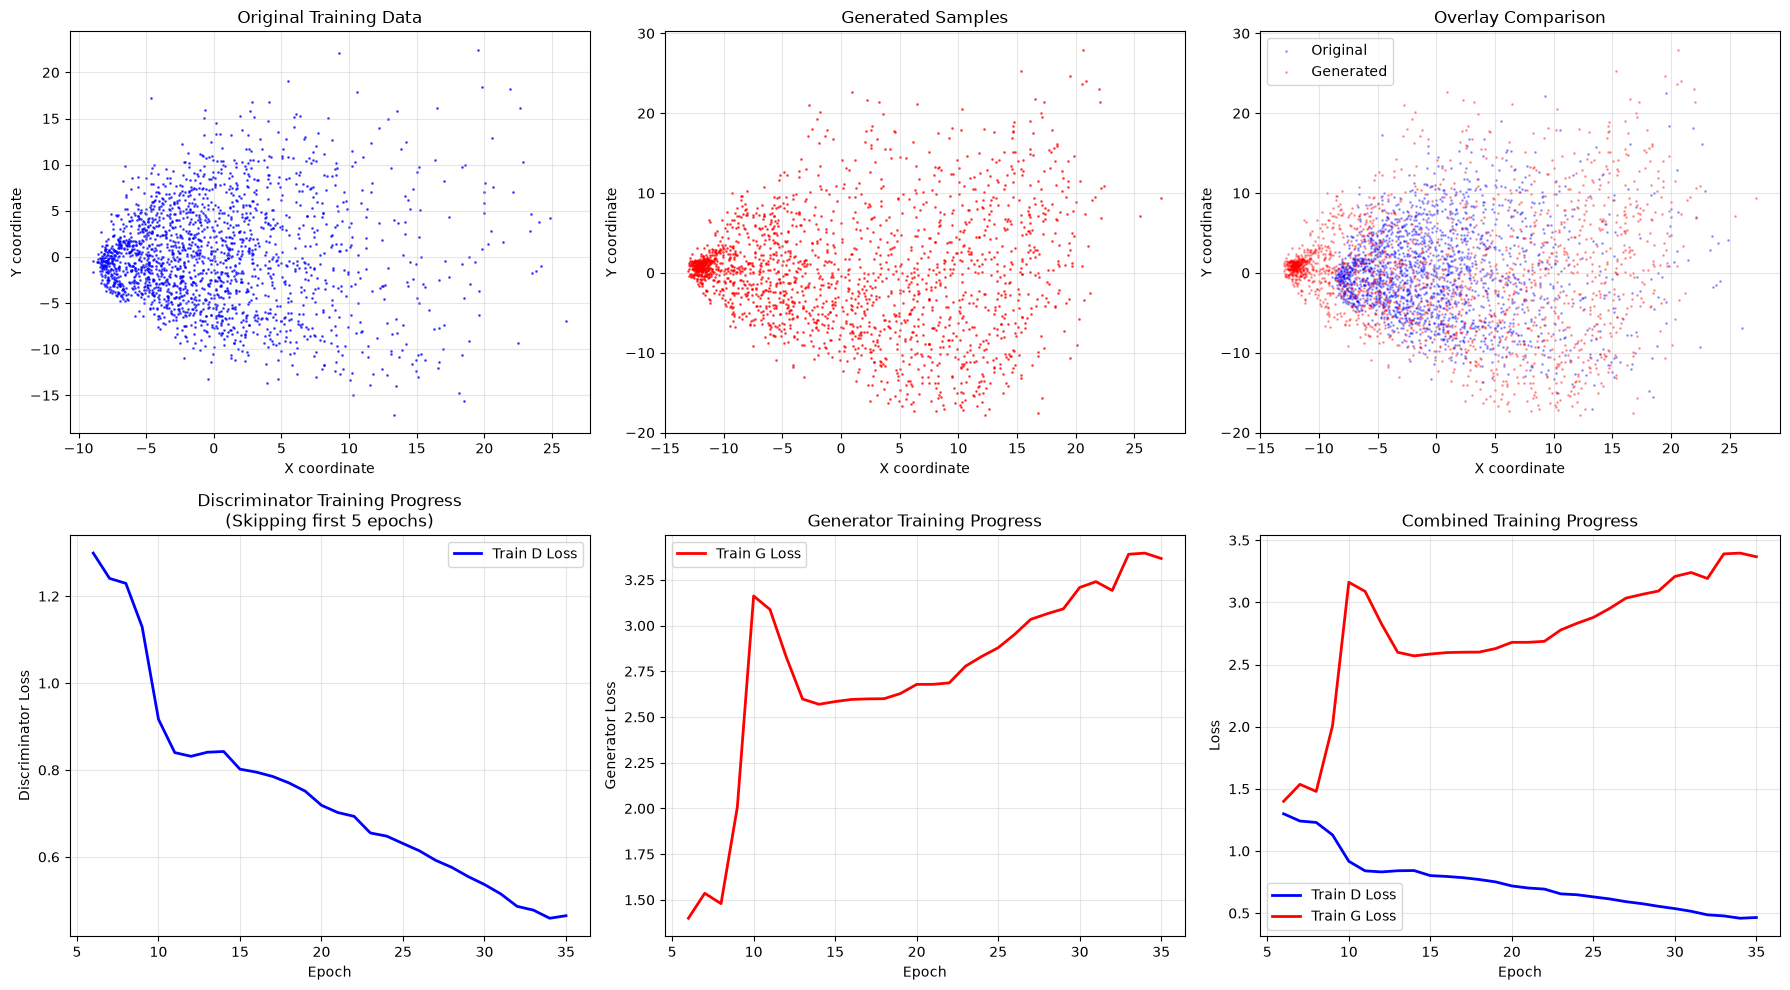

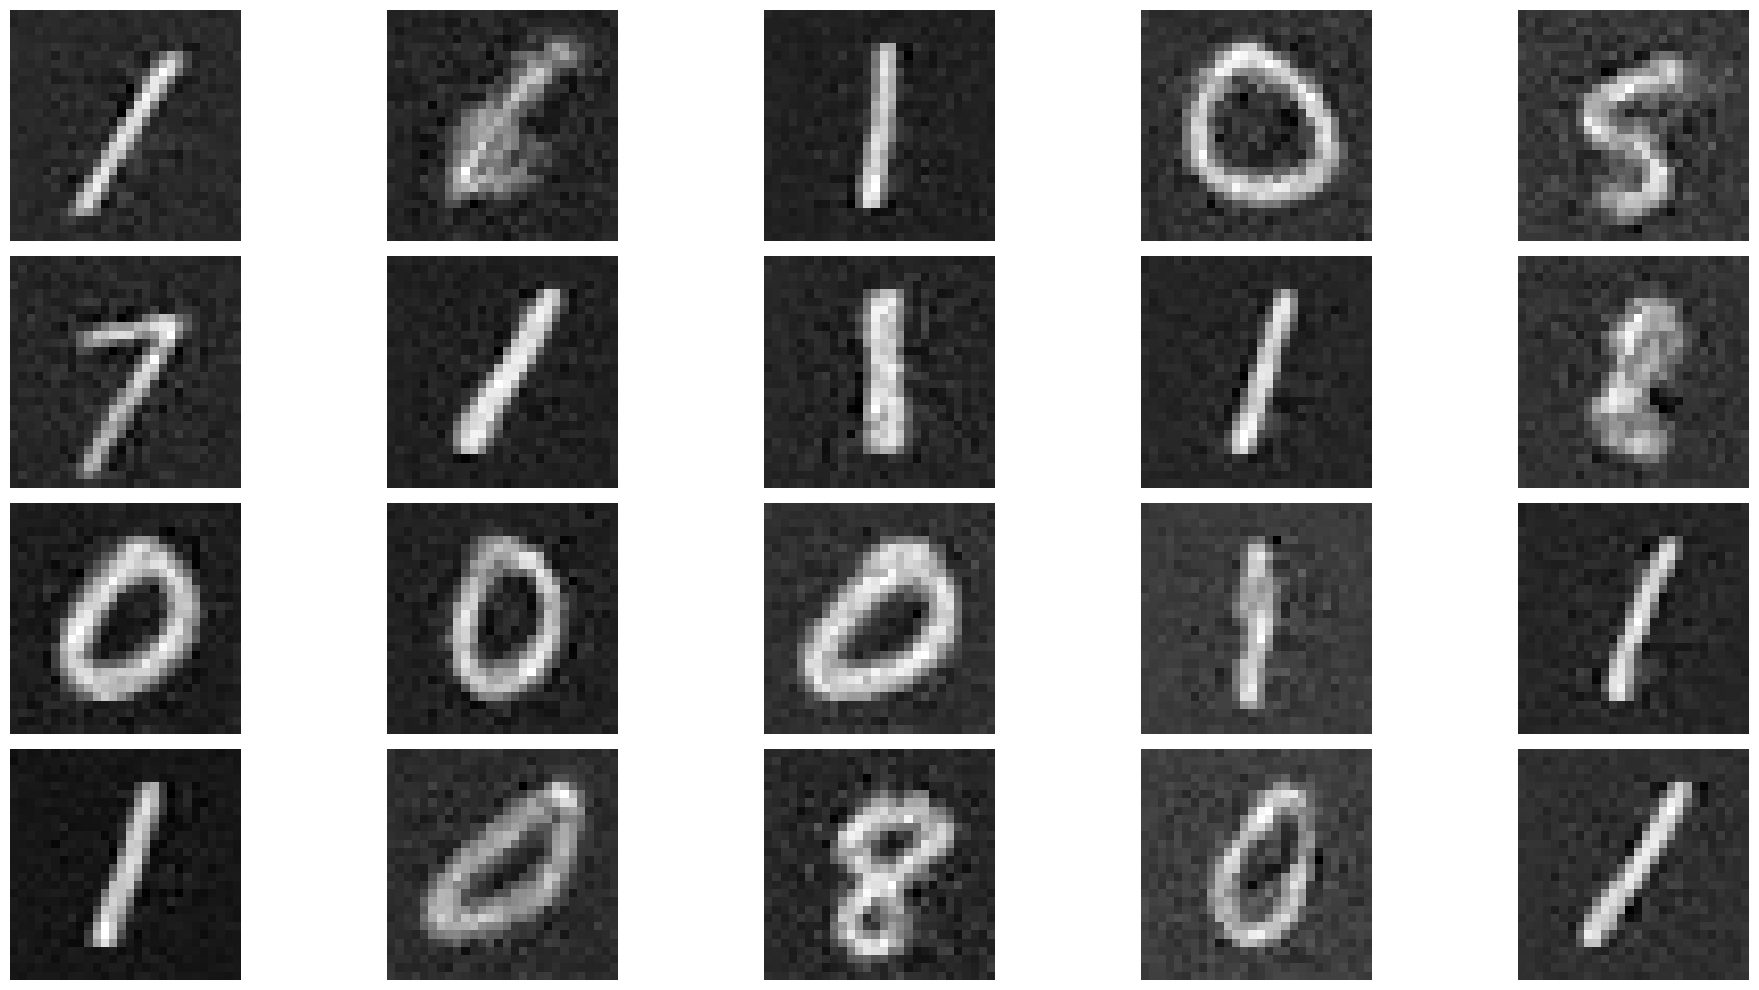

📈 Epoch 35 Summary:
   Train D Loss: 0.4647, Val D Loss: 0.4702
   Train G Loss: 3.3668, Val G Loss: 2.6201

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.446101	G_loss: 3.683149
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.595207	G_loss: 2.899994
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.394298	G_loss: 4.234785
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.564452	G_loss: 6.055507
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.505739	G_loss: 2.801125
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.962082	G_loss: 2.216457
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.403862	G_loss: 2.193009
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.400852	G_loss: 3.163180
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.371320	G_loss: 2.460220
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.354484	G_loss: 3.262433
====> Epoch: 36 Train D_loss: 0.4910, Train G_loss: 3.3320
====> Epoch: 36 Val D_loss: 0.4731, Val G_loss: 2.4220
📈 Epoch 36 Summary:
   Train D Loss: 0.4910, Val D Loss: 0.4731
   Train G Loss: 3.3320

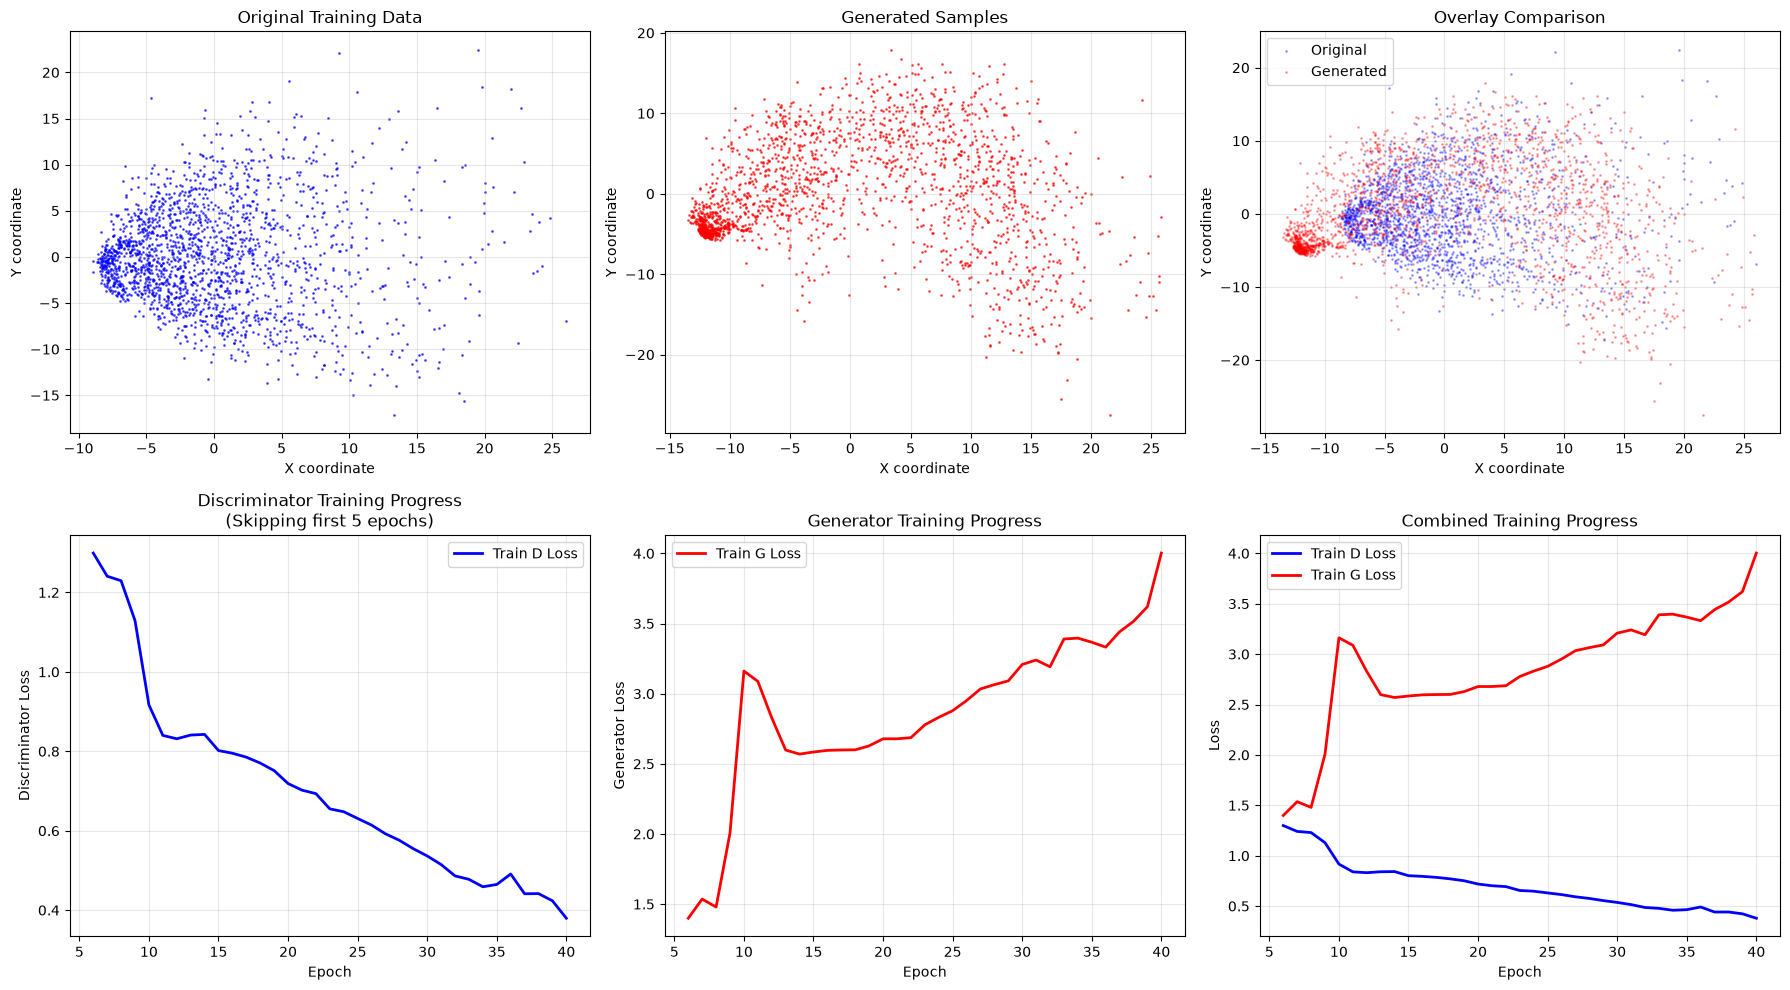

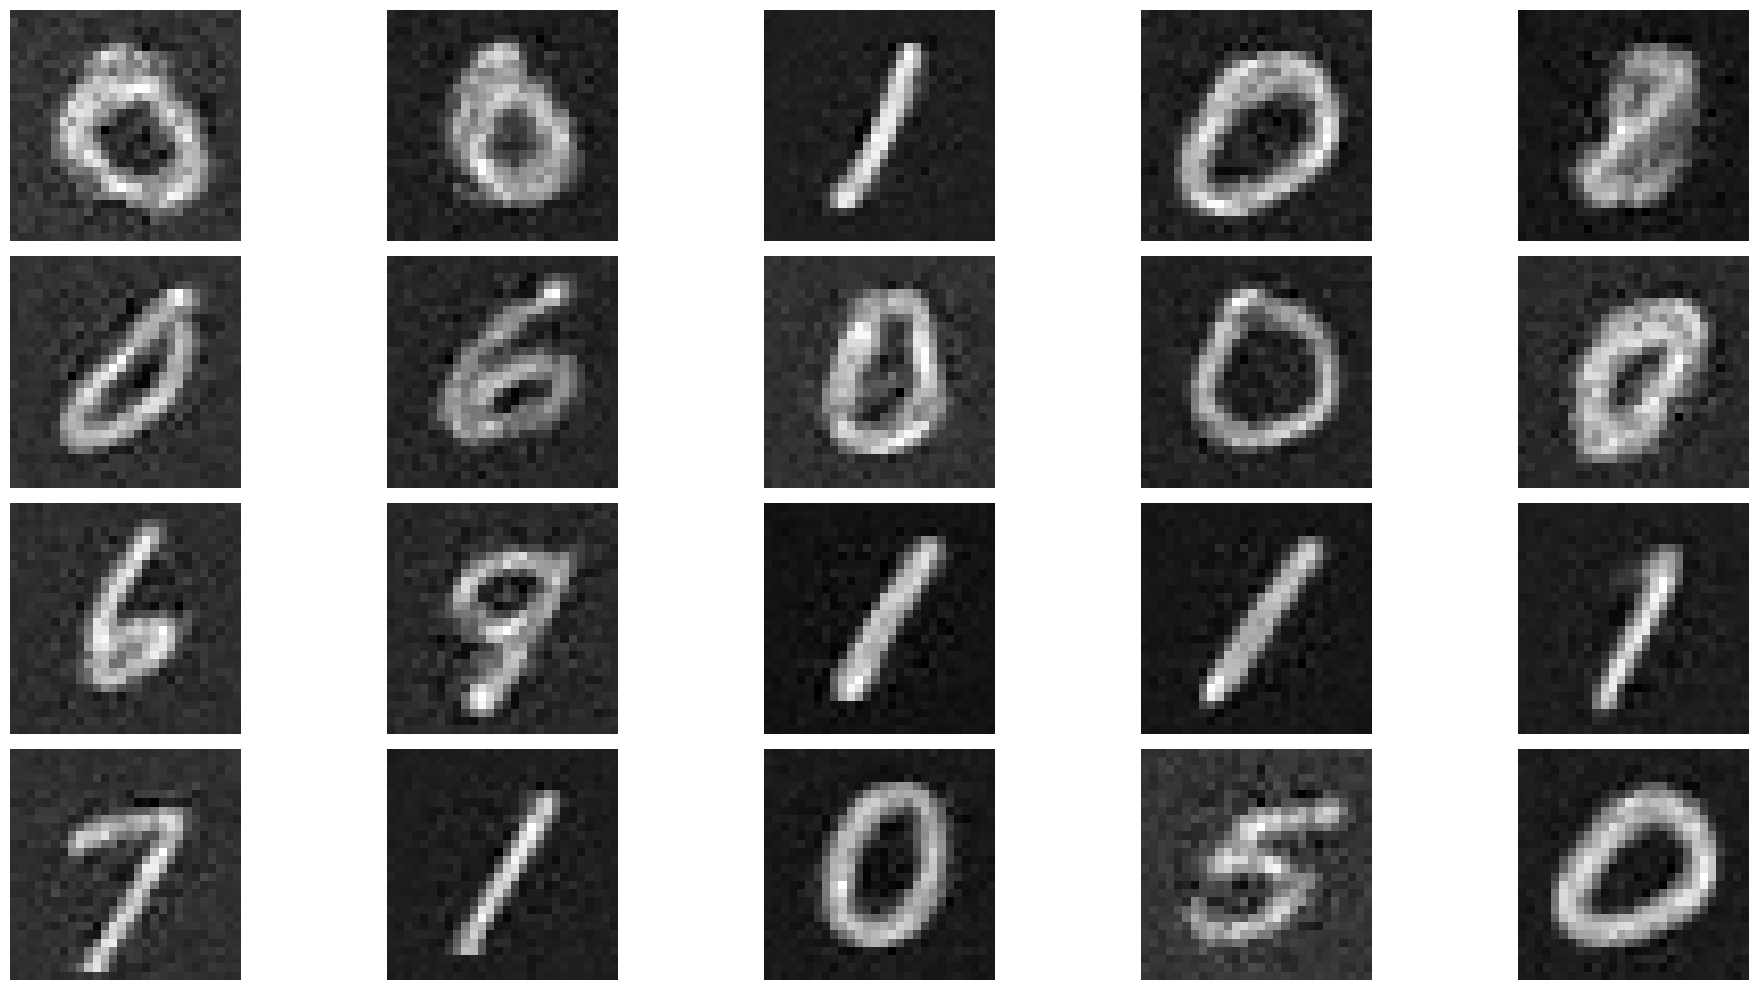

📈 Epoch 40 Summary:
   Train D Loss: 0.3796, Val D Loss: 0.3455
   Train G Loss: 4.0023, Val G Loss: 3.4226

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.269740	G_loss: 3.314941
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.324498	G_loss: 4.124733
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.262042	G_loss: 3.725699
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.693527	G_loss: 7.559643
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.233731	G_loss: 4.120220
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.225274	G_loss: 3.900738
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.356781	G_loss: 5.134305
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.327226	G_loss: 4.010672
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.462063	G_loss: 7.515643
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.473123	G_loss: 6.214689
====> Epoch: 41 Train D_loss: 0.3502, Train G_loss: 4.1627
====> Epoch: 41 Val D_loss: 0.4121, Val G_loss: 3.1390
📈 Epoch 41 Summary:
   Train D Loss: 0.3502, Val D Loss: 0.4121
   Train G Loss: 4.1627

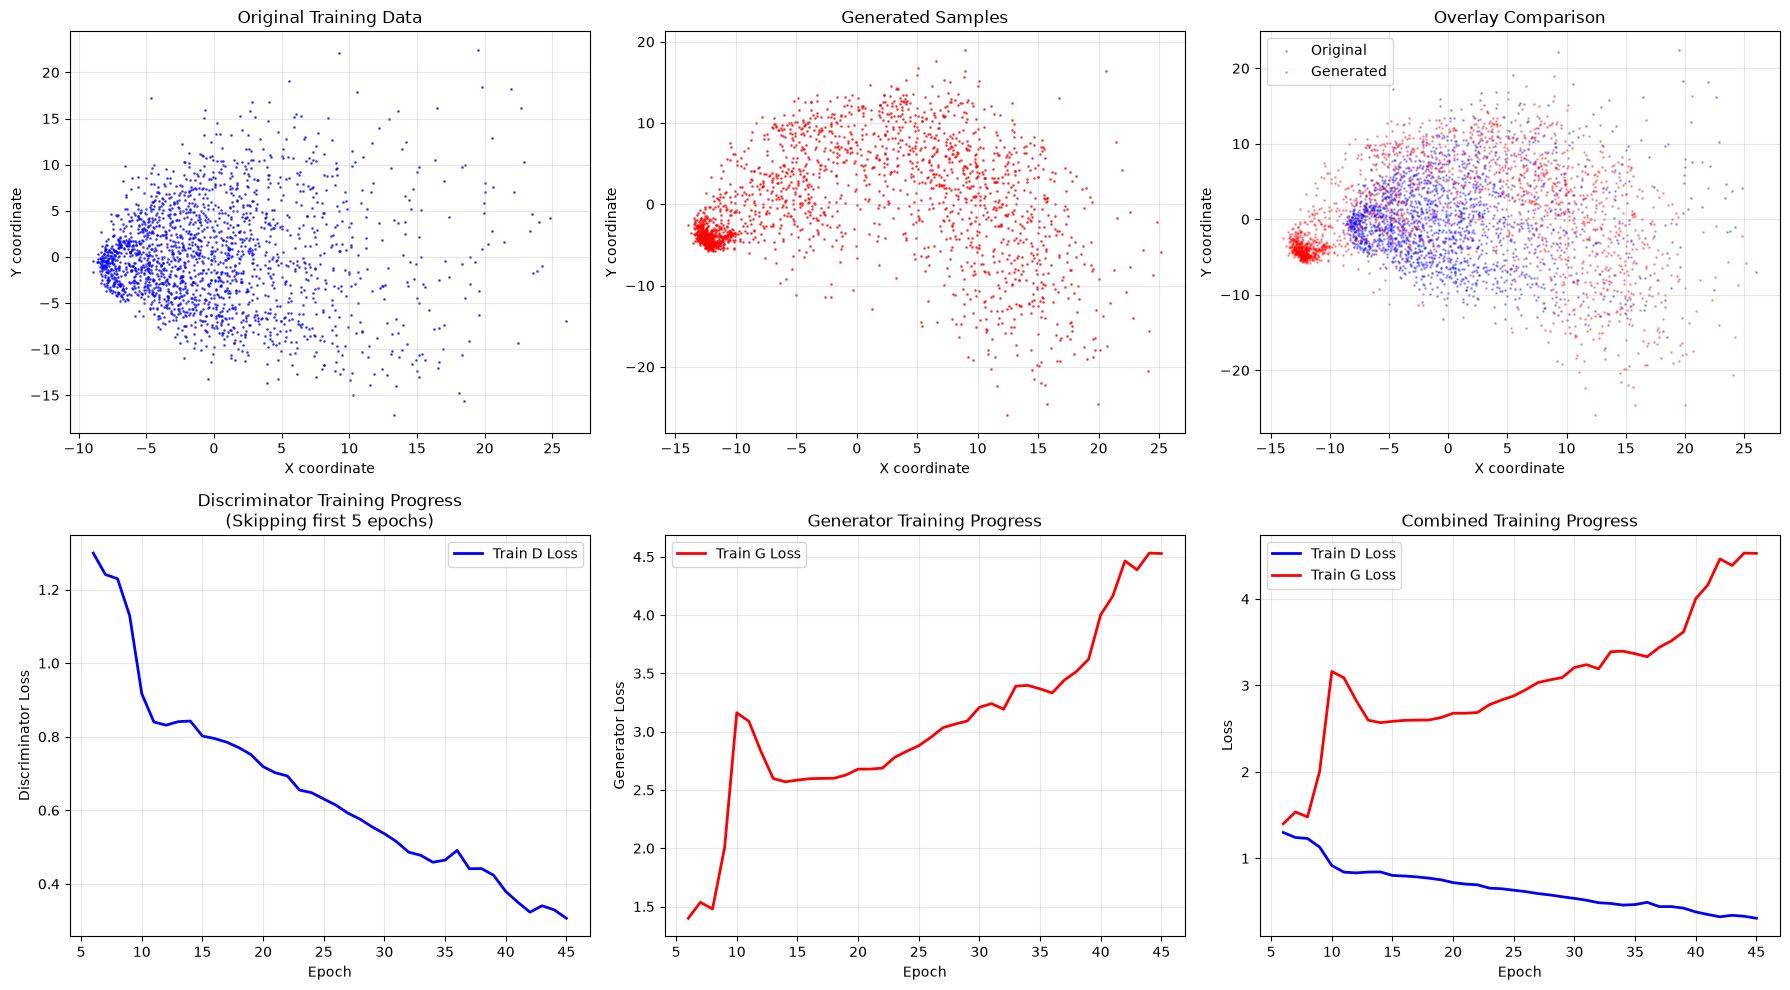

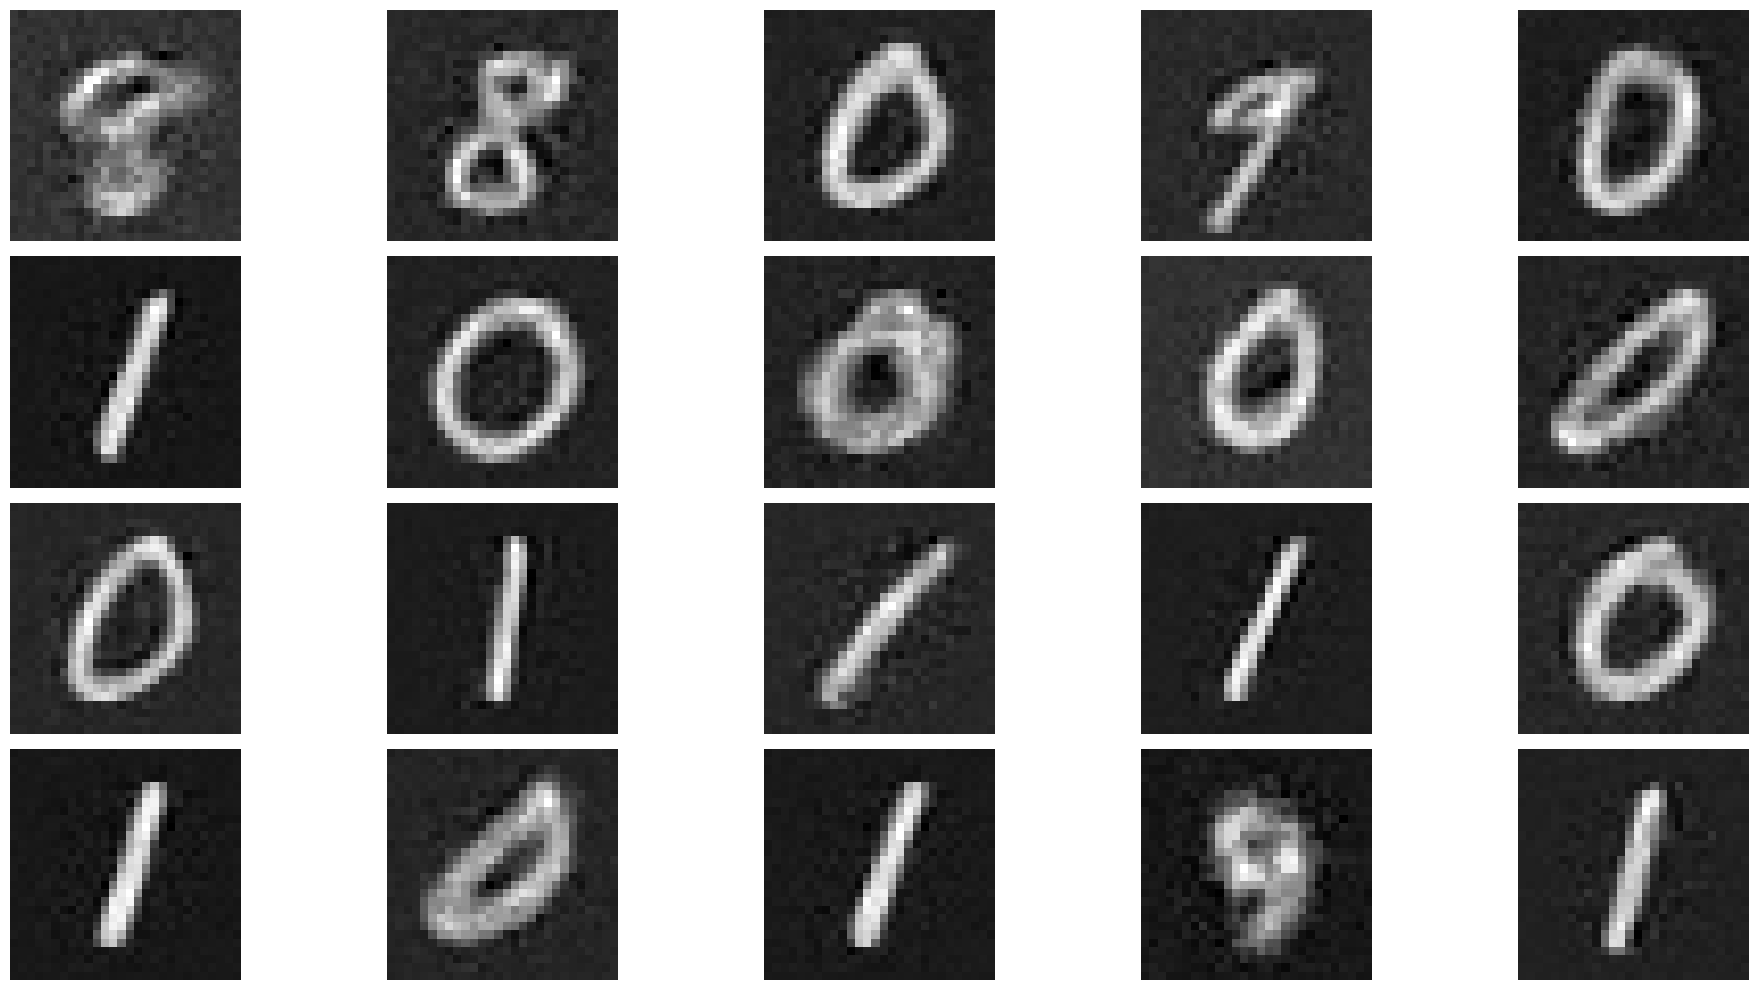

📈 Epoch 45 Summary:
   Train D Loss: 0.3066, Val D Loss: 0.3374
   Train G Loss: 4.5275, Val G Loss: 3.7388

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.277283	G_loss: 4.027083
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.340295	G_loss: 5.673849
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.258450	G_loss: 3.260062
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.252841	G_loss: 4.615900
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.322756	G_loss: 4.607440
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.106815	G_loss: 6.056958
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.502827	G_loss: 8.168797
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.372628	G_loss: 3.760831
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.253104	G_loss: 4.305813
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.391394	G_loss: 3.772007
====> Epoch: 46 Train D_loss: 0.2946, Train G_loss: 5.0278
====> Epoch: 46 Val D_loss: 0.3120, Val G_loss: 3.8128
📈 Epoch 46 Summary:
   Train D Loss: 0.2946, Val D Loss: 0.3120
   Train G Loss: 5.0278

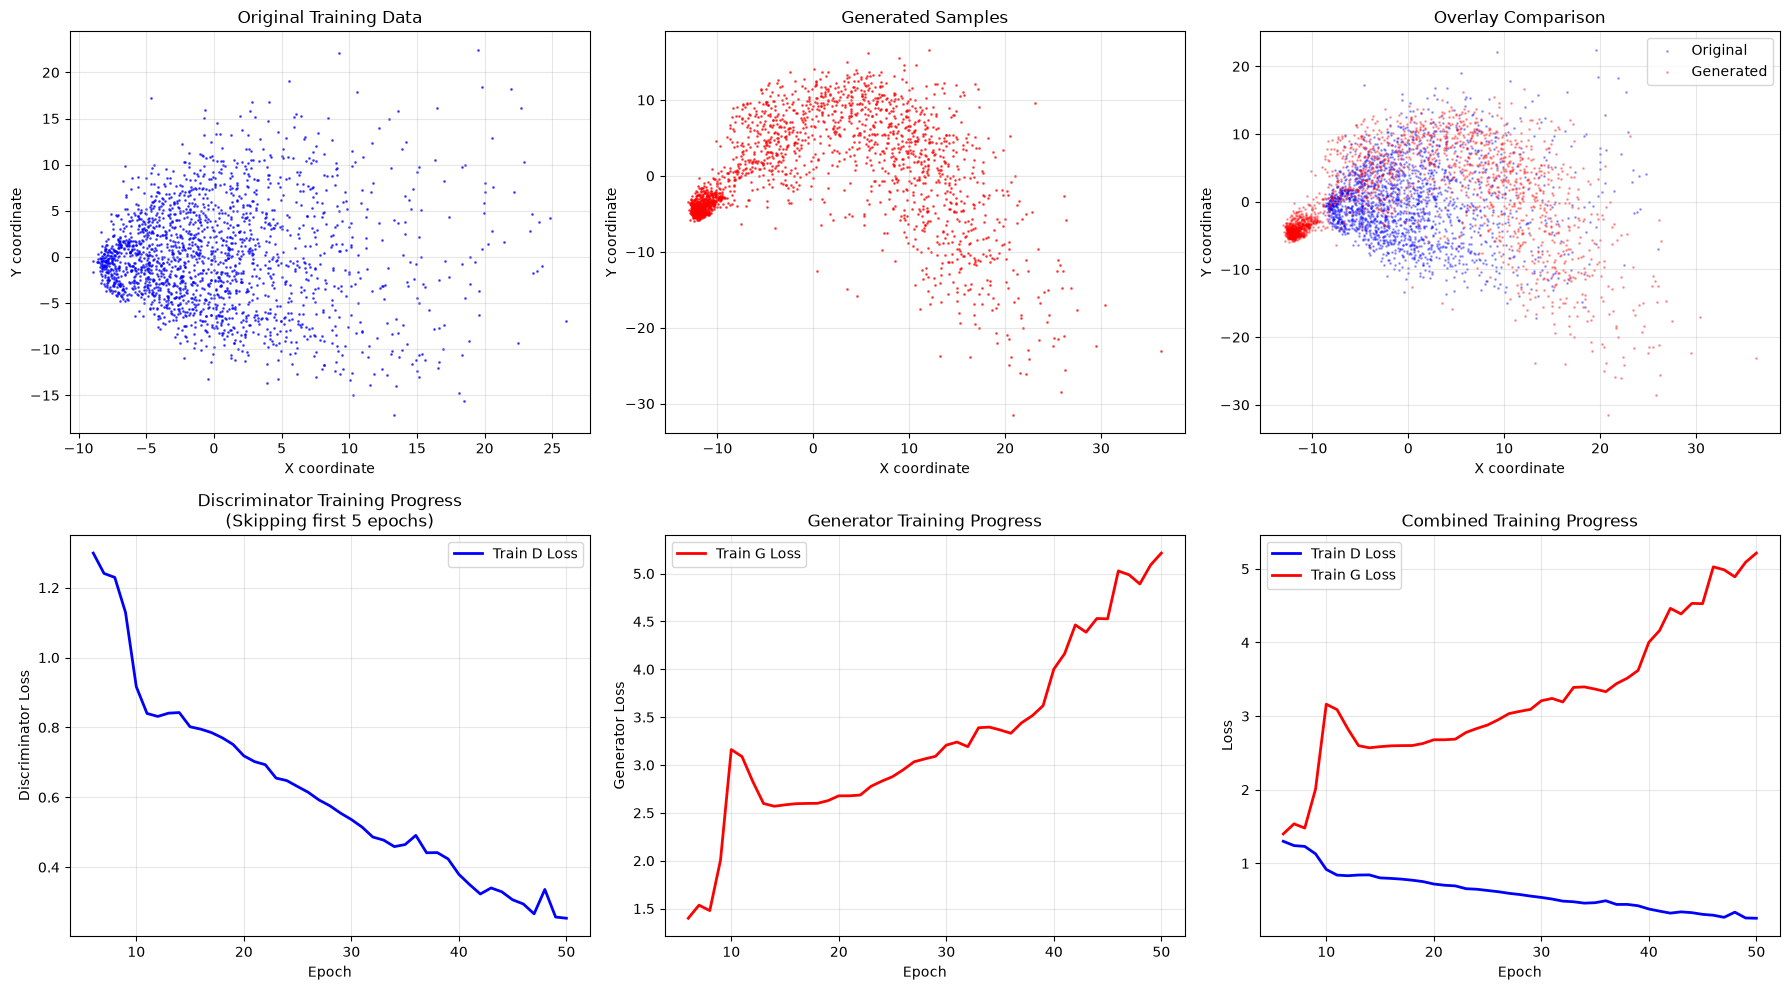

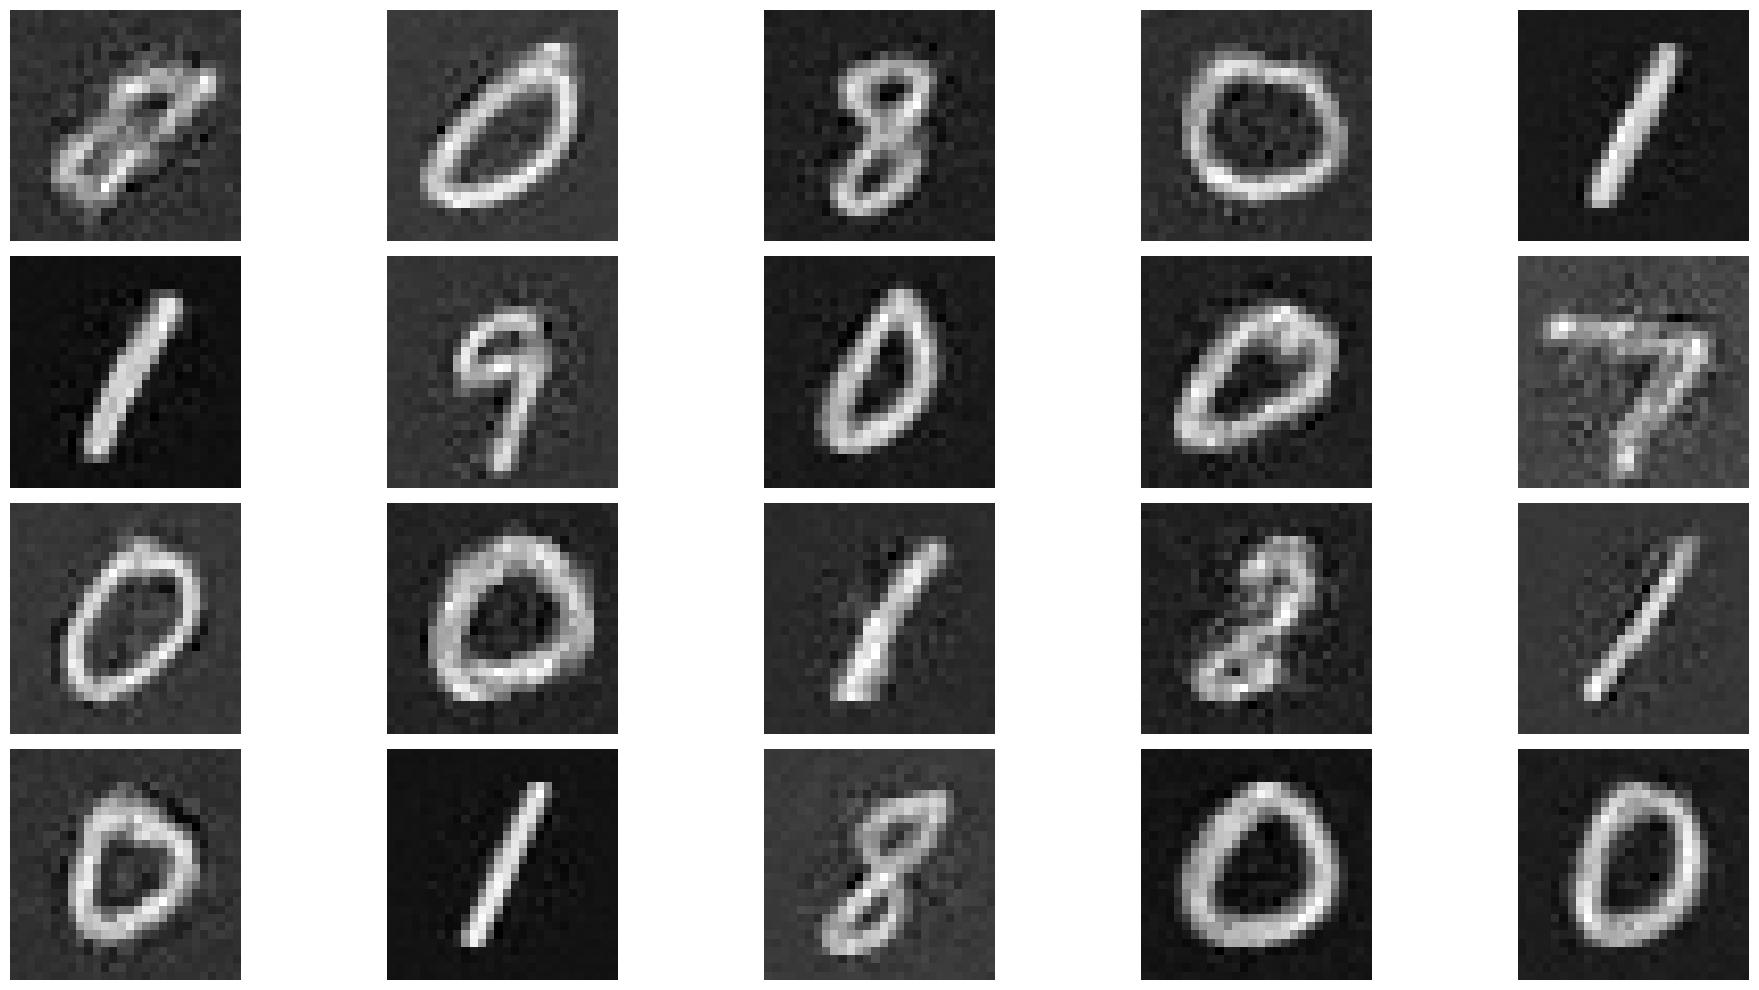

📈 Epoch 50 Summary:
   Train D Loss: 0.2538, Val D Loss: 0.5306
   Train G Loss: 5.2143, Val G Loss: 3.2147

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.544887	G_loss: 7.928843
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.411083	G_loss: 7.437549
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.474628	G_loss: 6.731468
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.174895	G_loss: 5.389330
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.200121	G_loss: 6.306314
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.212624	G_loss: 6.428419
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.353041	G_loss: 3.924373
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.243664	G_loss: 4.632304
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.216645	G_loss: 5.109447
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.202452	G_loss: 3.022216
====> Epoch: 51 Train D_loss: 0.2879, Train G_loss: 5.1931
====> Epoch: 51 Val D_loss: 0.3176, Val G_loss: 5.1707
📈 Epoch 51 Summary:
   Train D Loss: 0.2879, Val D Loss: 0.3176
   Train G Loss: 5.1931

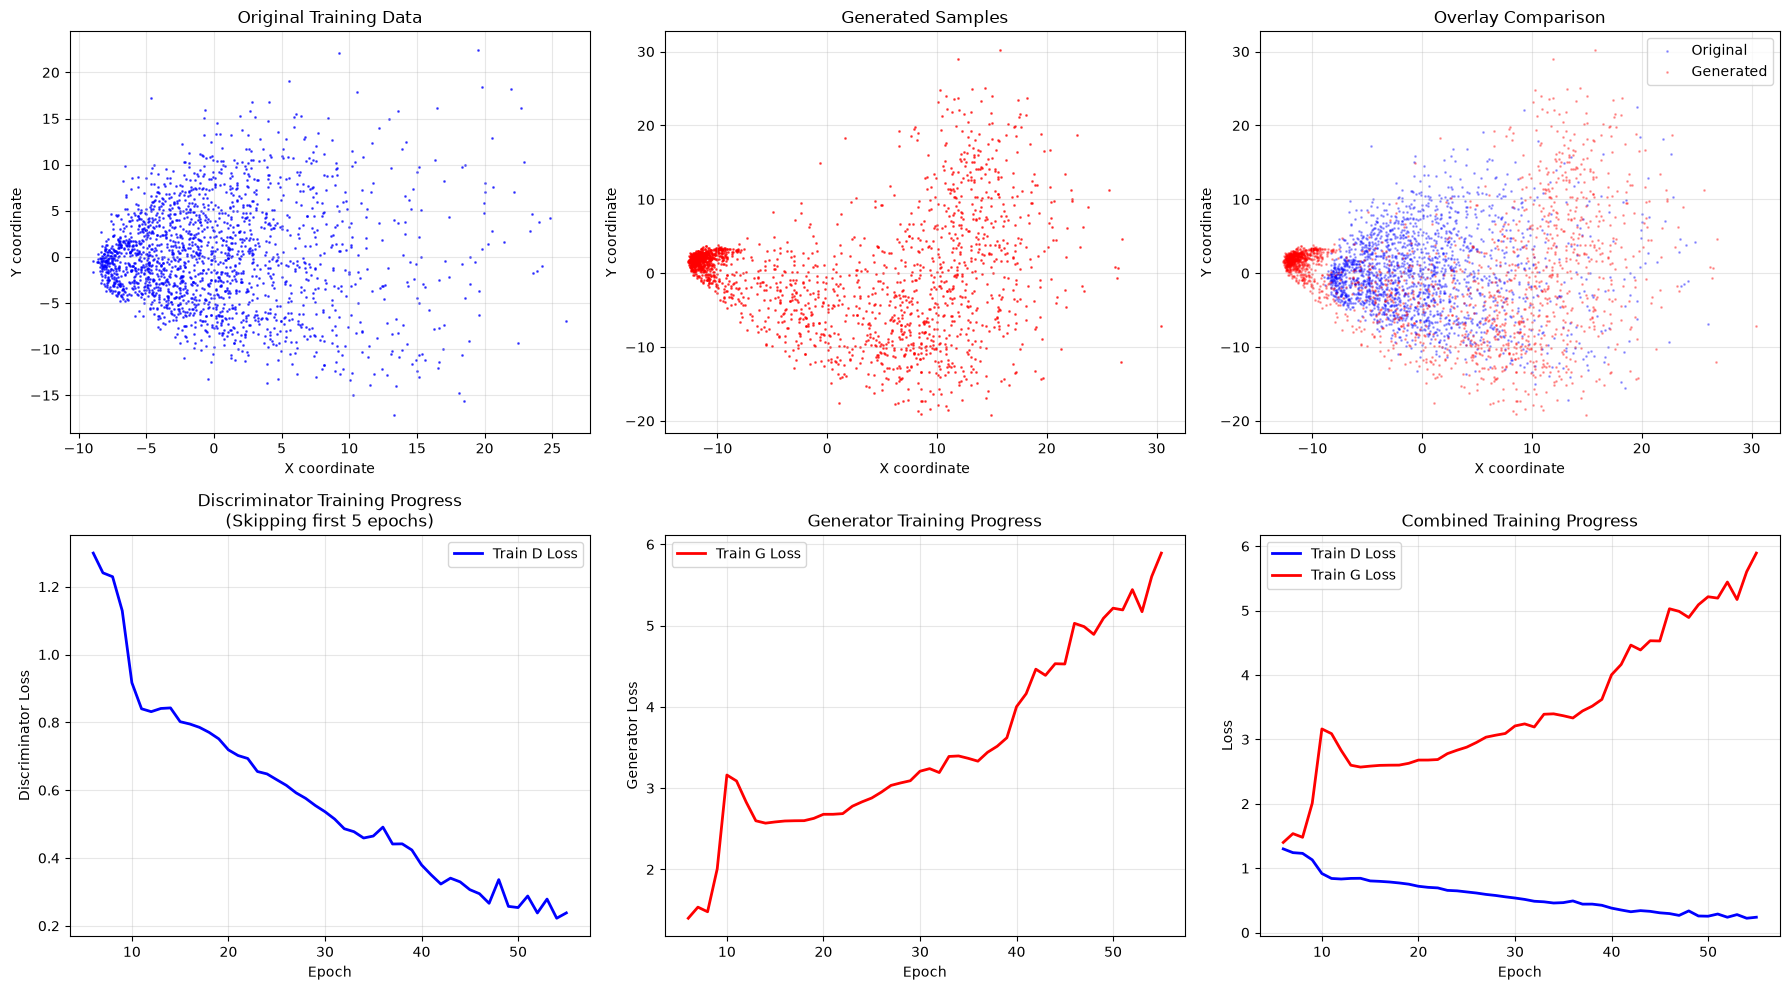

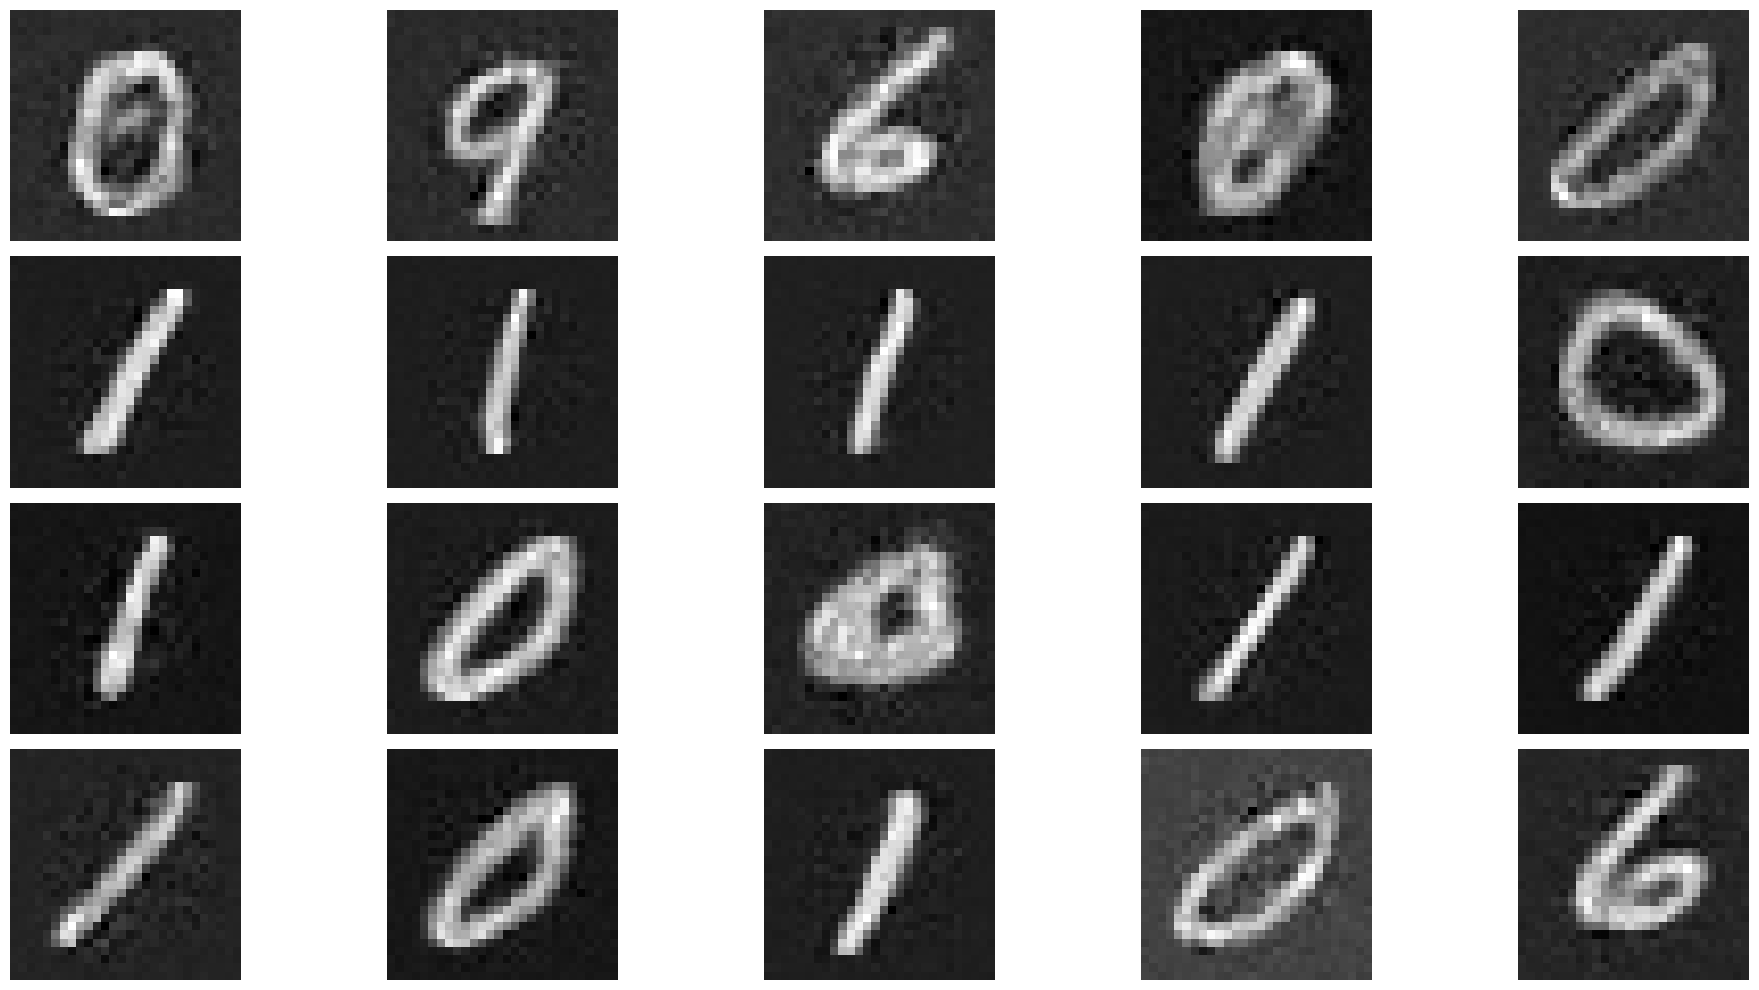

📈 Epoch 55 Summary:
   Train D Loss: 0.2381, Val D Loss: 0.1857
   Train G Loss: 5.8921, Val G Loss: 6.9379

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.198817	G_loss: 5.614215
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.197055	G_loss: 6.498138
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.165406	G_loss: 6.491301
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.183916	G_loss: 4.038212
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.133350	G_loss: 5.878136
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.283985	G_loss: 4.234803
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.219165	G_loss: 4.427404
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.201821	G_loss: 5.984326
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.178333	G_loss: 5.546054
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.190959	G_loss: 3.749505
====> Epoch: 56 Train D_loss: 0.2096, Train G_loss: 5.9848
====> Epoch: 56 Val D_loss: 0.2797, Val G_loss: 7.7155
📈 Epoch 56 Summary:
   Train D Loss: 0.2096, Val D Loss: 0.2797
   Train G Loss: 5.9848

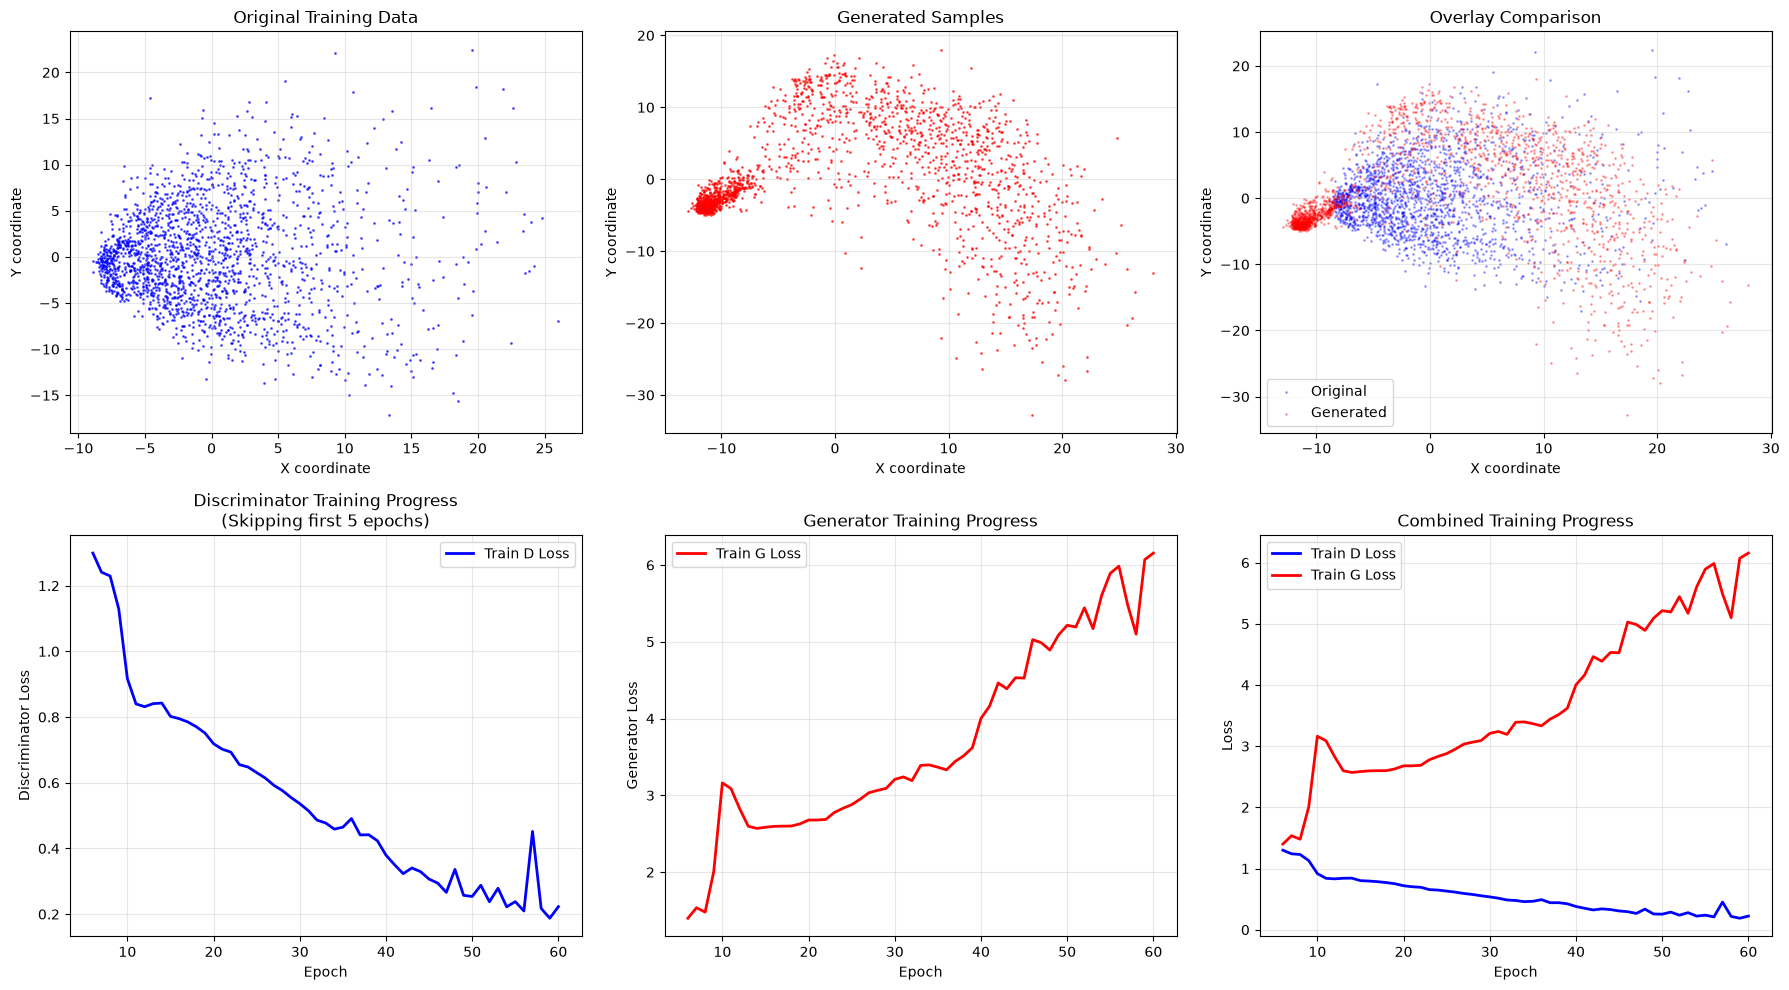

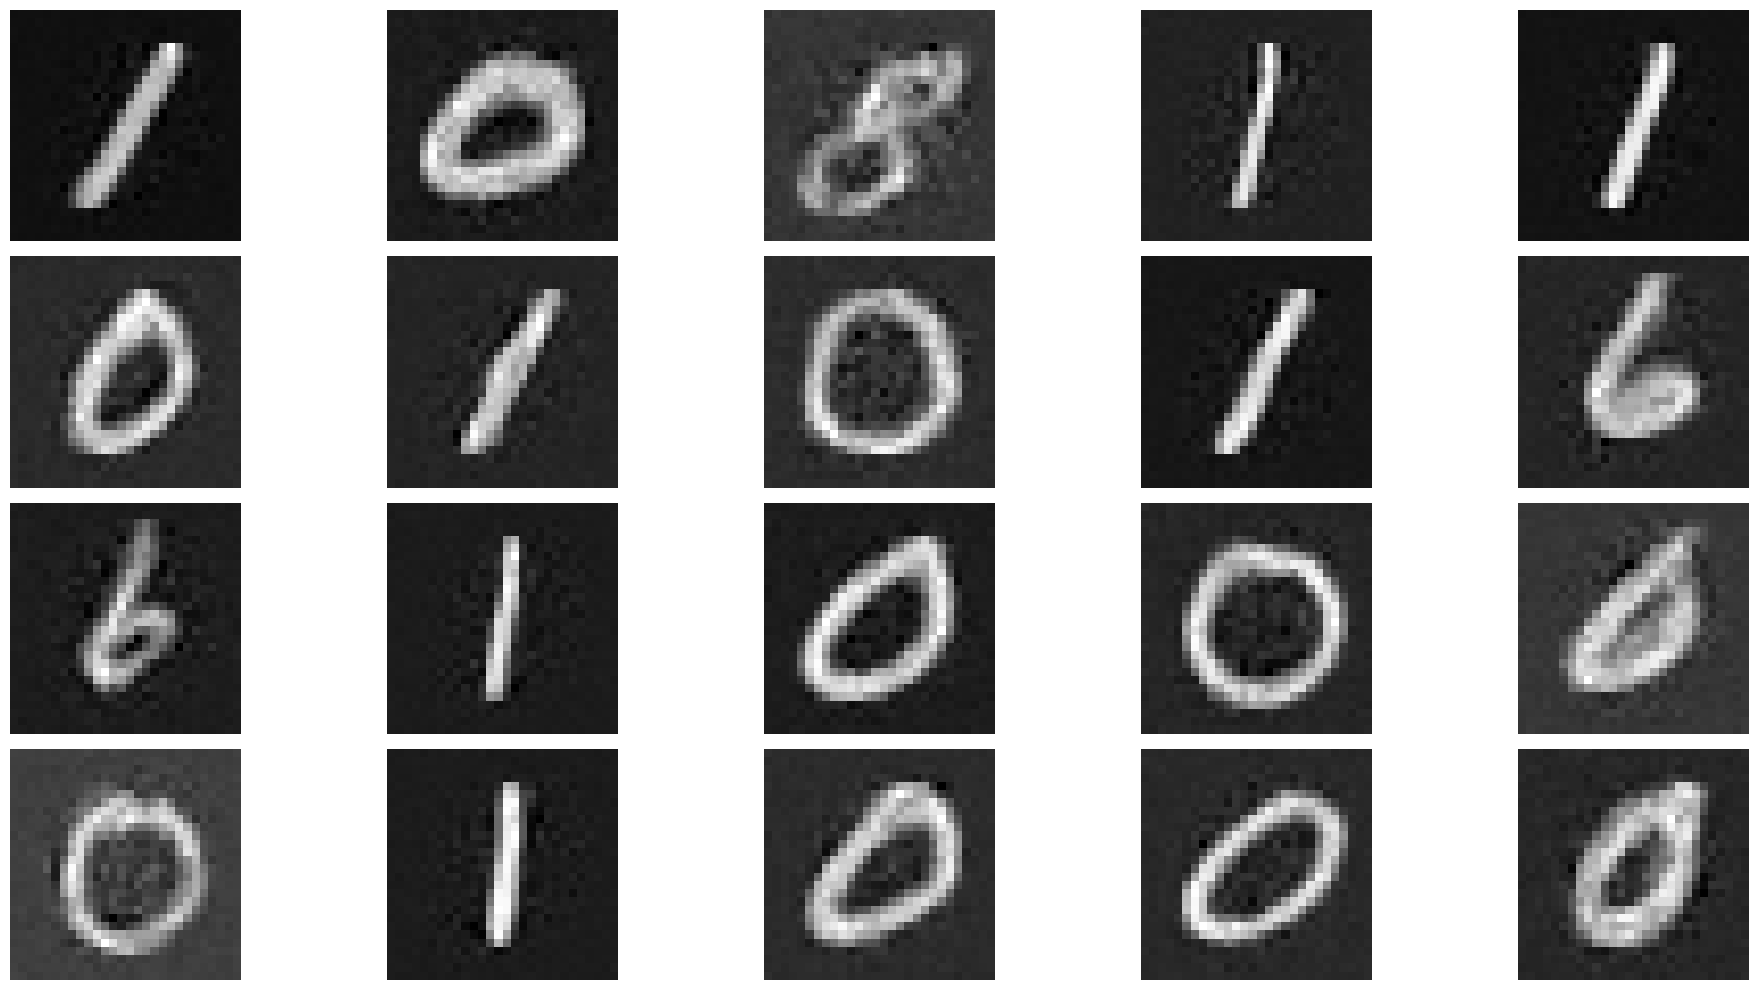

📈 Epoch 60 Summary:
   Train D Loss: 0.2228, Val D Loss: 0.1958
   Train G Loss: 6.1550, Val G Loss: 3.9045

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.119329	G_loss: 5.034810
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.465405	G_loss: 3.996756
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.115691	G_loss: 7.030098
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.106729	G_loss: 5.303617
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.264172	G_loss: 5.869833
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.104938	G_loss: 6.900463
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.168955	G_loss: 11.214487
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.202908	G_loss: 5.927500
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.199321	G_loss: 5.143628
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.144671	G_loss: 5.830549
====> Epoch: 61 Train D_loss: 0.1907, Train G_loss: 6.2357
====> Epoch: 61 Val D_loss: 0.2883, Val G_loss: 3.5699
📈 Epoch 61 Summary:
   Train D Loss: 0.1907, Val D Loss: 0.2883
   Train G Loss: 6.235

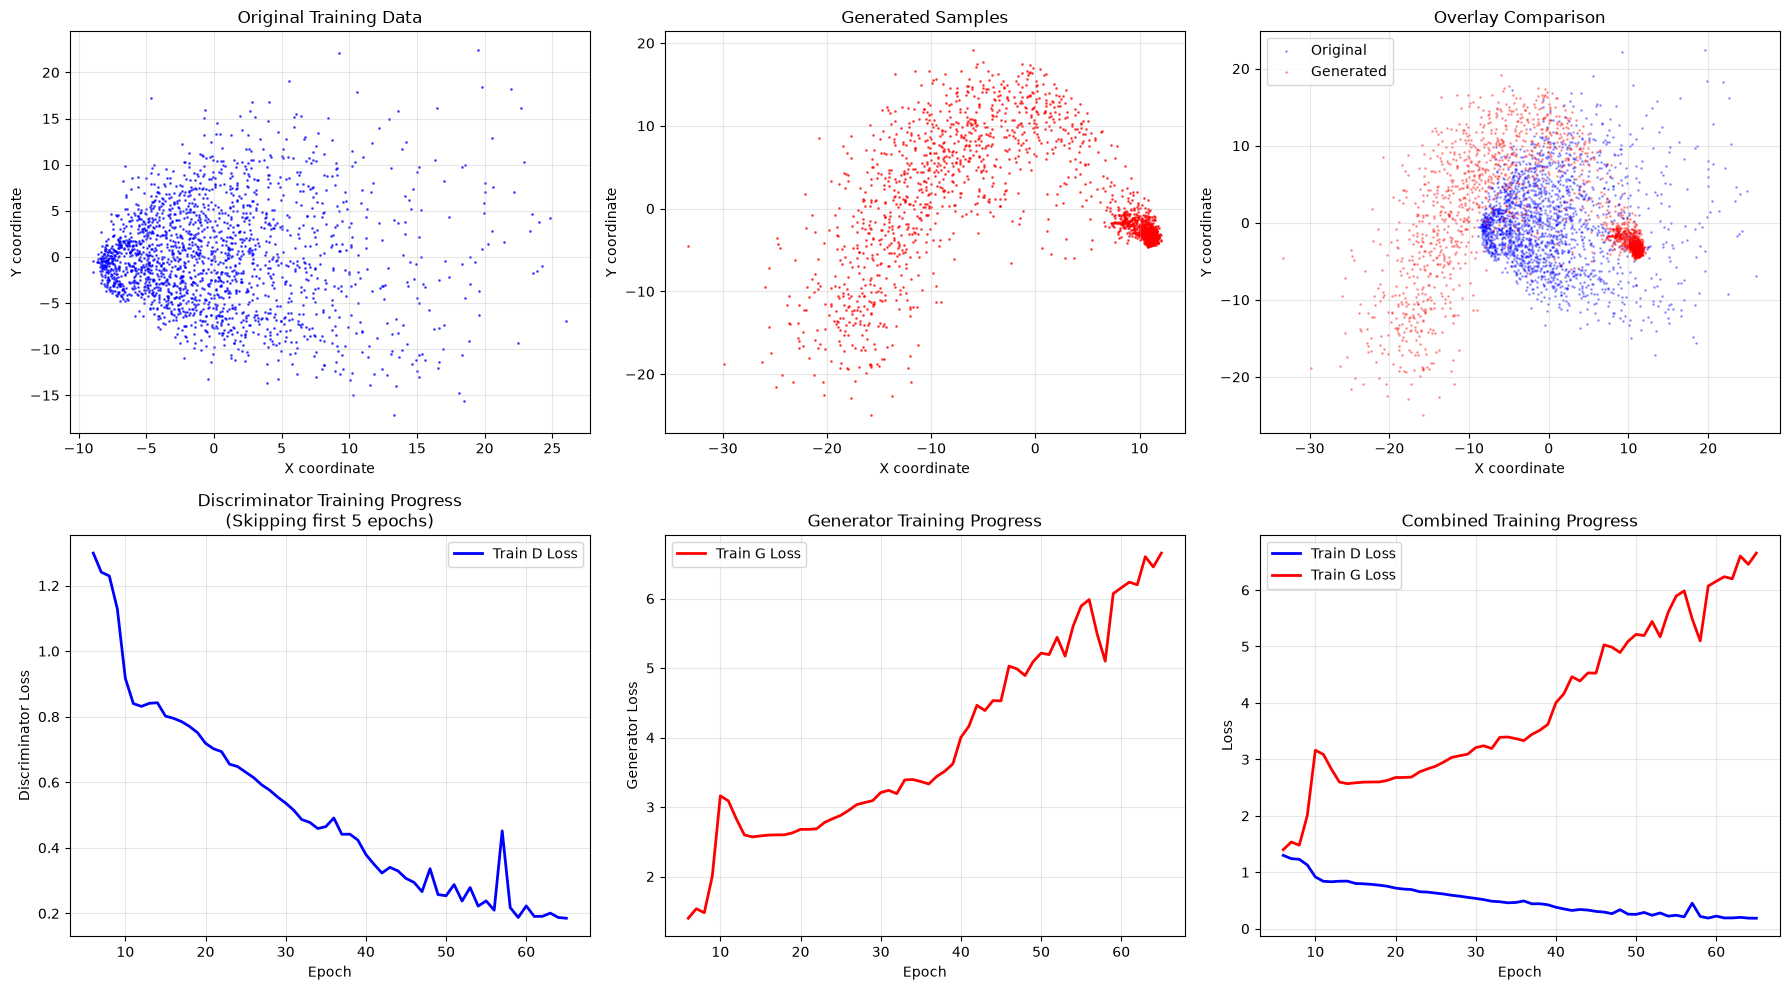

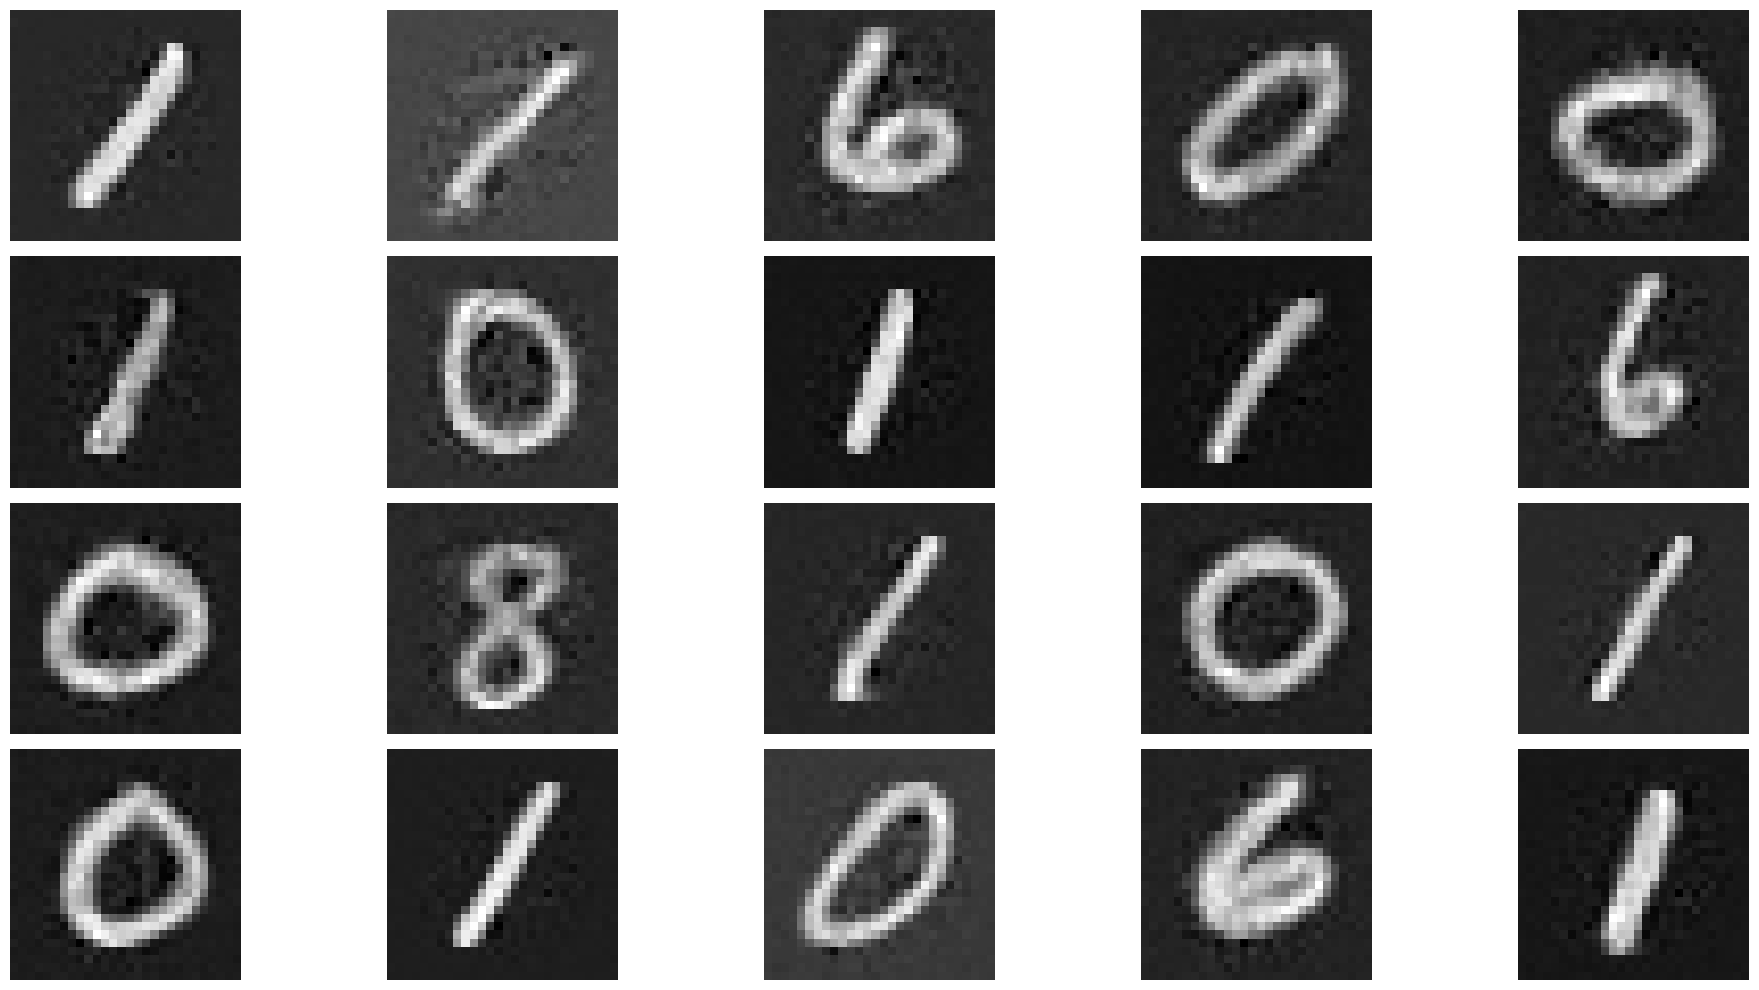

📈 Epoch 65 Summary:
   Train D Loss: 0.1852, Val D Loss: 0.8564
   Train G Loss: 6.6539, Val G Loss: 9.6637

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.689397	G_loss: 12.282492
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.041427	G_loss: 9.097240
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.091732	G_loss: 6.879801
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.109708	G_loss: 7.282885
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.203488	G_loss: 8.120290
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.086307	G_loss: 9.643250
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.039257	G_loss: 7.946405
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.169274	G_loss: 7.045003
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.141200	G_loss: 6.247349
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.083212	G_loss: 5.436531
====> Epoch: 66 Train D_loss: 0.1682, Train G_loss: 6.6869
====> Epoch: 66 Val D_loss: 0.1821, Val G_loss: 5.2134
📈 Epoch 66 Summary:
   Train D Loss: 0.1682, Val D Loss: 0.1821
   Train G Loss: 6.686

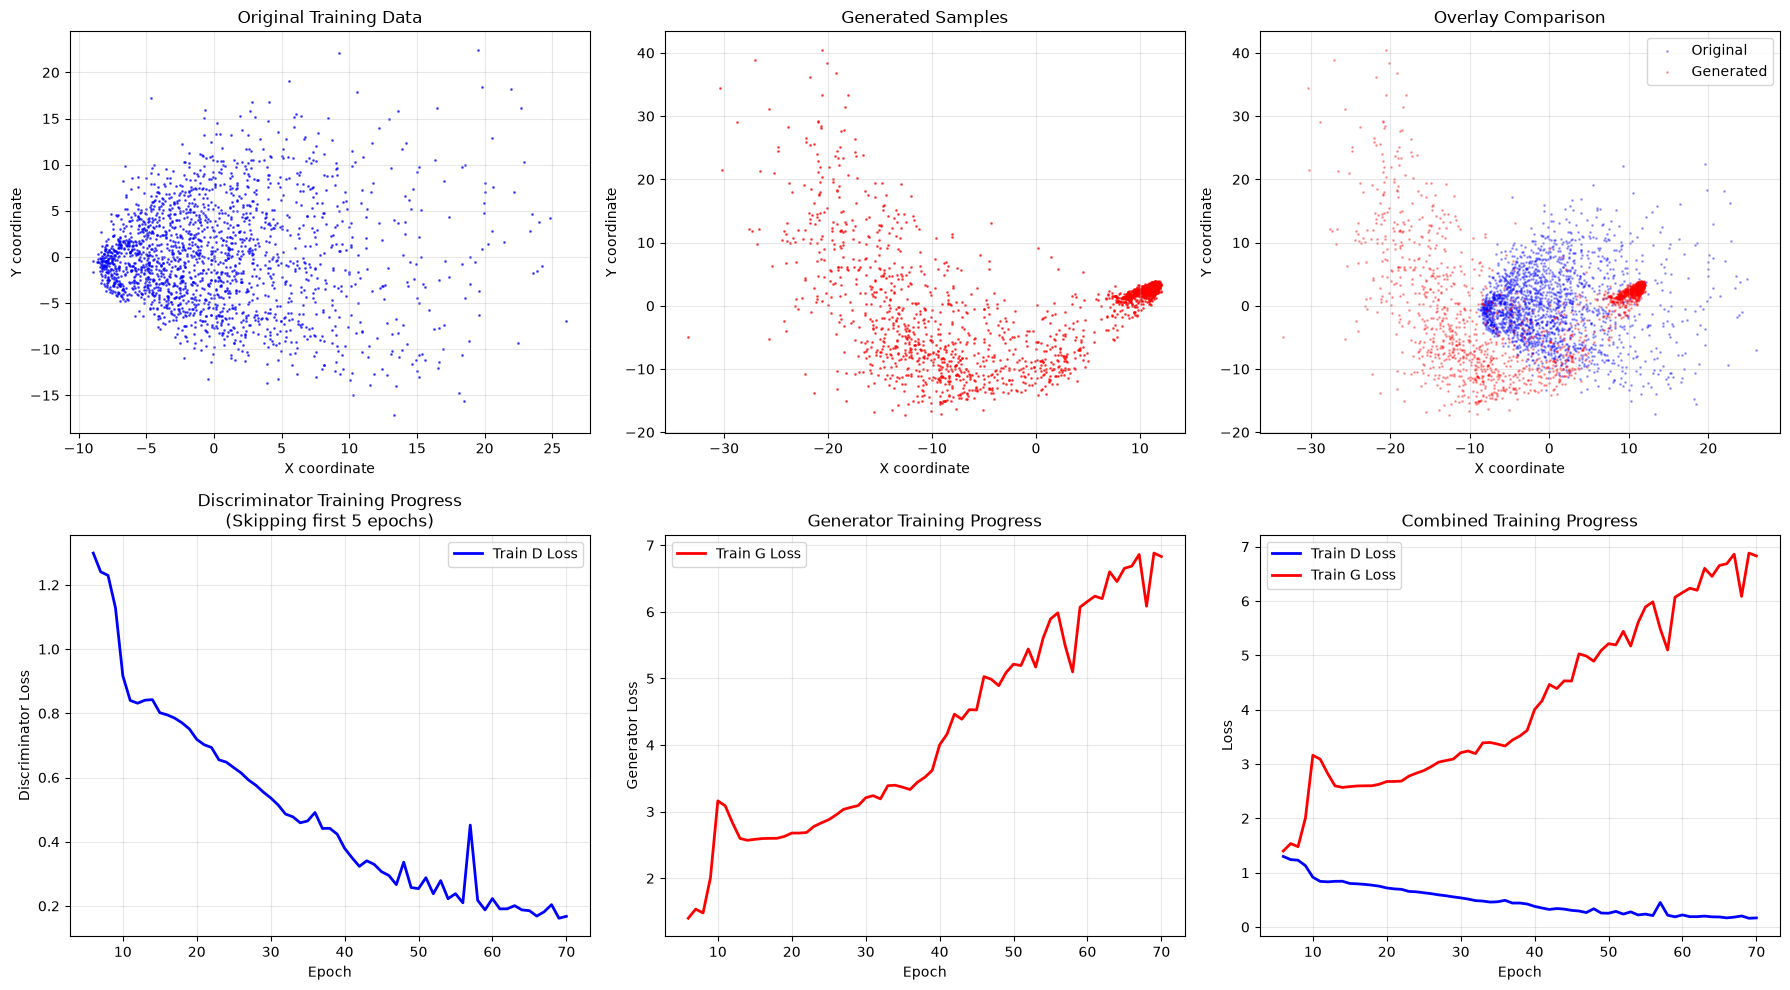

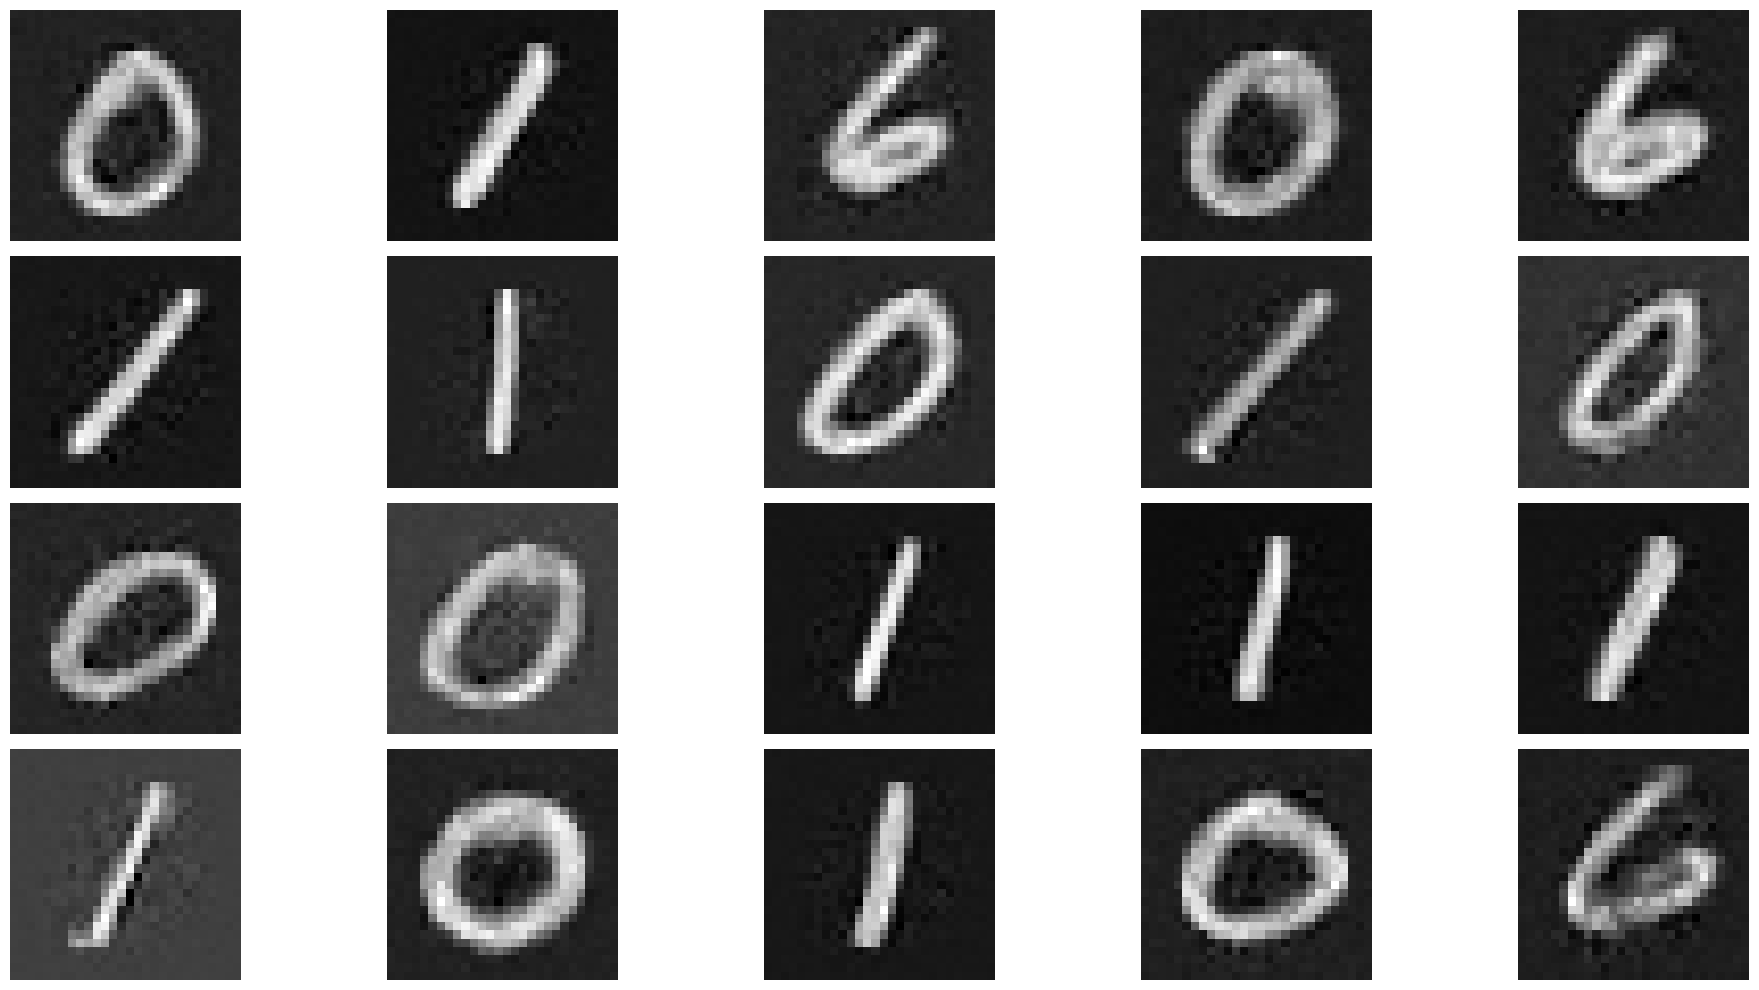

📈 Epoch 70 Summary:
   Train D Loss: 0.1675, Val D Loss: 0.1527
   Train G Loss: 6.8307, Val G Loss: 6.8816

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.109900	G_loss: 6.350105
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.058598	G_loss: 10.388533
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.135229	G_loss: 8.745234
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.265250	G_loss: 13.206045
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.206821	G_loss: 6.391750
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.097786	G_loss: 5.716196
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.047778	G_loss: 7.262221
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.120825	G_loss: 9.064238
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.109220	G_loss: 11.839388
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.088414	G_loss: 5.549839
====> Epoch: 71 Train D_loss: 0.1593, Train G_loss: 7.0847
====> Epoch: 71 Val D_loss: 0.1971, Val G_loss: 4.2285
📈 Epoch 71 Summary:
   Train D Loss: 0.1593, Val D Loss: 0.1971
   Train G Loss: 7.0

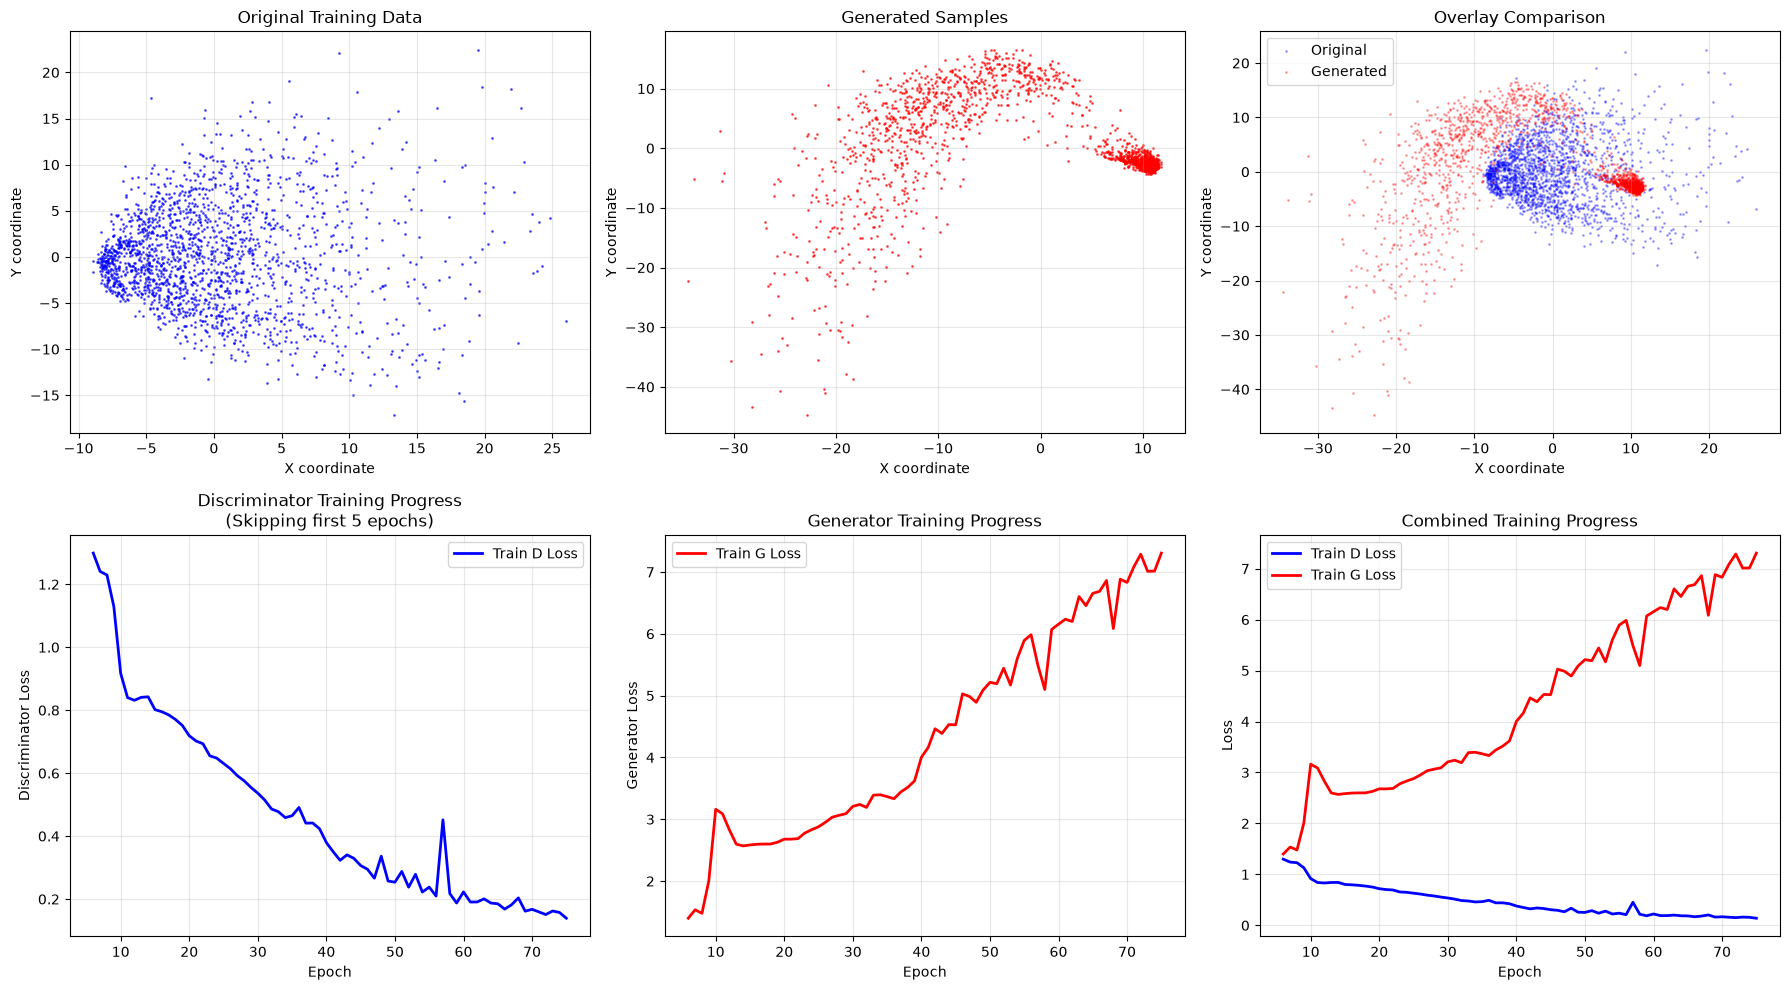

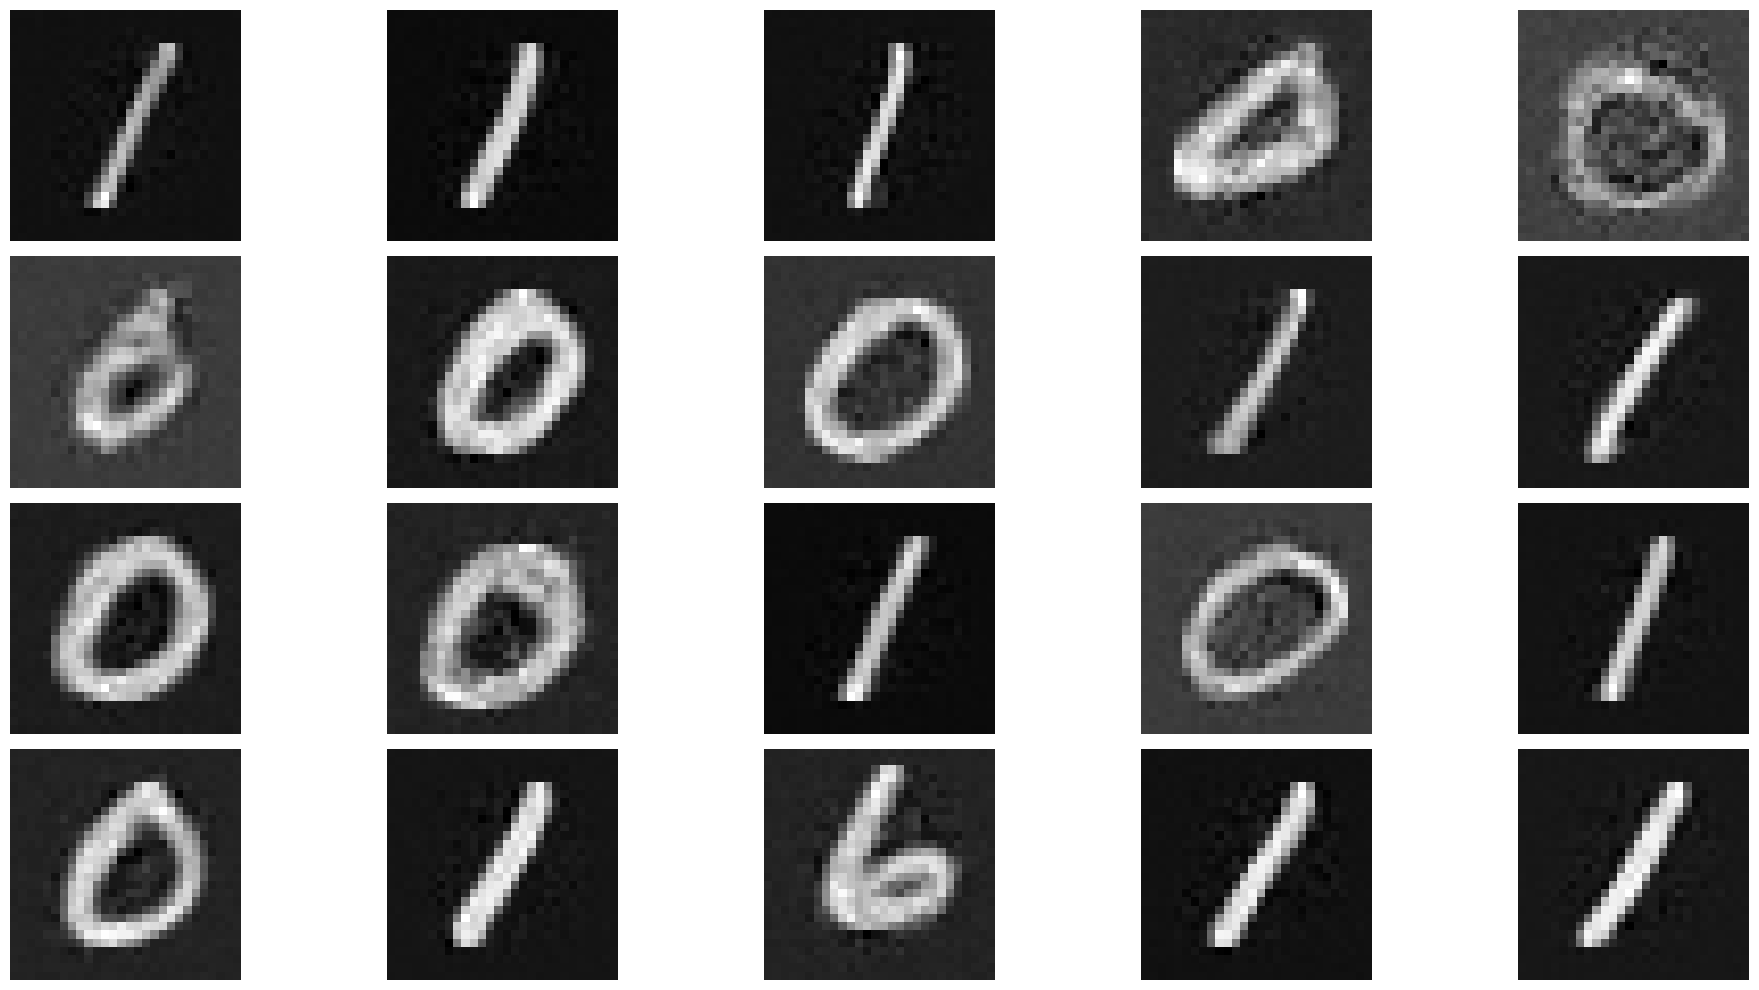

📈 Epoch 75 Summary:
   Train D Loss: 0.1392, Val D Loss: 0.1278
   Train G Loss: 7.3051, Val G Loss: 11.0298

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.147438	G_loss: 9.916626
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.226559	G_loss: 6.513548
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.114746	G_loss: 10.821219
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.363279	G_loss: 5.752412
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.080560	G_loss: 6.948577
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.073253	G_loss: 8.318989
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.070518	G_loss: 6.586513
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.170788	G_loss: 5.274473
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.217160	G_loss: 4.921895
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.089953	G_loss: 13.161615
====> Epoch: 76 Train D_loss: 0.1467, Train G_loss: 7.5242
====> Epoch: 76 Val D_loss: 0.2501, Val G_loss: 5.0060
📈 Epoch 76 Summary:
   Train D Loss: 0.1467, Val D Loss: 0.2501
   Train G Loss: 7.5

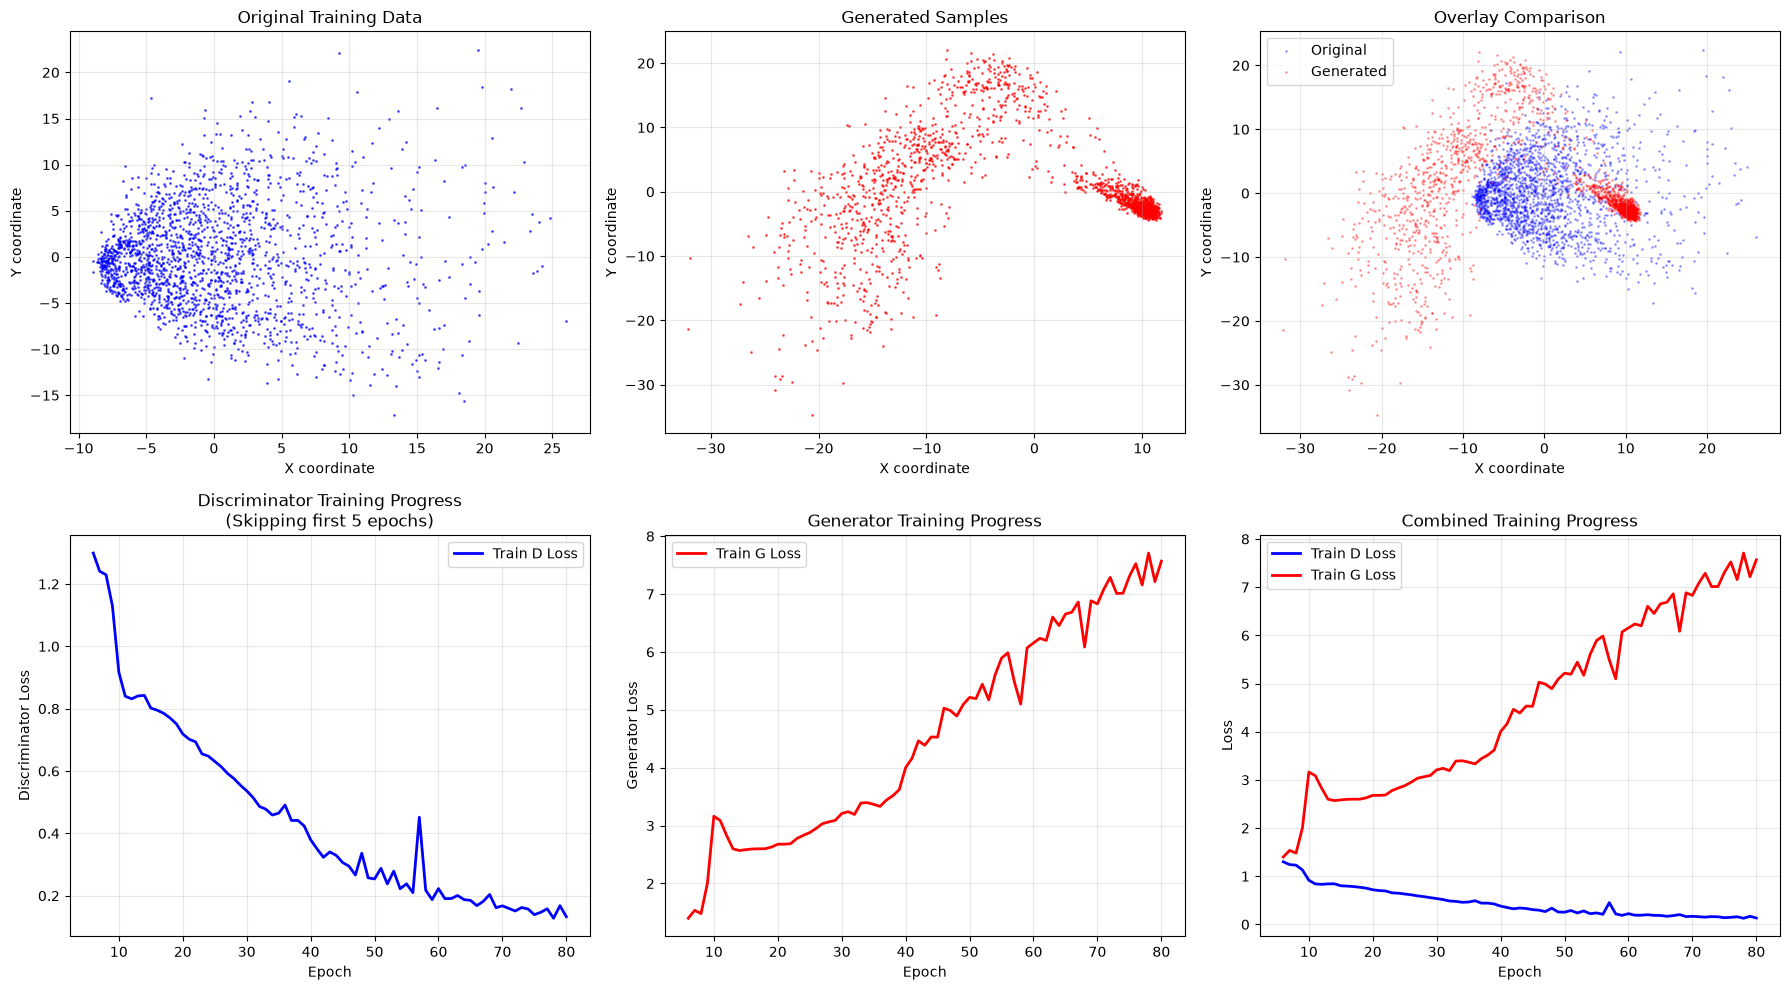

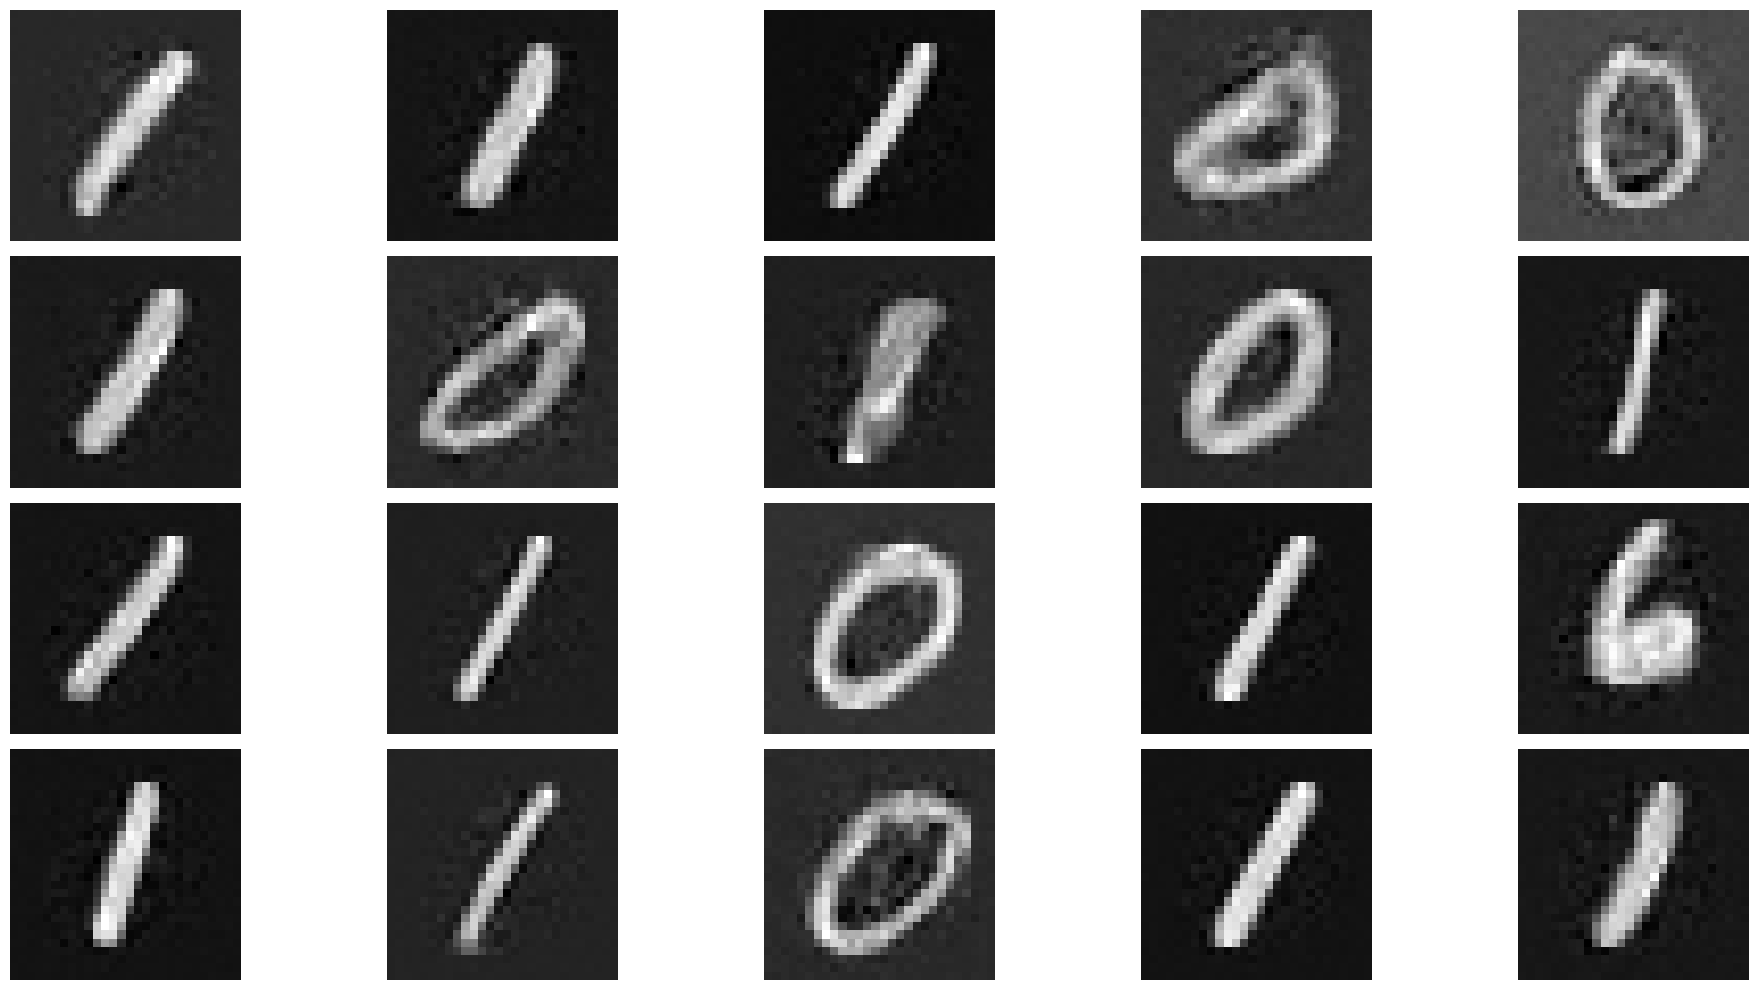

📈 Epoch 80 Summary:
   Train D Loss: 0.1326, Val D Loss: 0.3717
   Train G Loss: 7.5678, Val G Loss: 5.5899

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.264803	G_loss: 6.687358
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.207250	G_loss: 6.154869
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.211741	G_loss: 5.157376
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.040222	G_loss: 13.253427
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.182356	G_loss: 10.502968
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.135283	G_loss: 6.387326
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.063759	G_loss: 6.848166
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.109541	G_loss: 7.801889
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.122232	G_loss: 5.641295
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.130264	G_loss: 6.252990
====> Epoch: 81 Train D_loss: 0.1318, Train G_loss: 7.4439
====> Epoch: 81 Val D_loss: 0.1232, Val G_loss: 7.2745
📈 Epoch 81 Summary:
   Train D Loss: 0.1318, Val D Loss: 0.1232
   Train G Loss: 7.44

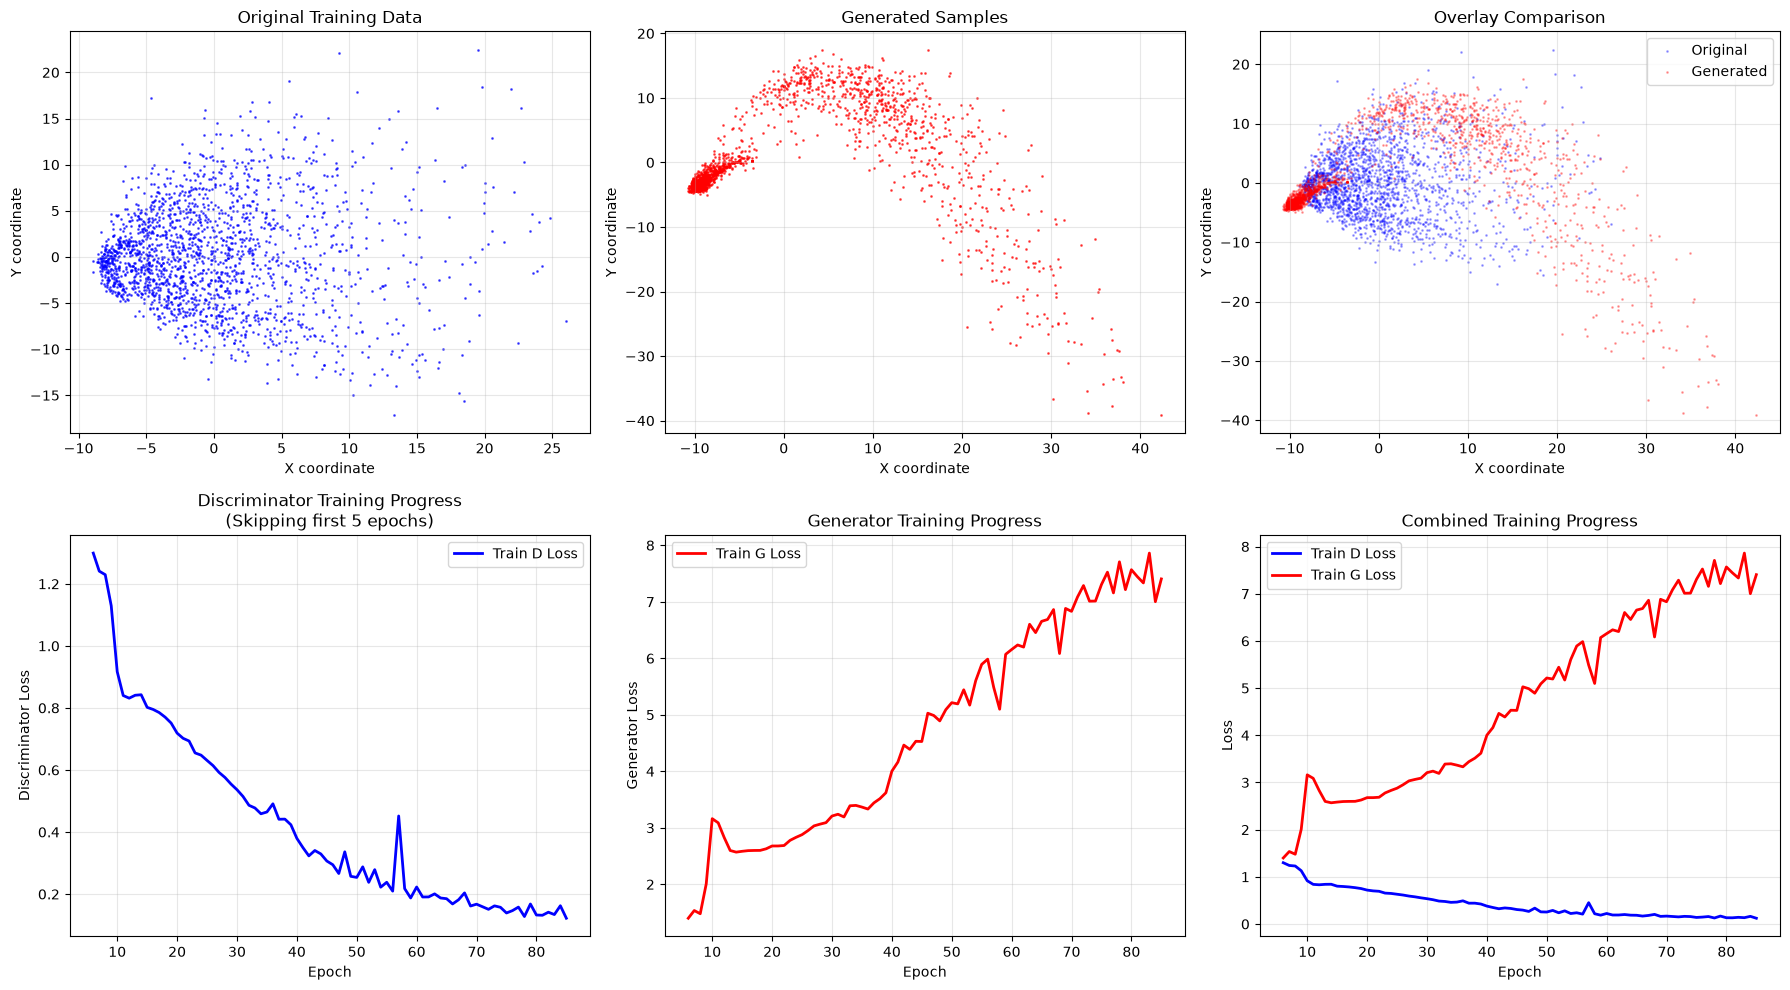

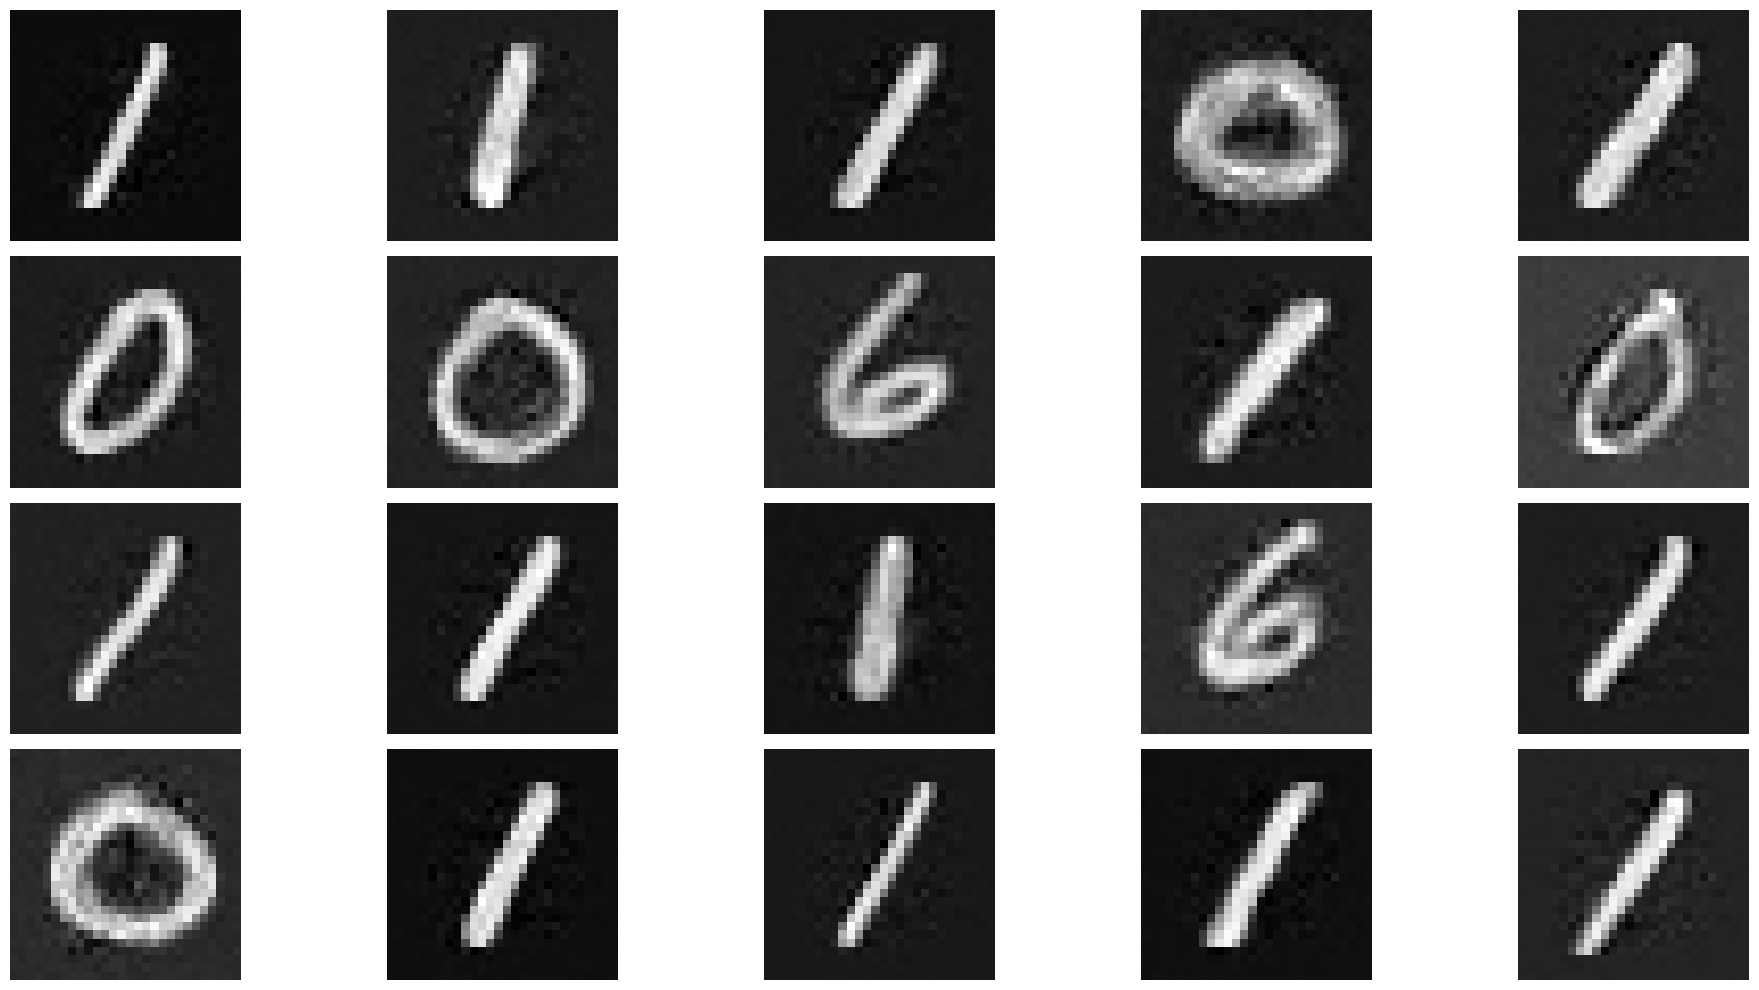

📈 Epoch 85 Summary:
   Train D Loss: 0.1222, Val D Loss: 0.1777
   Train G Loss: 7.4048, Val G Loss: 4.6376

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.118750	G_loss: 5.987116
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.018657	G_loss: 7.094950
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.094522	G_loss: 5.870474
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.074890	G_loss: 10.684288
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.120245	G_loss: 5.625887
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.086790	G_loss: 10.423756
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.125148	G_loss: 6.235852
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.184748	G_loss: 5.814455
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.236324	G_loss: 6.711731
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.115462	G_loss: 7.036863
====> Epoch: 86 Train D_loss: 0.1175, Train G_loss: 7.9121
====> Epoch: 86 Val D_loss: 0.1462, Val G_loss: 5.6627
📈 Epoch 86 Summary:
   Train D Loss: 0.1175, Val D Loss: 0.1462
   Train G Loss: 7.91

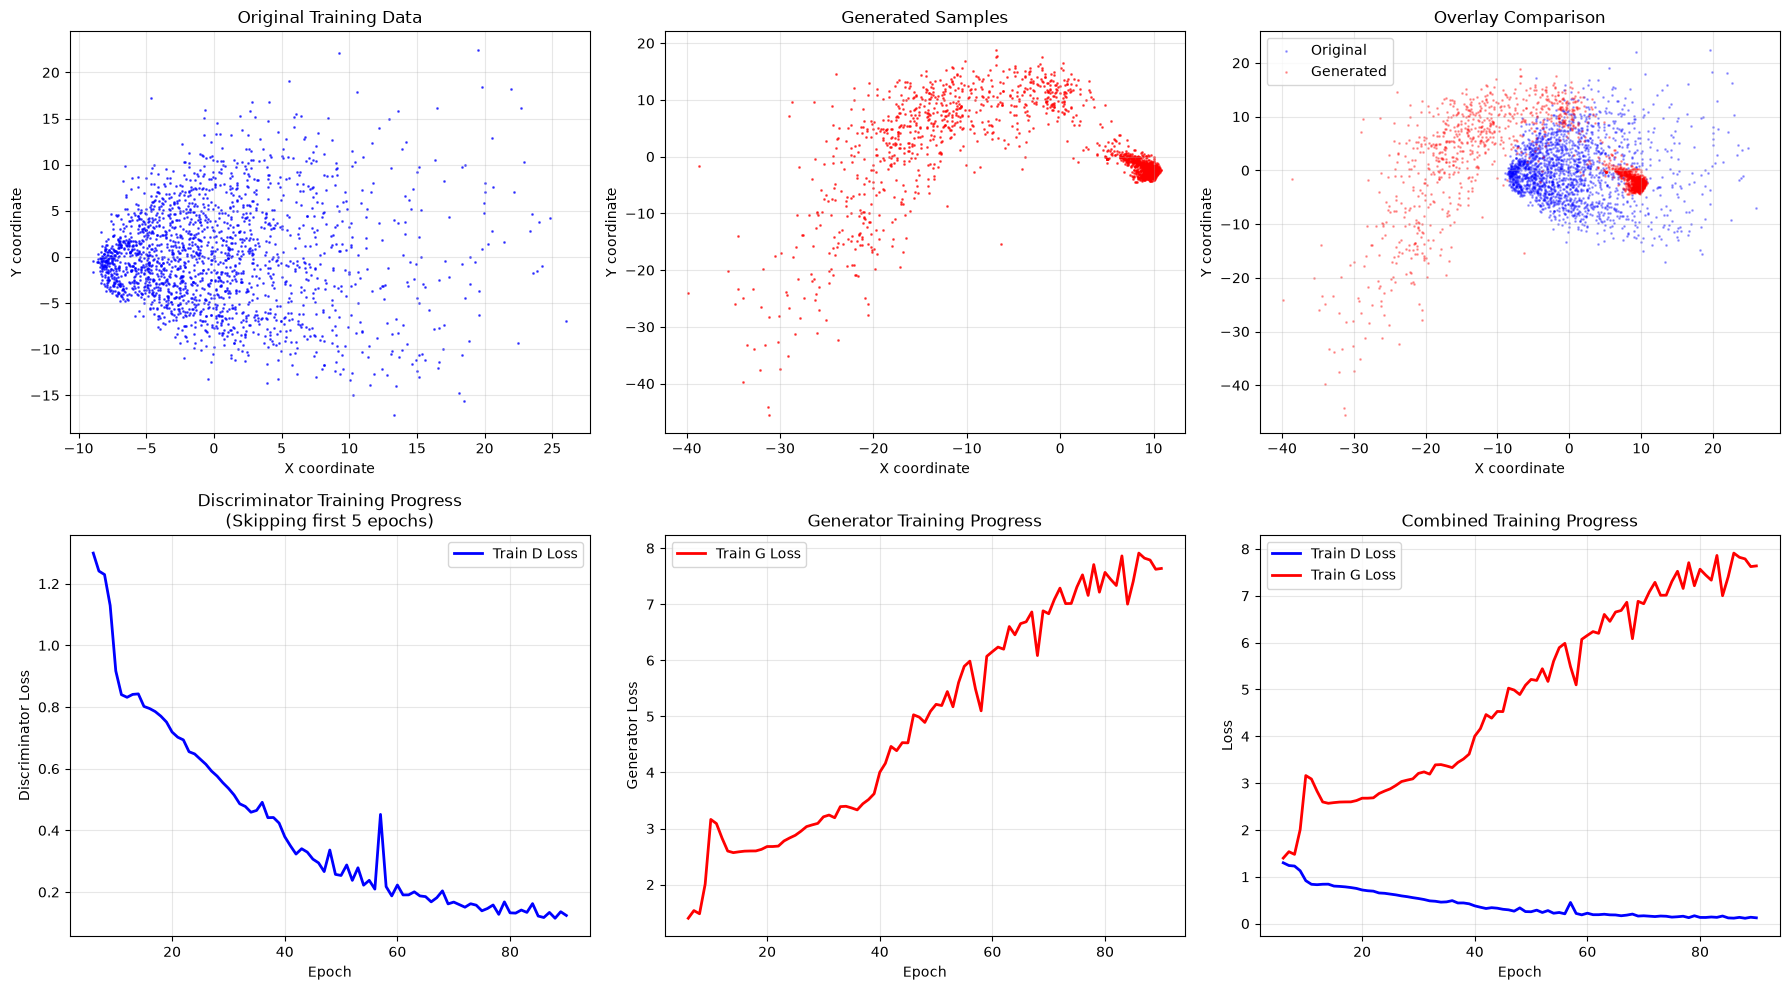

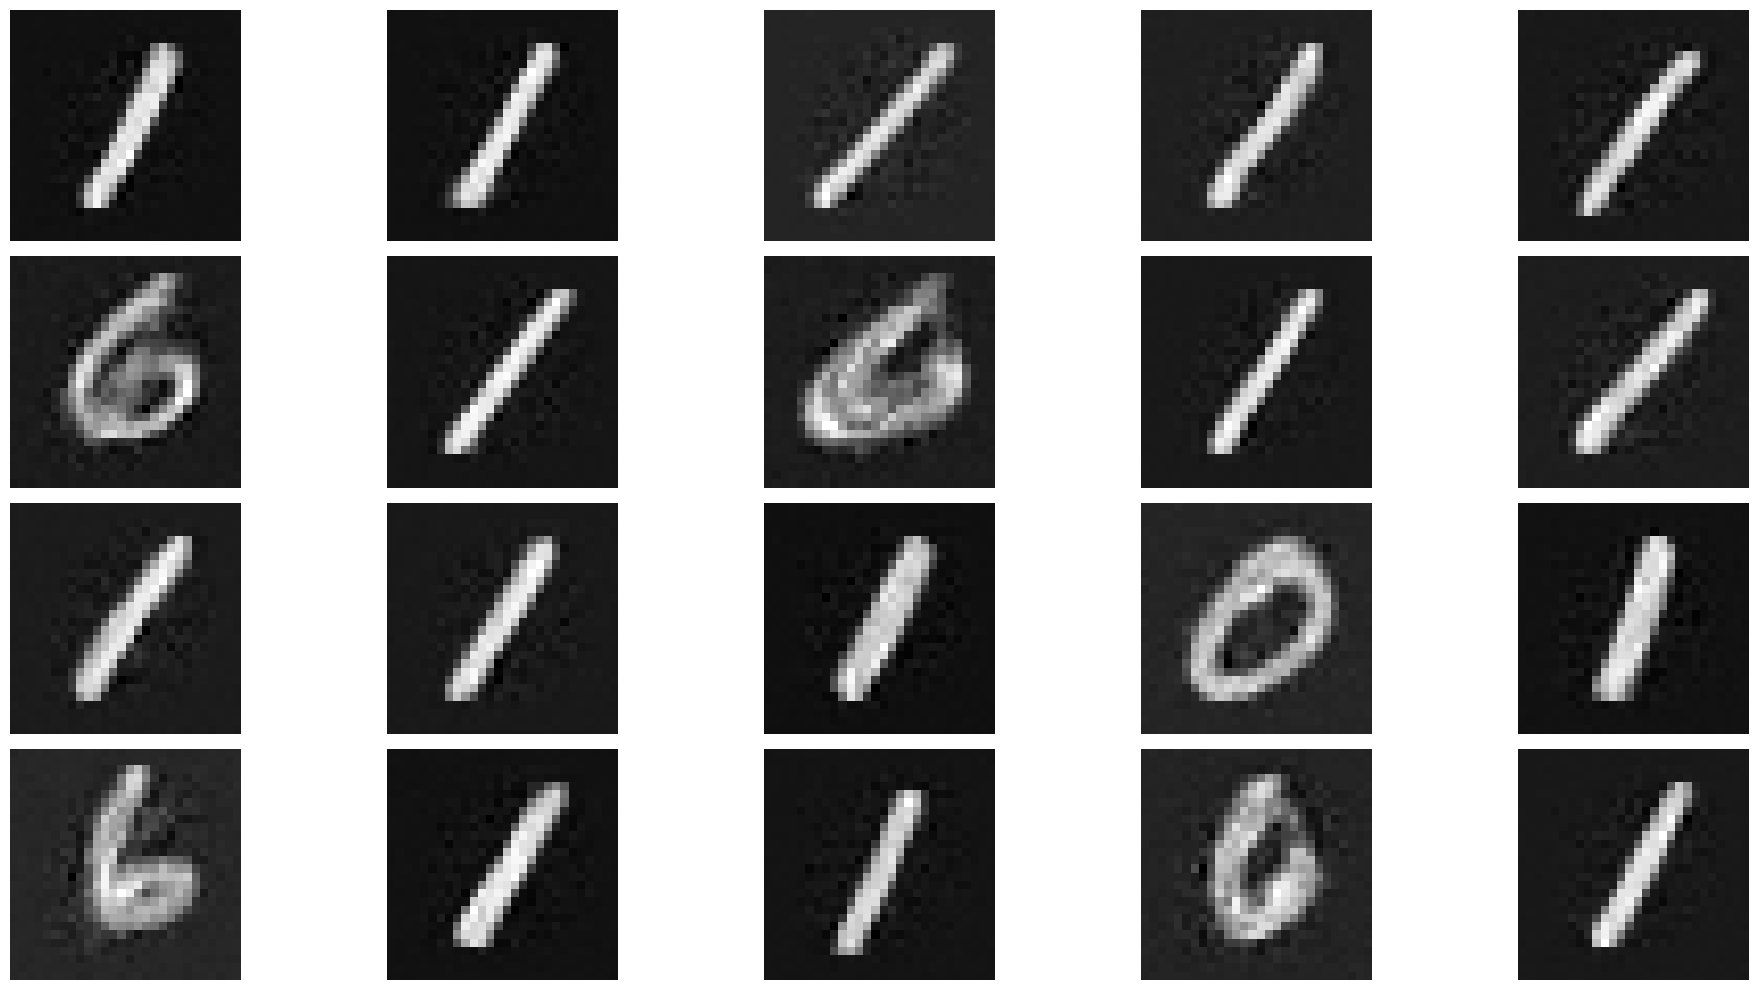

📈 Epoch 90 Summary:
   Train D Loss: 0.1241, Val D Loss: 0.3260
   Train G Loss: 7.6381, Val G Loss: 5.8889

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.241010	G_loss: 7.283255
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.156294	G_loss: 5.964675
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.049489	G_loss: 6.945971
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.049571	G_loss: 7.677332
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.247664	G_loss: 5.730167
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.236944	G_loss: 6.822368
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.132923	G_loss: 7.590977
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.237230	G_loss: 8.434618
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.044759	G_loss: 9.323581
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.043434	G_loss: 8.731539
====> Epoch: 91 Train D_loss: 0.1119, Train G_loss: 8.0264
====> Epoch: 91 Val D_loss: 0.3523, Val G_loss: 6.8411
📈 Epoch 91 Summary:
   Train D Loss: 0.1119, Val D Loss: 0.3523
   Train G Loss: 8.0264

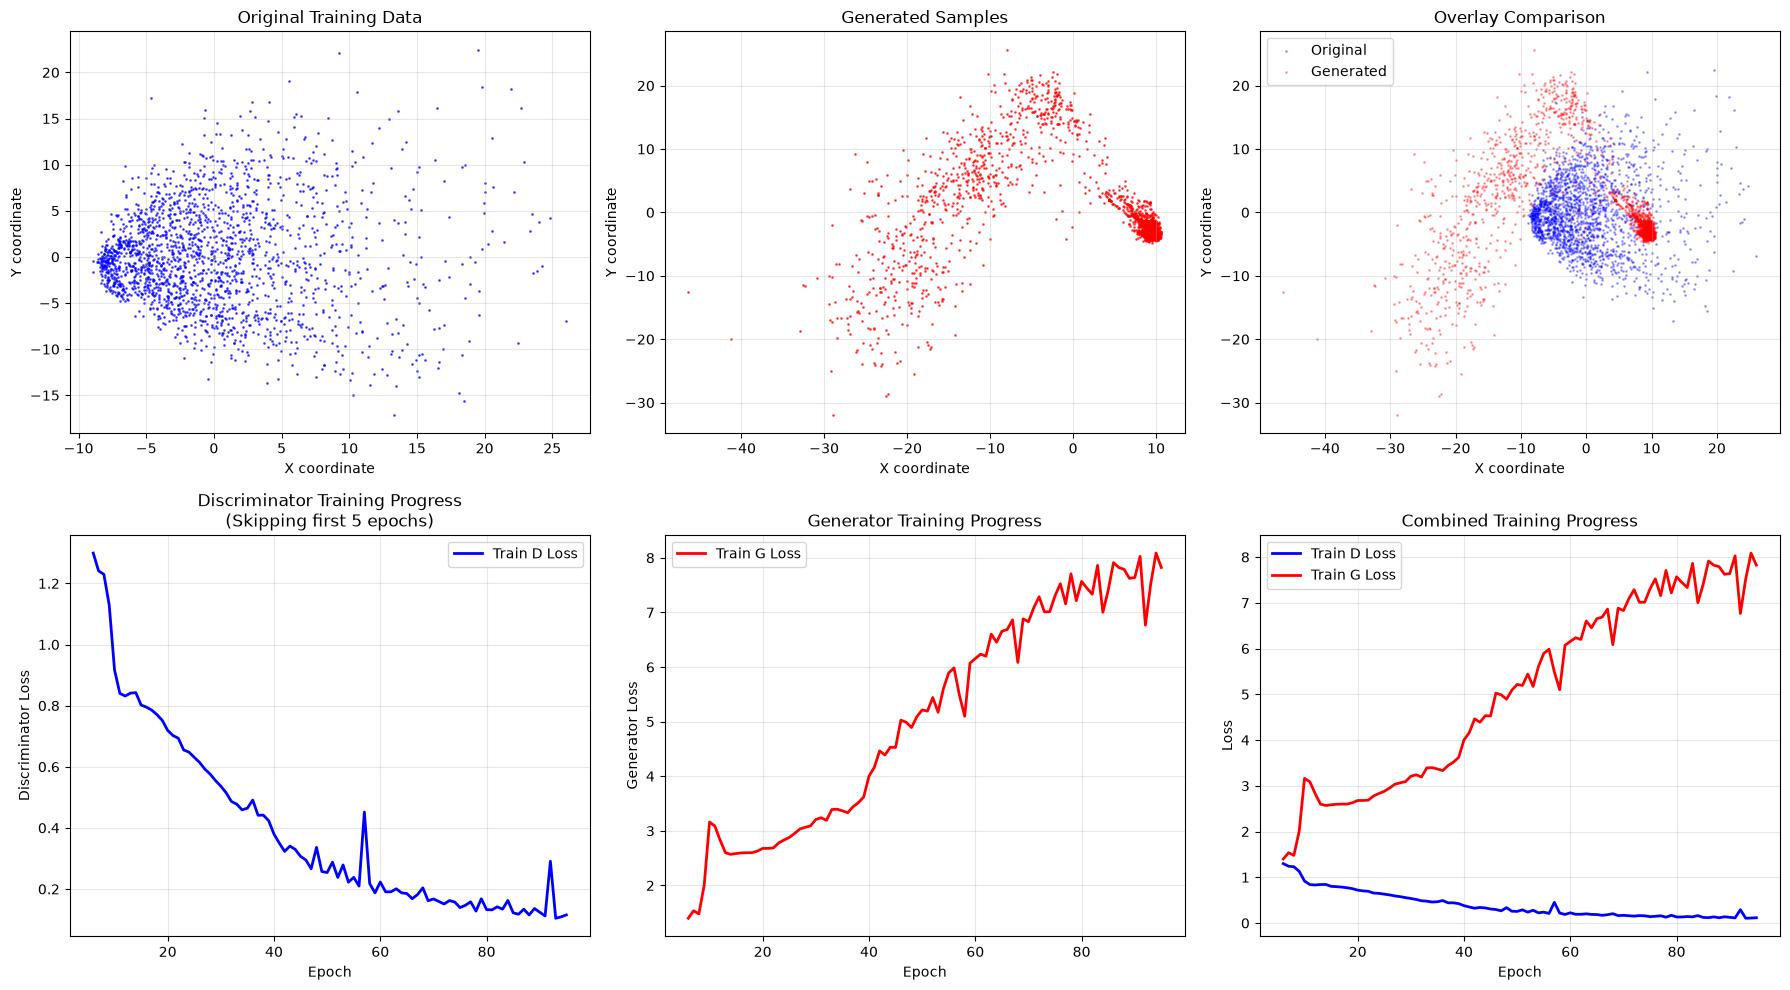

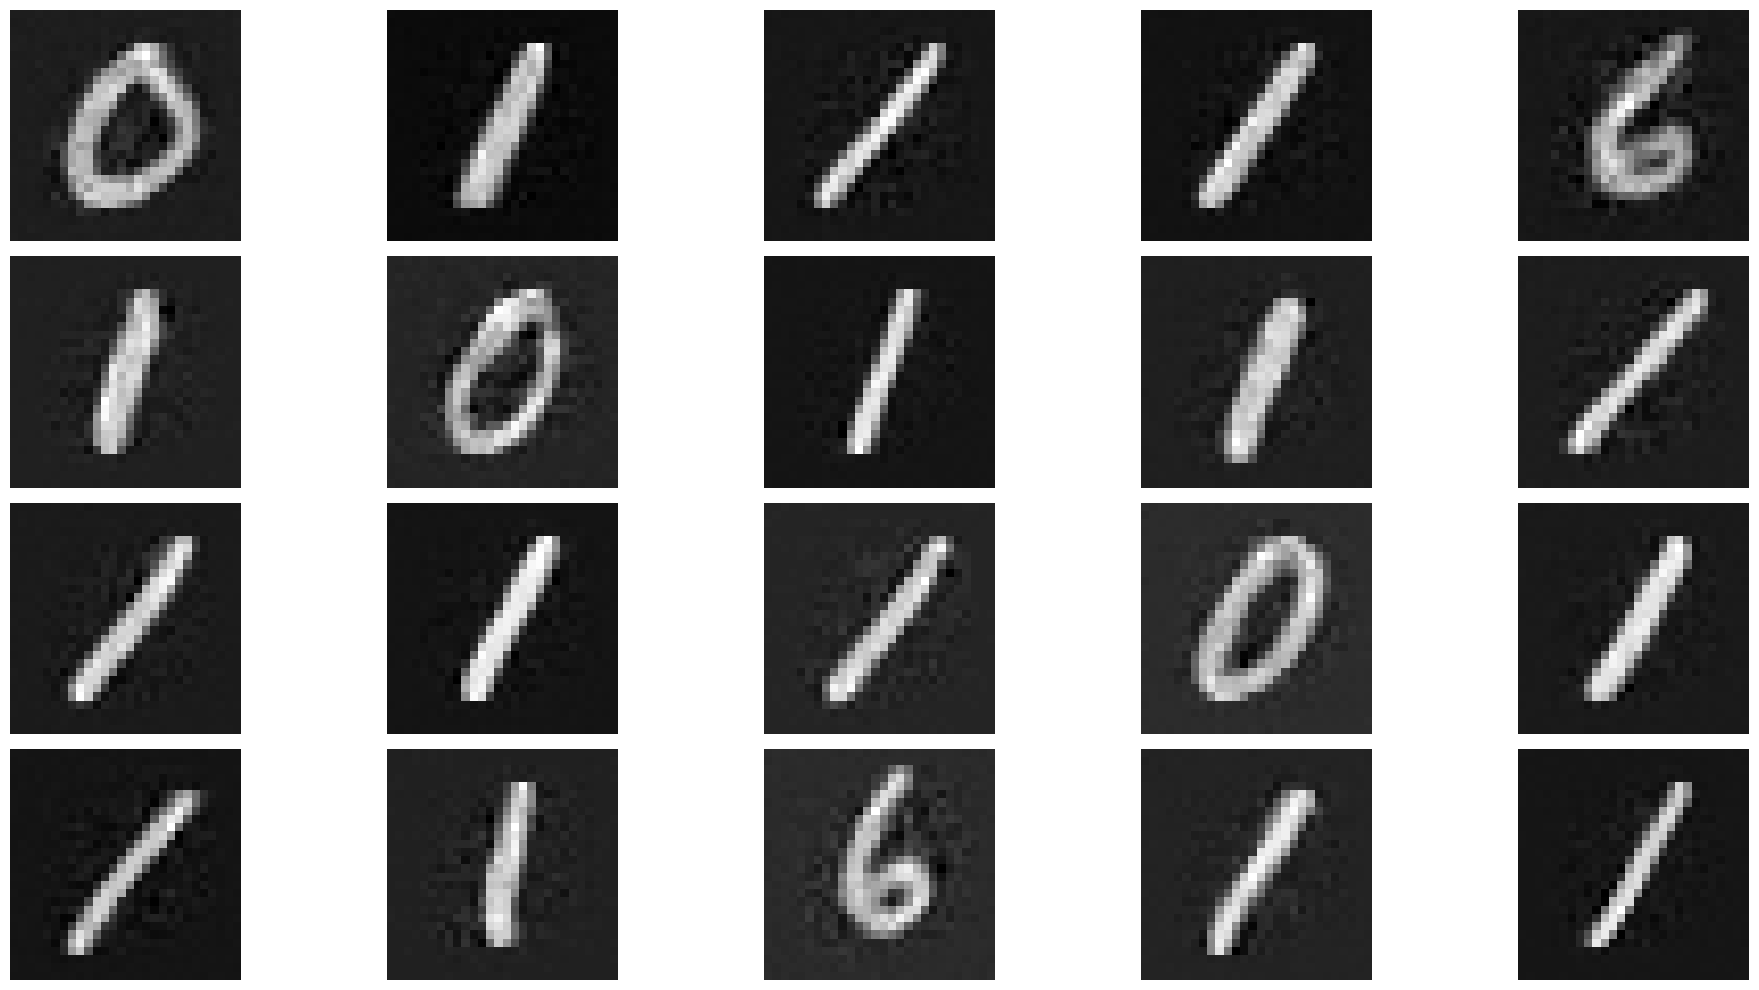

📈 Epoch 95 Summary:
   Train D Loss: 0.1153, Val D Loss: 0.2155
   Train G Loss: 7.8228, Val G Loss: 3.7698

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.136900	G_loss: 7.176144
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.063331	G_loss: 8.968437
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.079555	G_loss: 5.379979
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.159537	G_loss: 5.031053
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.082348	G_loss: 10.509345
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.190763	G_loss: 12.368027
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.066038	G_loss: 8.857740
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.014056	G_loss: 9.824339
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.247350	G_loss: 7.463560
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.183011	G_loss: 6.970600
====> Epoch: 96 Train D_loss: 0.1193, Train G_loss: 7.9743
====> Epoch: 96 Val D_loss: 0.3418, Val G_loss: 4.6513
📈 Epoch 96 Summary:
   Train D Loss: 0.1193, Val D Loss: 0.3418
   Train G Loss: 7.97

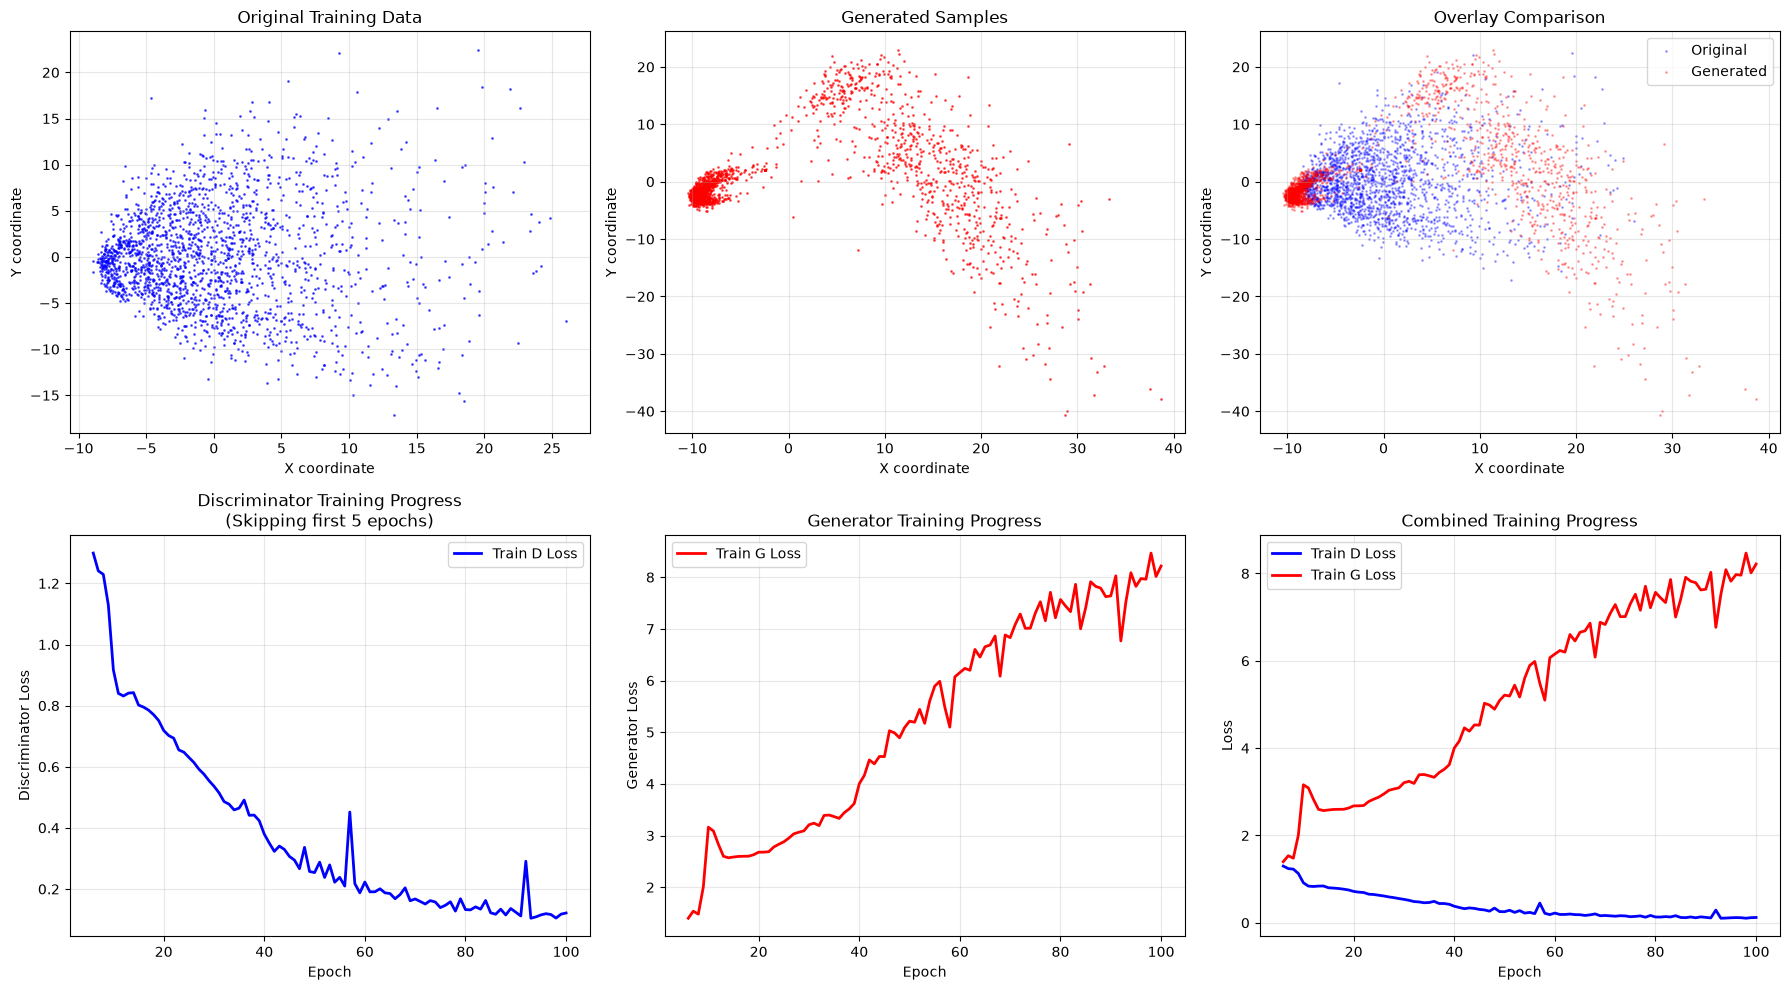

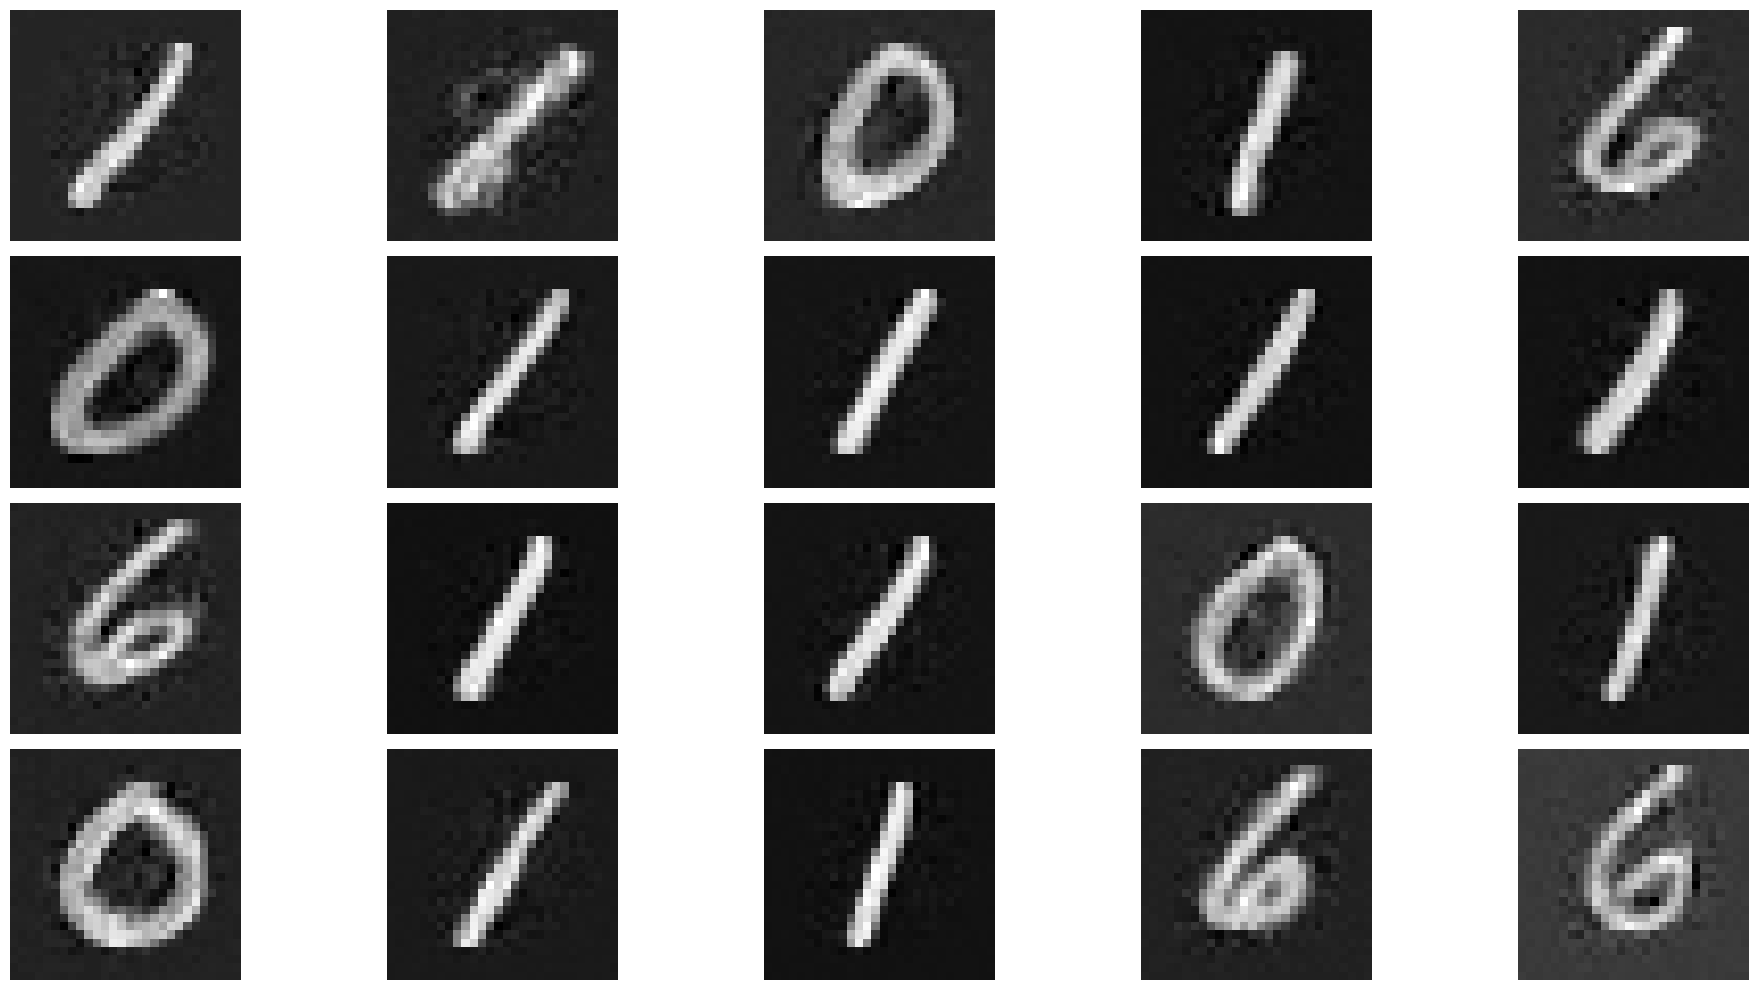

📈 Epoch 100 Summary:
   Train D Loss: 0.1215, Val D Loss: 0.2038
   Train G Loss: 8.2161, Val G Loss: 4.1861

🎉 Training completed!

🎨 Final comprehensive visualization:


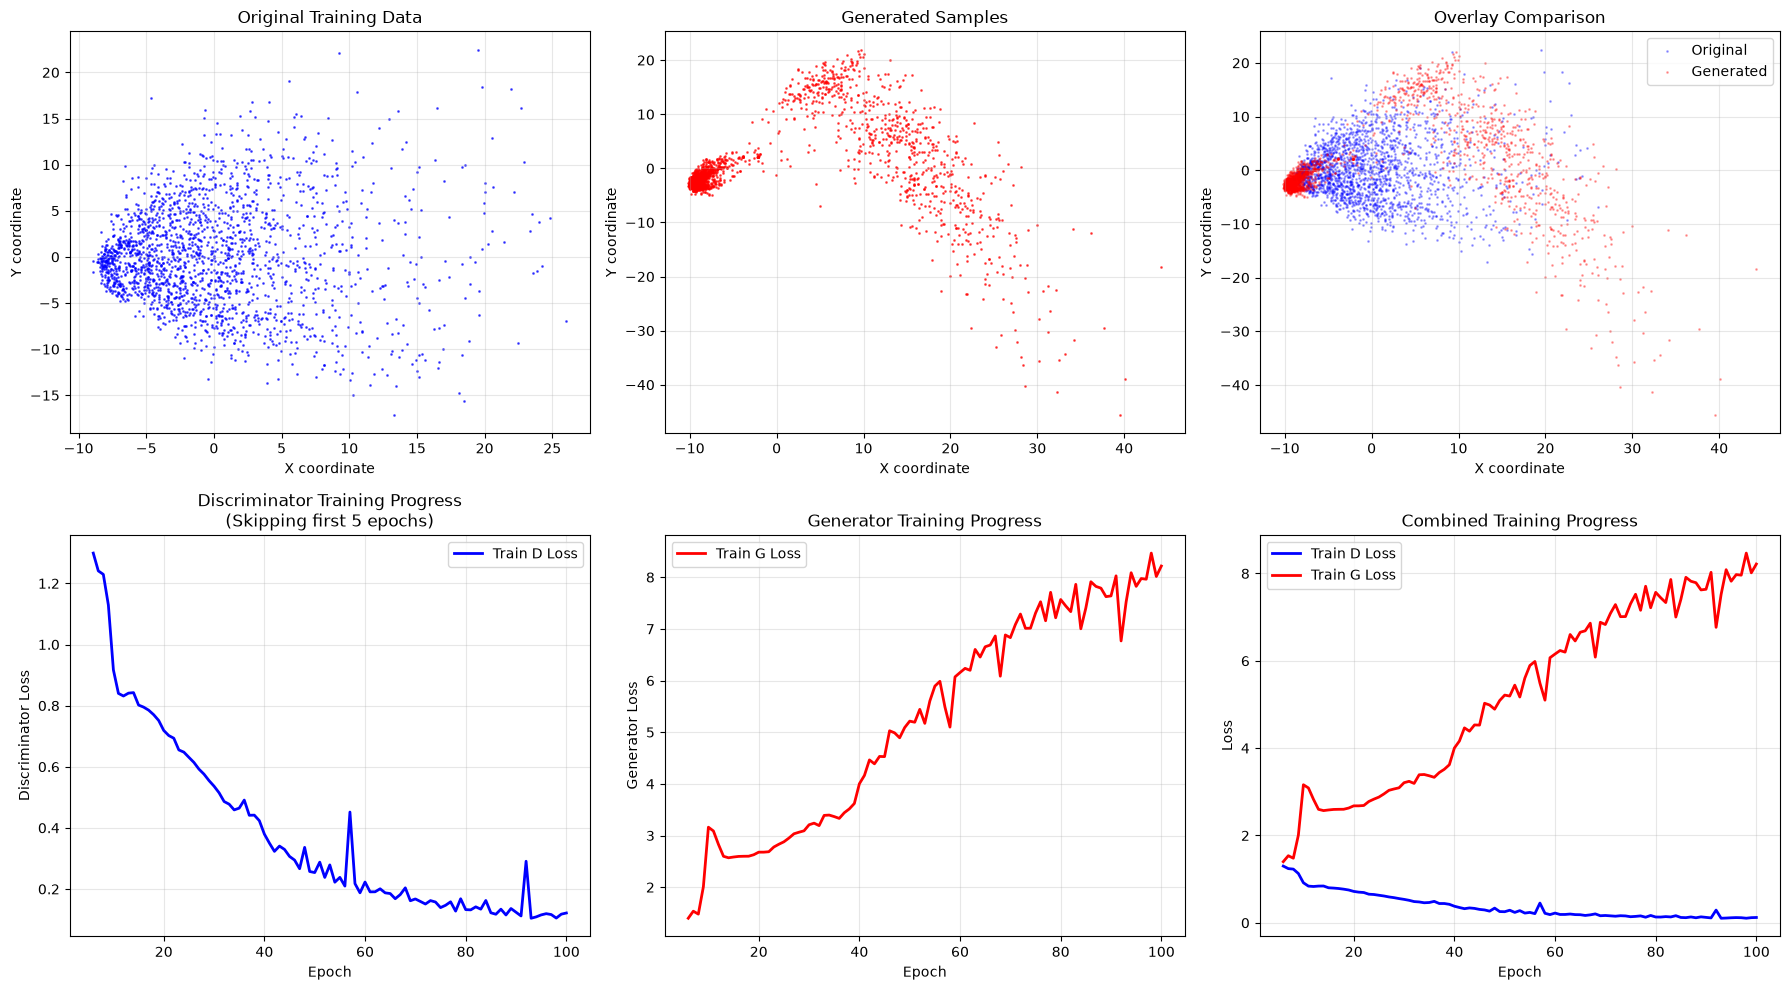

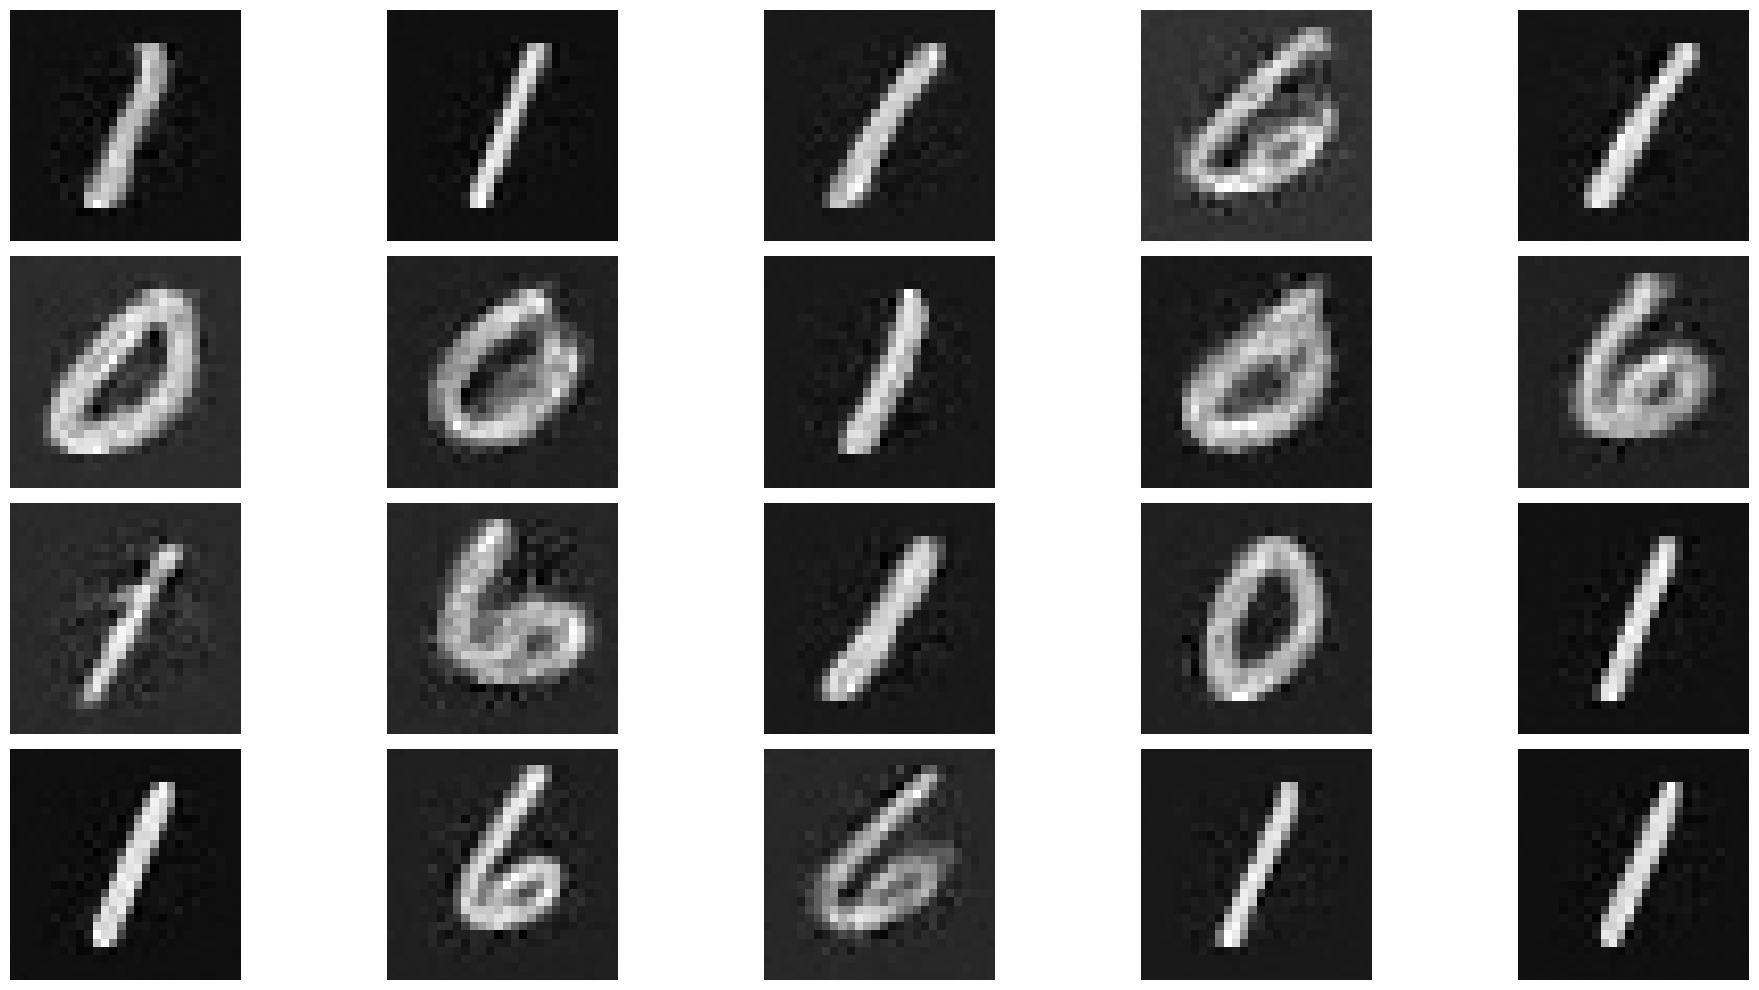

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


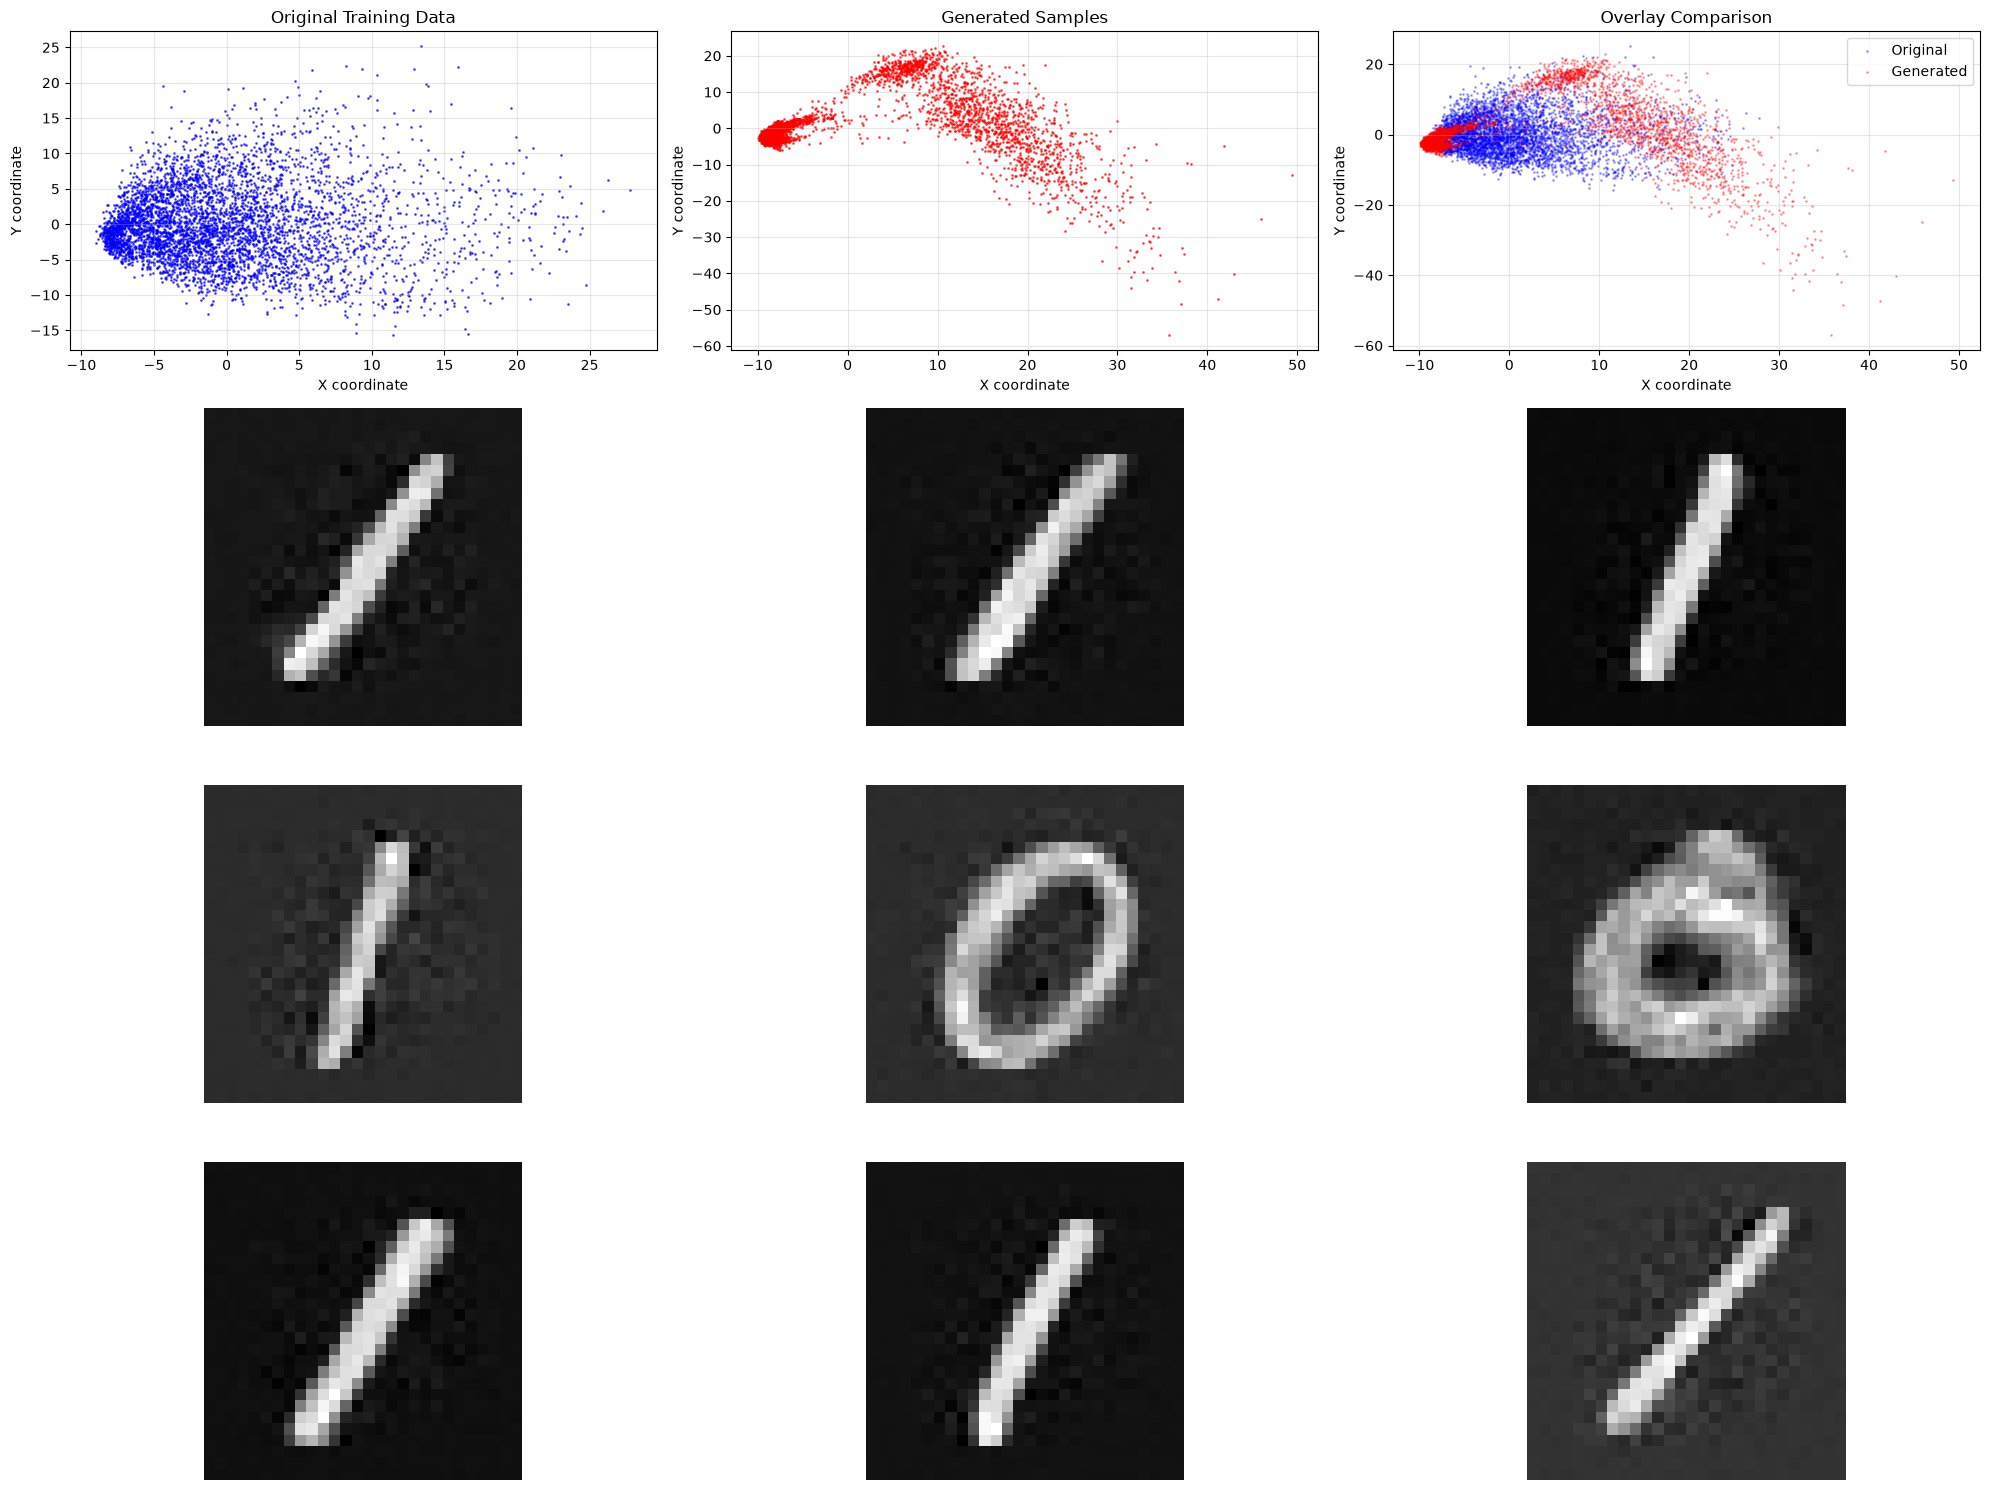

Real data confidence: 0.070
Fake data confidence: 0.072


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].to(device).float()
    real_batch = real_batch.reshape([100, INPUT_DIM])
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
